In [ ]:
# =============================================================================
# Proyecto: Análisis táctico de fútbol con un Modelo Oculto de Markov (HMM)
# Etapa 2: Implementación y validación del modelo
# Entorno: Google Colab (solo NumPy y Pandas)
# =============================================================================

from dataclasses import dataclass
import numpy as np

# -----------------------------------------------------------------------------
# 1. Definiciones del escenario base (parámetros originales, sin modificar)
# -----------------------------------------------------------------------------
ESTADOS = ("Defensiva", "Transición", "Ataque")        # S0, S1, S2
OBSERVACIONES = ("Pase corto", "Pase largo", "Tiro")   # O0, O1, O2

A_BASE = np.array([
    [0.60, 0.30, 0.10],   # desde Defensiva
    [0.30, 0.40, 0.30],   # desde Transición
    [0.20, 0.30, 0.50],   # desde Ataque
])

B_BASE = np.array([
    [0.70, 0.25, 0.05],   # emisiones en Defensiva
    [0.40, 0.50, 0.10],   # emisiones en Transición
    [0.30, 0.30, 0.40],   # emisiones en Ataque
])

PI_BASE = np.array([0.40, 0.40, 0.20])

TOL = 1e-9  # tolerancia absoluta para comprobar sumas iguales a 1


# -----------------------------------------------------------------------------
# 2. Clase HMM con validación matemática
# -----------------------------------------------------------------------------
@dataclass(frozen=True)
class HMM:
    """HMM discreto λ = (A, B, π).

    A  : matriz de transición (N x N), A[i, j] = P(S_{t+1}=j | S_t=i)
    B  : matriz de emisión    (N x M), B[i, k] = P(O_t=k | S_t=i)
    pi : distribución inicial (N,),    pi[i]  = P(S_1=i)

    Los arreglos internos son copias de solo lectura: no pueden modificarse
    accidentalmente después de crear el modelo.
    """
    A: np.ndarray
    B: np.ndarray
    pi: np.ndarray
    estados: tuple = ESTADOS
    observaciones: tuple = OBSERVACIONES

    def __post_init__(self):
        # Copias de tipo float, independientes de los arreglos originales.
        object.__setattr__(self, "A", np.array(self.A, dtype=float))
        object.__setattr__(self, "B", np.array(self.B, dtype=float))
        object.__setattr__(self, "pi", np.array(self.pi, dtype=float))
        self.validar()
        # Se bloquea la escritura solo cuando el modelo ya es válido.
        self.A.setflags(write=False)
        self.B.setflags(write=False)
        self.pi.setflags(write=False)

    # --- Propiedades de tamaño ---
    @property
    def N(self) -> int:
        """Número de estados ocultos."""
        return self.A.shape[0]

    @property
    def M(self) -> int:
        """Número de observaciones distintas."""
        return self.B.shape[1]

    # --- Validación ---
    def validar(self) -> None:
        """Lanza ValueError si el modelo no cumple las propiedades requeridas."""
        N = len(self.estados)
        M = len(self.observaciones)

        # 1) Dimensiones
        if self.A.shape != (N, N):
            raise ValueError(f"A debe ser {N}x{N}; se recibió {self.A.shape}.")
        if self.B.shape != (N, M):
            raise ValueError(f"B debe ser {N}x{M}; se recibió {self.B.shape}.")
        if self.pi.shape != (N,):
            raise ValueError(f"pi debe tener longitud {N}; se recibió {self.pi.shape}.")

        # 2) Valores finitos y 3) no negativos
        for nombre, arr in (("A", self.A), ("B", self.B), ("pi", self.pi)):
            if not np.all(np.isfinite(arr)):
                raise ValueError(f"{nombre} contiene valores no finitos (NaN/inf).")
            if np.any(arr < 0):
                raise ValueError(f"{nombre} contiene probabilidades negativas.")

        # 4) Sumas iguales a 1 (rtol=0.0: solo se aplica la tolerancia absoluta)
        for nombre, arr in (("A", self.A), ("B", self.B)):
            sumas = arr.sum(axis=1)
            if not np.allclose(sumas, 1.0, rtol=0.0, atol=TOL):
                raise ValueError(f"Las filas de {nombre} deben sumar 1; suman {sumas}.")
        if not np.isclose(self.pi.sum(), 1.0, rtol=0.0, atol=TOL):
            raise ValueError(f"pi debe sumar 1; suma {self.pi.sum():.12f}.")

    # --- Verificación matemática adicional ---
    def distribucion_estacionaria(self) -> np.ndarray:
        """Distribución π* que cumple π* A = π* (comportamiento a largo plazo).

        Es el autovector izquierdo de A con autovalor 1, normalizado a suma 1.
        No representa los porcentajes exactos de un partido de 90 minutos.
        """
        valores, vectores = np.linalg.eig(self.A.T)
        k = np.argmin(np.abs(valores - 1.0))
        v = np.real(vectores[:, k])
        return v / v.sum()

    # --- Presentación ---
    def resumen(self) -> None:
        """Imprime los parámetros del modelo y su verificación."""
        import pandas as pd
        print(f"HMM discreto: N={self.N} estados, M={self.M} observaciones\n")
        print("Distribución inicial π:")
        print(pd.Series(self.pi, index=self.estados).round(4).to_string(), "\n")
        print("Matriz de transición A:")
        print(pd.DataFrame(self.A, index=self.estados, columns=self.estados), "\n")
        print("Matriz de emisión B:")
        print(pd.DataFrame(self.B, index=self.estados, columns=self.observaciones), "\n")
        print("Suma de filas de A:", self.A.sum(axis=1))
        print("Suma de filas de B:", self.B.sum(axis=1))
        print("Suma de π:", self.pi.sum(), "\n")
        print("Distribución estacionaria π* (largo plazo, no un partido de 90 min):")
        print(pd.Series(self.distribucion_estacionaria(), index=self.estados).round(4).to_string())


def crear_modelo_base() -> HMM:
    """Devuelve el HMM del escenario base (parámetros originales)."""
    return HMM(A=A_BASE, B=B_BASE, pi=PI_BASE)


# -----------------------------------------------------------------------------
# 3. Ejecución de la etapa
# -----------------------------------------------------------------------------
modelo = crear_modelo_base()
modelo.resumen()
print("\nModelo válido.")

HMM discreto: N=3 estados, M=3 observaciones

Distribución inicial π:
Defensiva     0.4
Transición    0.4
Ataque        0.2 

Matriz de transición A:
            Defensiva  Transición  Ataque
Defensiva         0.6         0.3     0.1
Transición        0.3         0.4     0.3
Ataque            0.2         0.3     0.5 

Matriz de emisión B:
            Pase corto  Pase largo  Tiro
Defensiva          0.7        0.25  0.05
Transición         0.4        0.50  0.10
Ataque             0.3        0.30  0.40 

Suma de filas de A: [1. 1. 1.]
Suma de filas de B: [1. 1. 1.]
Suma de π: 1.0 

Distribución estacionaria π* (largo plazo, no un partido de 90 min):
Defensiva     0.3889
Transición    0.3333
Ataque        0.2778

Modelo válido.


In [ ]:
# =============================================================================
# Proyecto: Análisis táctico de fútbol con un Modelo Oculto de Markov (HMM)
# Etapa 3: Simulación del partido (estados, posesión y observaciones)
# Entorno: Google Colab (solo NumPy y Pandas)
# =============================================================================

from dataclasses import dataclass
import numpy as np
import pandas as pd

# -----------------------------------------------------------------------------
# 1. Parámetros del HMM (escenario base, sin modificar)
# -----------------------------------------------------------------------------
ESTADOS = ("Defensiva", "Transición", "Ataque")        # S0, S1, S2
OBSERVACIONES = ("Pase corto", "Pase largo", "Tiro")   # O0, O1, O2

A_BASE = np.array([
    [0.60, 0.30, 0.10],   # desde Defensiva
    [0.30, 0.40, 0.30],   # desde Transición
    [0.20, 0.30, 0.50],   # desde Ataque
])

B_BASE = np.array([
    [0.70, 0.25, 0.05],   # emisiones en Defensiva
    [0.40, 0.50, 0.10],   # emisiones en Transición
    [0.30, 0.30, 0.40],   # emisiones en Ataque
])

PI_BASE = np.array([0.40, 0.40, 0.20])

TOL = 1e-9  # tolerancia absoluta para comprobar sumas iguales a 1


# -----------------------------------------------------------------------------
# 2. Clase HMM con validación matemática (Etapa 2, sin cambios)
# -----------------------------------------------------------------------------
@dataclass(frozen=True)
class HMM:
    """HMM discreto λ = (A, B, π).

    A  : matriz de transición (N x N), A[i, j] = P(S_{t+1}=j | S_t=i)
    B  : matriz de emisión    (N x M), B[i, k] = P(O_t=k | S_t=i)
    pi : distribución inicial (N,),    pi[i]  = P(S_1=i)

    Los arreglos internos son copias de solo lectura: no pueden modificarse
    accidentalmente después de crear el modelo.
    """
    A: np.ndarray
    B: np.ndarray
    pi: np.ndarray
    estados: tuple = ESTADOS
    observaciones: tuple = OBSERVACIONES

    def __post_init__(self):
        # Copias de tipo float, independientes de los arreglos originales.
        object.__setattr__(self, "A", np.array(self.A, dtype=float))
        object.__setattr__(self, "B", np.array(self.B, dtype=float))
        object.__setattr__(self, "pi", np.array(self.pi, dtype=float))
        self.validar()
        # Se bloquea la escritura solo cuando el modelo ya es válido.
        self.A.setflags(write=False)
        self.B.setflags(write=False)
        self.pi.setflags(write=False)

    @property
    def N(self) -> int:
        """Número de estados ocultos."""
        return self.A.shape[0]

    @property
    def M(self) -> int:
        """Número de observaciones distintas."""
        return self.B.shape[1]

    def validar(self) -> None:
        """Lanza ValueError si el modelo no cumple las propiedades requeridas."""
        N = len(self.estados)
        M = len(self.observaciones)

        # 1) Dimensiones
        if self.A.shape != (N, N):
            raise ValueError(f"A debe ser {N}x{N}; se recibió {self.A.shape}.")
        if self.B.shape != (N, M):
            raise ValueError(f"B debe ser {N}x{M}; se recibió {self.B.shape}.")
        if self.pi.shape != (N,):
            raise ValueError(f"pi debe tener longitud {N}; se recibió {self.pi.shape}.")

        # 2) Valores finitos y 3) no negativos
        for nombre, arr in (("A", self.A), ("B", self.B), ("pi", self.pi)):
            if not np.all(np.isfinite(arr)):
                raise ValueError(f"{nombre} contiene valores no finitos (NaN/inf).")
            if np.any(arr < 0):
                raise ValueError(f"{nombre} contiene probabilidades negativas.")

        # 4) Sumas iguales a 1 (rtol=0.0: solo se aplica la tolerancia absoluta)
        for nombre, arr in (("A", self.A), ("B", self.B)):
            sumas = arr.sum(axis=1)
            if not np.allclose(sumas, 1.0, rtol=0.0, atol=TOL):
                raise ValueError(f"Las filas de {nombre} deben sumar 1; suman {sumas}.")
        if not np.isclose(self.pi.sum(), 1.0, rtol=0.0, atol=TOL):
            raise ValueError(f"pi debe sumar 1; suma {self.pi.sum():.12f}.")

    def distribucion_estacionaria(self) -> np.ndarray:
        """Distribución π* que cumple π* A = π* (comportamiento a largo plazo).

        No representa los porcentajes exactos de un partido de 90 minutos.
        """
        valores, vectores = np.linalg.eig(self.A.T)
        k = np.argmin(np.abs(valores - 1.0))
        v = np.real(vectores[:, k])
        return v / v.sum()


def crear_modelo_base() -> HMM:
    """Devuelve el HMM del escenario base (parámetros originales)."""
    return HMM(A=A_BASE, B=B_BASE, pi=PI_BASE)


# -----------------------------------------------------------------------------
# 3. Parámetros de posesión (separados de A, B y π)
#    SUPUESTOS DEL MODELO, no estimados a partir de partidos reales.
# -----------------------------------------------------------------------------
EQUIPOS = ("Equipo A", "Equipo B")   # A = equipo analizado, B = rival
EQUIPO_A, EQUIPO_B = 0, 1
OBS_AUSENTE = -1                     # código de observación ausente
MINUTOS = 90
SEMILLA_BASE = 42


@dataclass(frozen=True)
class ParamsPosesion:
    """Cadena de Markov de dos estados para la posesión (independiente de la fase)."""
    p_inicial_A: float = 0.50    # P(el equipo A tiene el balón en el minuto 1)
    p_mantener_A: float = 0.70   # P(A conserva el balón | A lo tiene)
    p_mantener_B: float = 0.70   # P(B conserva el balón | B lo tiene)

    def __post_init__(self):
        for nombre in ("p_inicial_A", "p_mantener_A", "p_mantener_B"):
            valor = getattr(self, nombre)
            if not np.isfinite(valor) or not (0.0 <= valor <= 1.0):
                raise ValueError(f"{nombre} debe estar en [0, 1]; se recibió {valor}.")

    @property
    def pi_posesion(self) -> np.ndarray:
        """Distribución inicial de la posesión: [P(A), P(B)]."""
        return np.array([self.p_inicial_A, 1.0 - self.p_inicial_A])

    @property
    def matriz(self) -> np.ndarray:
        """Matriz de transición de la posesión (filas: quién tiene el balón ahora)."""
        return np.array([
            [self.p_mantener_A, 1.0 - self.p_mantener_A],   # desde A
            [1.0 - self.p_mantener_B, self.p_mantener_B],   # desde B
        ])


PARAMS_POSESION = ParamsPosesion()


# -----------------------------------------------------------------------------
# 4. Simulación del partido
# -----------------------------------------------------------------------------
@dataclass(frozen=True)
class Partido:
    """Resultado de simular un partido (arreglos de solo lectura)."""
    semilla: int
    estados: np.ndarray        # estado táctico real del equipo A (0, 1, 2)
    posesion: np.ndarray       # 0 = Equipo A, 1 = Equipo B
    observaciones: np.ndarray  # 0, 1, 2 con posesión de A; -1 si A no tiene el balón

    def __post_init__(self):
        for arr in (self.estados, self.posesion, self.observaciones):
            arr.setflags(write=False)


def _muestrear(rng: np.random.Generator, probs: np.ndarray) -> int:
    """Sortea un índice según el vector de probabilidades `probs`."""
    return int(rng.choice(len(probs), p=probs))


def simular_estados(modelo: HMM, T: int, rng: np.random.Generator) -> np.ndarray:
    """S_1 ~ π y S_{t+1} ~ A[S_t, :]."""
    estados = np.empty(T, dtype=int)
    estados[0] = _muestrear(rng, modelo.pi)
    for t in range(1, T):
        estados[t] = _muestrear(rng, modelo.A[estados[t - 1]])
    return estados


def simular_posesion(params: ParamsPosesion, T: int, rng: np.random.Generator) -> np.ndarray:
    """Cadena de Markov de dos estados, independiente de la fase táctica."""
    posesion = np.empty(T, dtype=int)
    posesion[0] = _muestrear(rng, params.pi_posesion)
    for t in range(1, T):
        posesion[t] = _muestrear(rng, params.matriz[posesion[t - 1]])
    return posesion


def simular_observaciones(modelo: HMM, estados: np.ndarray, posesion: np.ndarray,
                          rng: np.random.Generator) -> np.ndarray:
    """O_t ~ B[S_t, :] solo si el equipo A tiene el balón; si no, observación ausente (-1)."""
    obs = np.full(len(estados), OBS_AUSENTE, dtype=int)
    for t in range(len(estados)):
        if posesion[t] == EQUIPO_A:
            obs[t] = _muestrear(rng, modelo.B[estados[t]])
    return obs


def validar_partido(modelo: HMM, p: Partido, T: int = MINUTOS) -> None:
    """Comprueba la consistencia de la simulación; lanza ValueError si falla."""
    if not (len(p.estados) == len(p.posesion) == len(p.observaciones) == T):
        raise ValueError(f"Las tres secuencias deben tener longitud {T}.")
    if not np.all(np.isin(p.estados, range(modelo.N))):
        raise ValueError("Hay estados fuera de rango.")
    if not np.all(np.isin(p.posesion, (EQUIPO_A, EQUIPO_B))):
        raise ValueError("Hay valores de posesión inválidos.")
    if not np.all(p.observaciones[p.posesion == EQUIPO_B] == OBS_AUSENTE):
        raise ValueError("Hay observaciones asignadas cuando A no tiene el balón.")
    if not np.all(np.isin(p.observaciones[p.posesion == EQUIPO_A], range(modelo.M))):
        raise ValueError("Hay observaciones ausentes o inválidas cuando A tiene el balón.")


def simular_partido(modelo: HMM, params_posesion: ParamsPosesion = PARAMS_POSESION,
                    semilla: int = SEMILLA_BASE, T: int = MINUTOS) -> Partido:
    """Simula un partido de T minutos (una acción por minuto).

    Una semilla maestra genera dos generadores independientes:
      - rng_hmm: estados ocultos y observaciones
      - rng_pos: posesión
    Orden: estados -> posesión -> observaciones (solo con posesión de A).
    """
    ss_hmm, ss_pos = np.random.SeedSequence(semilla).spawn(2)
    rng_hmm = np.random.default_rng(ss_hmm)
    rng_pos = np.random.default_rng(ss_pos)

    estados = simular_estados(modelo, T, rng_hmm)
    posesion = simular_posesion(params_posesion, T, rng_pos)
    observaciones = simular_observaciones(modelo, estados, posesion, rng_hmm)

    partido = Partido(semilla=semilla, estados=estados, posesion=posesion,
                      observaciones=observaciones)
    validar_partido(modelo, partido, T)
    return partido


# -----------------------------------------------------------------------------
# 5. Resumen y tabla de los primeros minutos
# -----------------------------------------------------------------------------
def resumen_partido(modelo: HMM, p: Partido) -> None:
    """Imprime un resumen descriptivo de la simulación (no son métricas finales)."""
    T = len(p.estados)
    print(f"Partido simulado: {T} minutos, semilla = {p.semilla}")
    print("(Datos simulados; no son datos reales de partidos.)\n")

    print("Minutos en cada fase táctica real del equipo A:")
    for i, nombre in enumerate(modelo.estados):
        n = int(np.sum(p.estados == i))
        print(f"  {nombre:<11}: {n:>2} min ({100 * n / T:5.1f} %)")

    print("\nPosesión:")
    for i, nombre in enumerate(EQUIPOS):
        n = int(np.sum(p.posesion == i))
        print(f"  {nombre}: {n:>2} min ({100 * n / T:5.1f} %)")

    con_obs = p.observaciones != OBS_AUSENTE
    print(f"\nObservaciones del equipo A: {int(con_obs.sum())} presentes, "
          f"{int((~con_obs).sum())} ausentes (-1)")
    for k, nombre in enumerate(modelo.observaciones):
        print(f"  {nombre:<10}: {int(np.sum(p.observaciones == k))}")


def tabla_primeros_minutos(modelo: HMM, p: Partido, n: int = 15) -> pd.DataFrame:
    """Tabla con los primeros n minutos de la simulación."""
    filas = []
    for t in range(n):
        o = p.observaciones[t]
        filas.append({
            "Minuto": t + 1,
            "Estado táctico real (A)": modelo.estados[p.estados[t]],
            "Posesión": EQUIPOS[p.posesion[t]],
            "Acción observada": "— (sin observación)" if o == OBS_AUSENTE
                                else modelo.observaciones[o],
        })
    return pd.DataFrame(filas).set_index("Minuto")


# -----------------------------------------------------------------------------
# 6. Ejecución de la etapa
# -----------------------------------------------------------------------------
modelo = crear_modelo_base()
print("Modelo válido (A, B y π originales).\n")

partido = simular_partido(modelo, PARAMS_POSESION, semilla=SEMILLA_BASE)
resumen_partido(modelo, partido)

print("\nPrimeros 15 minutos:")
print(tabla_primeros_minutos(modelo, partido, n=15).to_string())

Modelo válido (A, B y π originales).

Partido simulado: 90 minutos, semilla = 42
(Datos simulados; no son datos reales de partidos.)

Minutos en cada fase táctica real del equipo A:
  Defensiva  : 39 min ( 43.3 %)
  Transición : 22 min ( 24.4 %)
  Ataque     : 29 min ( 32.2 %)

Posesión:
  Equipo A: 37 min ( 41.1 %)
  Equipo B: 53 min ( 58.9 %)

Observaciones del equipo A: 37 presentes, 53 ausentes (-1)
  Pase corto: 15
  Pase largo: 17
  Tiro      : 5

Primeros 15 minutos:
       Estado táctico real (A)  Posesión     Acción observada
Minuto                                                       
1                       Ataque  Equipo A           Pase largo
2                       Ataque  Equipo A           Pase corto
3                       Ataque  Equipo A           Pase corto
4                   Transición  Equipo A           Pase largo
5                       Ataque  Equipo B  — (sin observación)
6                    Defensiva  Equipo B  — (sin observación)
7                       A

In [ ]:
# =============================================================================
# Proyecto: Análisis táctico de fútbol con un Modelo Oculto de Markov (HMM)
# Etapa 4: Algoritmo de Viterbi (reconstrucción de fases tácticas)
# Entorno: Google Colab (solo NumPy y Pandas)
# =============================================================================

from dataclasses import dataclass
import numpy as np
import pandas as pd

# -----------------------------------------------------------------------------
# 1. Parámetros del HMM (escenario base, sin modificar)
# -----------------------------------------------------------------------------
ESTADOS = ("Defensiva", "Transición", "Ataque")        # S0, S1, S2
OBSERVACIONES = ("Pase corto", "Pase largo", "Tiro")   # O0, O1, O2

A_BASE = np.array([
    [0.60, 0.30, 0.10],   # desde Defensiva
    [0.30, 0.40, 0.30],   # desde Transición
    [0.20, 0.30, 0.50],   # desde Ataque
])

B_BASE = np.array([
    [0.70, 0.25, 0.05],   # emisiones en Defensiva
    [0.40, 0.50, 0.10],   # emisiones en Transición
    [0.30, 0.30, 0.40],   # emisiones en Ataque
])

PI_BASE = np.array([0.40, 0.40, 0.20])

TOL = 1e-9  # tolerancia absoluta para comprobar sumas iguales a 1


# -----------------------------------------------------------------------------
# 2. Clase HMM con validación matemática (Etapa 2, sin cambios)
# -----------------------------------------------------------------------------
@dataclass(frozen=True)
class HMM:
    """HMM discreto λ = (A, B, π).

    A  : matriz de transición (N x N), A[i, j] = P(S_{t+1}=j | S_t=i)
    B  : matriz de emisión    (N x M), B[i, k] = P(O_t=k | S_t=i)
    pi : distribución inicial (N,),    pi[i]  = P(S_1=i)

    Los arreglos internos son copias de solo lectura: no pueden modificarse
    accidentalmente después de crear el modelo.
    """
    A: np.ndarray
    B: np.ndarray
    pi: np.ndarray
    estados: tuple = ESTADOS
    observaciones: tuple = OBSERVACIONES

    def __post_init__(self):
        # Copias de tipo float, independientes de los arreglos originales.
        object.__setattr__(self, "A", np.array(self.A, dtype=float))
        object.__setattr__(self, "B", np.array(self.B, dtype=float))
        object.__setattr__(self, "pi", np.array(self.pi, dtype=float))
        self.validar()
        # Se bloquea la escritura solo cuando el modelo ya es válido.
        self.A.setflags(write=False)
        self.B.setflags(write=False)
        self.pi.setflags(write=False)

    @property
    def N(self) -> int:
        """Número de estados ocultos."""
        return self.A.shape[0]

    @property
    def M(self) -> int:
        """Número de observaciones distintas."""
        return self.B.shape[1]

    def validar(self) -> None:
        """Lanza ValueError si el modelo no cumple las propiedades requeridas."""
        N = len(self.estados)
        M = len(self.observaciones)

        # 1) Dimensiones
        if self.A.shape != (N, N):
            raise ValueError(f"A debe ser {N}x{N}; se recibió {self.A.shape}.")
        if self.B.shape != (N, M):
            raise ValueError(f"B debe ser {N}x{M}; se recibió {self.B.shape}.")
        if self.pi.shape != (N,):
            raise ValueError(f"pi debe tener longitud {N}; se recibió {self.pi.shape}.")

        # 2) Valores finitos y 3) no negativos
        for nombre, arr in (("A", self.A), ("B", self.B), ("pi", self.pi)):
            if not np.all(np.isfinite(arr)):
                raise ValueError(f"{nombre} contiene valores no finitos (NaN/inf).")
            if np.any(arr < 0):
                raise ValueError(f"{nombre} contiene probabilidades negativas.")

        # 4) Sumas iguales a 1 (rtol=0.0: solo se aplica la tolerancia absoluta)
        for nombre, arr in (("A", self.A), ("B", self.B)):
            sumas = arr.sum(axis=1)
            if not np.allclose(sumas, 1.0, rtol=0.0, atol=TOL):
                raise ValueError(f"Las filas de {nombre} deben sumar 1; suman {sumas}.")
        if not np.isclose(self.pi.sum(), 1.0, rtol=0.0, atol=TOL):
            raise ValueError(f"pi debe sumar 1; suma {self.pi.sum():.12f}.")

    def distribucion_estacionaria(self) -> np.ndarray:
        """Distribución π* que cumple π* A = π* (comportamiento a largo plazo).

        No representa los porcentajes exactos de un partido de 90 minutos.
        """
        valores, vectores = np.linalg.eig(self.A.T)
        k = np.argmin(np.abs(valores - 1.0))
        v = np.real(vectores[:, k])
        return v / v.sum()


def crear_modelo_base() -> HMM:
    """Devuelve el HMM del escenario base (parámetros originales)."""
    return HMM(A=A_BASE, B=B_BASE, pi=PI_BASE)


# -----------------------------------------------------------------------------
# 3. Parámetros de posesión (separados de A, B y π)
#    SUPUESTOS DEL MODELO, no estimados a partir de partidos reales.
# -----------------------------------------------------------------------------
EQUIPOS = ("Equipo A", "Equipo B")   # A = equipo analizado, B = rival
EQUIPO_A, EQUIPO_B = 0, 1
OBS_AUSENTE = -1                     # código de observación ausente
MINUTOS = 90
SEMILLA_BASE = 42


@dataclass(frozen=True)
class ParamsPosesion:
    """Cadena de Markov de dos estados para la posesión (independiente de la fase)."""
    p_inicial_A: float = 0.50    # P(el equipo A tiene el balón en el minuto 1)
    p_mantener_A: float = 0.70   # P(A conserva el balón | A lo tiene)
    p_mantener_B: float = 0.70   # P(B conserva el balón | B lo tiene)

    def __post_init__(self):
        for nombre in ("p_inicial_A", "p_mantener_A", "p_mantener_B"):
            valor = getattr(self, nombre)
            if not np.isfinite(valor) or not (0.0 <= valor <= 1.0):
                raise ValueError(f"{nombre} debe estar en [0, 1]; se recibió {valor}.")

    @property
    def pi_posesion(self) -> np.ndarray:
        """Distribución inicial de la posesión: [P(A), P(B)]."""
        return np.array([self.p_inicial_A, 1.0 - self.p_inicial_A])

    @property
    def matriz(self) -> np.ndarray:
        """Matriz de transición de la posesión (filas: quién tiene el balón ahora)."""
        return np.array([
            [self.p_mantener_A, 1.0 - self.p_mantener_A],   # desde A
            [1.0 - self.p_mantener_B, self.p_mantener_B],   # desde B
        ])


PARAMS_POSESION = ParamsPosesion()


# -----------------------------------------------------------------------------
# 4. Simulación del partido
# -----------------------------------------------------------------------------
@dataclass(frozen=True)
class Partido:
    """Resultado de simular un partido (arreglos de solo lectura)."""
    semilla: int
    estados: np.ndarray        # estado táctico real del equipo A (0, 1, 2)
    posesion: np.ndarray       # 0 = Equipo A, 1 = Equipo B
    observaciones: np.ndarray  # 0, 1, 2 con posesión de A; -1 si A no tiene el balón

    def __post_init__(self):
        for arr in (self.estados, self.posesion, self.observaciones):
            arr.setflags(write=False)


def _muestrear(rng: np.random.Generator, probs: np.ndarray) -> int:
    """Sortea un índice según el vector de probabilidades `probs`."""
    return int(rng.choice(len(probs), p=probs))


def simular_estados(modelo: HMM, T: int, rng: np.random.Generator) -> np.ndarray:
    """S_1 ~ π y S_{t+1} ~ A[S_t, :]."""
    estados = np.empty(T, dtype=int)
    estados[0] = _muestrear(rng, modelo.pi)
    for t in range(1, T):
        estados[t] = _muestrear(rng, modelo.A[estados[t - 1]])
    return estados


def simular_posesion(params: ParamsPosesion, T: int, rng: np.random.Generator) -> np.ndarray:
    """Cadena de Markov de dos estados, independiente de la fase táctica."""
    posesion = np.empty(T, dtype=int)
    posesion[0] = _muestrear(rng, params.pi_posesion)
    for t in range(1, T):
        posesion[t] = _muestrear(rng, params.matriz[posesion[t - 1]])
    return posesion


def simular_observaciones(modelo: HMM, estados: np.ndarray, posesion: np.ndarray,
                          rng: np.random.Generator) -> np.ndarray:
    """O_t ~ B[S_t, :] solo si el equipo A tiene el balón; si no, observación ausente (-1)."""
    obs = np.full(len(estados), OBS_AUSENTE, dtype=int)
    for t in range(len(estados)):
        if posesion[t] == EQUIPO_A:
            obs[t] = _muestrear(rng, modelo.B[estados[t]])
    return obs


def validar_partido(modelo: HMM, p: Partido, T: int = MINUTOS) -> None:
    """Comprueba la consistencia de la simulación; lanza ValueError si falla."""
    if not (len(p.estados) == len(p.posesion) == len(p.observaciones) == T):
        raise ValueError(f"Las tres secuencias deben tener longitud {T}.")
    if not np.all(np.isin(p.estados, range(modelo.N))):
        raise ValueError("Hay estados fuera de rango.")
    if not np.all(np.isin(p.posesion, (EQUIPO_A, EQUIPO_B))):
        raise ValueError("Hay valores de posesión inválidos.")
    if not np.all(p.observaciones[p.posesion == EQUIPO_B] == OBS_AUSENTE):
        raise ValueError("Hay observaciones asignadas cuando A no tiene el balón.")
    if not np.all(np.isin(p.observaciones[p.posesion == EQUIPO_A], range(modelo.M))):
        raise ValueError("Hay observaciones ausentes o inválidas cuando A tiene el balón.")


def simular_partido(modelo: HMM, params_posesion: ParamsPosesion = PARAMS_POSESION,
                    semilla: int = SEMILLA_BASE, T: int = MINUTOS) -> Partido:
    """Simula un partido de T minutos (una acción por minuto).

    Una semilla maestra genera dos generadores independientes:
      - rng_hmm: estados ocultos y observaciones
      - rng_pos: posesión
    Orden: estados -> posesión -> observaciones (solo con posesión de A).
    """
    ss_hmm, ss_pos = np.random.SeedSequence(semilla).spawn(2)
    rng_hmm = np.random.default_rng(ss_hmm)
    rng_pos = np.random.default_rng(ss_pos)

    estados = simular_estados(modelo, T, rng_hmm)
    posesion = simular_posesion(params_posesion, T, rng_pos)
    observaciones = simular_observaciones(modelo, estados, posesion, rng_hmm)

    partido = Partido(semilla=semilla, estados=estados, posesion=posesion,
                      observaciones=observaciones)
    validar_partido(modelo, partido, T)
    return partido


# -----------------------------------------------------------------------------
# 5. Resumen y tabla de los primeros minutos (Etapa 3, sin cambios)
# -----------------------------------------------------------------------------
def resumen_partido(modelo: HMM, p: Partido) -> None:
    """Imprime un resumen descriptivo de la simulación (no son métricas finales)."""
    T = len(p.estados)
    print(f"Partido simulado: {T} minutos, semilla = {p.semilla}")
    print("(Datos simulados; no son datos reales de partidos.)\n")

    print("Minutos en cada fase táctica real del equipo A:")
    for i, nombre in enumerate(modelo.estados):
        n = int(np.sum(p.estados == i))
        print(f"  {nombre:<11}: {n:>2} min ({100 * n / T:5.1f} %)")

    print("\nPosesión:")
    for i, nombre in enumerate(EQUIPOS):
        n = int(np.sum(p.posesion == i))
        print(f"  {nombre}: {n:>2} min ({100 * n / T:5.1f} %)")

    con_obs = p.observaciones != OBS_AUSENTE
    print(f"\nObservaciones del equipo A: {int(con_obs.sum())} presentes, "
          f"{int((~con_obs).sum())} ausentes (-1)")
    for k, nombre in enumerate(modelo.observaciones):
        print(f"  {nombre:<10}: {int(np.sum(p.observaciones == k))}")


def tabla_primeros_minutos(modelo: HMM, p: Partido, n: int = 15) -> pd.DataFrame:
    """Tabla con los primeros n minutos de la simulación."""
    filas = []
    for t in range(n):
        o = p.observaciones[t]
        filas.append({
            "Minuto": t + 1,
            "Estado táctico real (A)": modelo.estados[p.estados[t]],
            "Posesión": EQUIPOS[p.posesion[t]],
            "Acción observada": "— (sin observación)" if o == OBS_AUSENTE
                                else modelo.observaciones[o],
        })
    return pd.DataFrame(filas).set_index("Minuto")


# -----------------------------------------------------------------------------
# 6. Algoritmo de Viterbi (en logaritmos, con observaciones ausentes)
# -----------------------------------------------------------------------------
def _log_seguro(x: np.ndarray) -> np.ndarray:
    """log(x) que devuelve -inf para x = 0, sin mostrar advertencias."""
    with np.errstate(divide="ignore"):
        return np.log(x)


def _log_emision(log_B: np.ndarray, o: int) -> np.ndarray:
    """Vector log e_j(o) para j = 0..N-1.

    Observación presente: log B[j, o].
    Observación ausente (-1): e_j = 1 para todo j, es decir log e_j = 0.
    """
    if o == OBS_AUSENTE:
        return np.zeros(log_B.shape[0])
    return log_B[:, o]


def _validar_observaciones(modelo: HMM, obs: np.ndarray) -> None:
    if obs.ndim != 1 or len(obs) == 0:
        raise ValueError("Las observaciones deben ser un arreglo 1D no vacío.")
    validas = (obs == OBS_AUSENTE) | ((obs >= 0) & (obs < modelo.M))
    if not np.all(validas):
        raise ValueError(f"Las observaciones deben ser -1 o enteros en 0..{modelo.M - 1}.")


def viterbi(modelo: HMM, observaciones) -> tuple:
    """Secuencia de estados más probable dada la secuencia de observaciones.

    Recursión (en log-probabilidades):
        delta_1(j) = log pi_j + log e_j(o_1)
        delta_t(j) = max_i [ delta_{t-1}(i) + log a_ij ] + log e_j(o_t)
        psi_t(j)   = argmax_i [ delta_{t-1}(i) + log a_ij ]
    con log e_j(o_t) = log B[j, o_t] si hay observación, y 0 si o_t = -1.

    Solo recibe las observaciones: no usa los estados reales ni la posesión.
    En caso de empate gana el estado de menor índice (comportamiento de argmax).

    Devuelve (camino, log_prob): el camino óptimo (array de enteros) y el
    logaritmo de la probabilidad conjunta de ese camino con las observaciones
    presentes.
    """
    obs = np.asarray(observaciones, dtype=int)
    _validar_observaciones(modelo, obs)
    T, N = len(obs), modelo.N

    log_pi = _log_seguro(modelo.pi)
    log_A = _log_seguro(modelo.A)
    log_B = _log_seguro(modelo.B)

    delta = np.empty((T, N))
    psi = np.zeros((T, N), dtype=int)

    delta[0] = log_pi + _log_emision(log_B, obs[0])
    for t in range(1, T):
        candidatos = delta[t - 1][:, None] + log_A      # candidatos[i, j]
        psi[t] = np.argmax(candidatos, axis=0)
        delta[t] = candidatos[psi[t], np.arange(N)] + _log_emision(log_B, obs[t])

    log_prob = float(delta[-1].max())
    if not np.isfinite(log_prob):
        raise ValueError("La secuencia de observaciones tiene probabilidad cero bajo el modelo.")

    # Retroceso (backtracking)
    camino = np.empty(T, dtype=int)
    camino[-1] = np.argmax(delta[-1])
    for t in range(T - 2, -1, -1):
        camino[t] = psi[t + 1, camino[t + 1]]
    return camino, log_prob


def log_prob_trayectoria(modelo: HMM, estados, observaciones) -> float:
    """log P(estados, observaciones presentes) para una trayectoria dada.

    Misma convención que Viterbi (observación ausente: emisión 1). Sirve para
    verificar que el camino de Viterbi no es peor que la trayectoria real.
    """
    est = np.asarray(estados, dtype=int)
    obs = np.asarray(observaciones, dtype=int)
    log_pi, log_A, log_B = (_log_seguro(modelo.pi), _log_seguro(modelo.A),
                            _log_seguro(modelo.B))
    lp = log_pi[est[0]] + _log_emision(log_B, obs[0])[est[0]]
    for t in range(1, len(est)):
        lp += log_A[est[t - 1], est[t]] + _log_emision(log_B, obs[t])[est[t]]
    return float(lp)


def reconstruir_estados(modelo: HMM, p: Partido) -> tuple:
    """Aplica Viterbi a las observaciones del partido (solo lectura en la salida)."""
    camino, log_prob = viterbi(modelo, p.observaciones)
    camino.setflags(write=False)
    return camino, log_prob


# -----------------------------------------------------------------------------
# 7. Comparación entre estados reales y reconstruidos (solo visual)
# -----------------------------------------------------------------------------
def tabla_comparacion(modelo: HMM, p: Partido, reconstruidos: np.ndarray,
                      n: int = 15) -> pd.DataFrame:
    """Tabla minuto a minuto: estado real vs. estado reconstruido por Viterbi."""
    filas = []
    for t in range(n):
        o = p.observaciones[t]
        filas.append({
            "Minuto": t + 1,
            "Posesión": EQUIPOS[p.posesion[t]],
            "Acción observada": "— (sin observación)" if o == OBS_AUSENTE
                                else modelo.observaciones[o],
            "Estado real": modelo.estados[p.estados[t]],
            "Estado reconstruido": modelo.estados[reconstruidos[t]],
            "Coincide": "✓" if p.estados[t] == reconstruidos[t] else "✗",
        })
    return pd.DataFrame(filas).set_index("Minuto")


# -----------------------------------------------------------------------------
# 8. Ejecución de la etapa
# -----------------------------------------------------------------------------
modelo = crear_modelo_base()
print("Modelo válido (A, B y π originales).\n")

partido = simular_partido(modelo, PARAMS_POSESION, semilla=SEMILLA_BASE)
reconstruidos, lp_viterbi = reconstruir_estados(modelo, partido)
lp_real = log_prob_trayectoria(modelo, partido.estados, partido.observaciones)

print(f"Partido simulado (semilla = {partido.semilla}); datos simulados, no reales.")
print(f"log P (camino de Viterbi)     = {lp_viterbi:.4f}")
print(f"log P (trayectoria real)      = {lp_real:.4f}")
print("Viterbi >= trayectoria real:", lp_viterbi >= lp_real - 1e-9)

print("\nComparación de los primeros 15 minutos:")
print(tabla_comparacion(modelo, partido, reconstruidos, n=15).to_string())

Modelo válido (A, B y π originales).

Partido simulado (semilla = 42); datos simulados, no reales.
log P (camino de Viterbi)     = -85.2332
log P (trayectoria real)      = -123.4188
Viterbi >= trayectoria real: True

Comparación de los primeros 15 minutos:
        Posesión     Acción observada Estado real Estado reconstruido Coincide
Minuto                                                                        
1       Equipo A           Pase largo      Ataque           Defensiva        ✗
2       Equipo A           Pase corto      Ataque           Defensiva        ✗
3       Equipo A           Pase corto      Ataque           Defensiva        ✗
4       Equipo A           Pase largo  Transición           Defensiva        ✗
5       Equipo B  — (sin observación)      Ataque           Defensiva        ✗
6       Equipo B  — (sin observación)   Defensiva           Defensiva        ✓
7       Equipo B  — (sin observación)      Ataque           Defensiva        ✗
8       Equipo A           Pase 

In [ ]:
# COMPROBACIONES

# 1. Comprobar que la ejecución es reproducible
partido_2 = simular_partido(modelo, PARAMS_POSESION, semilla=42)

print("Estados idénticos:",
      np.array_equal(partido.estados, partido_2.estados))

print("Posesión idéntica:",
      np.array_equal(partido.posesion, partido_2.posesion))

print("Observaciones idénticas:",
      np.array_equal(partido.observaciones, partido_2.observaciones))


# 2. Comprobar que Viterbi no obtiene peor probabilidad
print("\nViterbi >= trayectoria real:",
      lp_viterbi >= lp_real - 1e-9)


# 3. Comprobar el caso de todas las observaciones ausentes
obs_ausentes = np.full(10, -1)

camino_ausente, lp_ausente = viterbi(modelo, obs_ausentes)

print("\nCamino con todas las observaciones ausentes:")
print([ESTADOS[i] for i in camino_ausente])


# 4. Verificar con fuerza bruta cinco secuencias cortas
import itertools

print("\nVerificación por fuerza bruta:")

for semilla in range(5):
    p = simular_partido(modelo, semilla=semilla, T=8)

    mejor = max(
        log_prob_trayectoria(modelo, camino, p.observaciones)
        for camino in itertools.product(range(3), repeat=8)
    )

    _, lp = viterbi(modelo, p.observaciones)

    print(f"Semilla {semilla}:",
          "Correcto" if abs(lp - mejor) < 1e-9 else "Error")


Estados idénticos: True
Posesión idéntica: True
Observaciones idénticas: True

Viterbi >= trayectoria real: True

Camino con todas las observaciones ausentes:
['Defensiva', 'Defensiva', 'Defensiva', 'Defensiva', 'Defensiva', 'Defensiva', 'Defensiva', 'Defensiva', 'Defensiva', 'Defensiva']

Verificación por fuerza bruta:
Semilla 0: Correcto
Semilla 1: Correcto
Semilla 2: Correcto
Semilla 3: Correcto
Semilla 4: Correcto


Modelo válido (A, B y π originales).

Partido simulado (semilla = 42); datos simulados (no son datos reales de partidos).

Métricas del partido: secuencia real vs. reconstruida por Viterbi
                                                         Real (simulada) Reconstruida (Viterbi)
Tiempo en Defensiva (min y %)                                39 (43.3 %)            76 (84.4 %)
Tiempo en Transición (min y %)                               22 (24.4 %)              6 (6.7 %)
Tiempo en Ataque (min y %)                                   29 (32.2 %)              8 (8.9 %)
Cambios de fase (n.º)                                                 40                      7
Transiciones defensa→ataque (n.º; directas S0→S2)                  9 (4)                  2 (0)
Intentos de transición (n.º)                                          15                      3
   exitosos                                                            7                      2
   fallidos                                

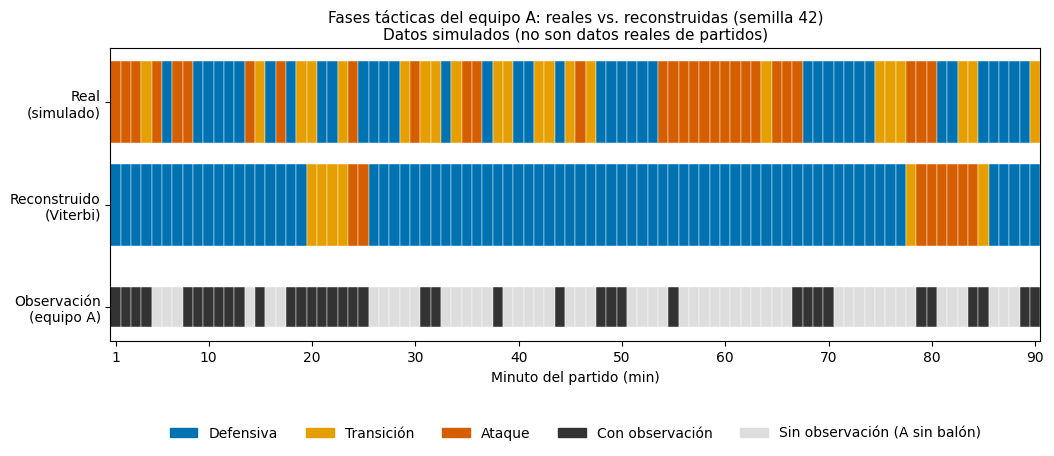

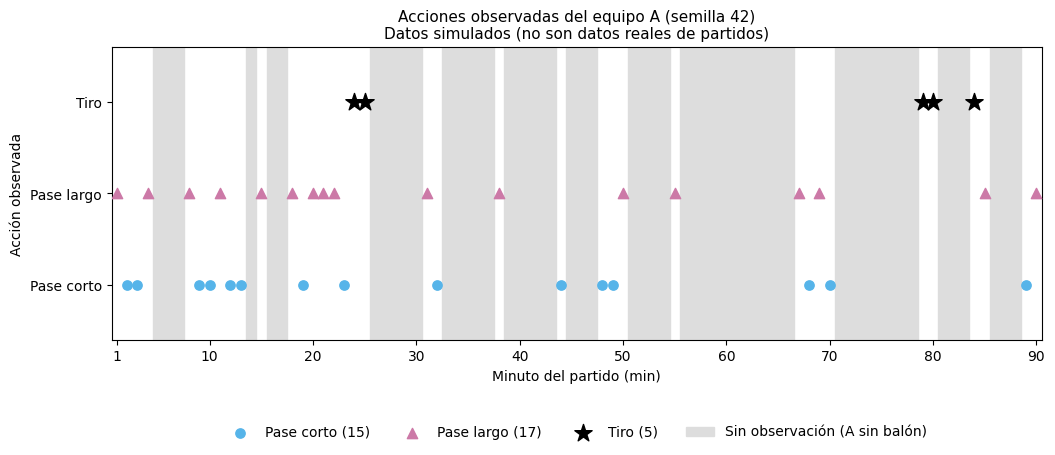

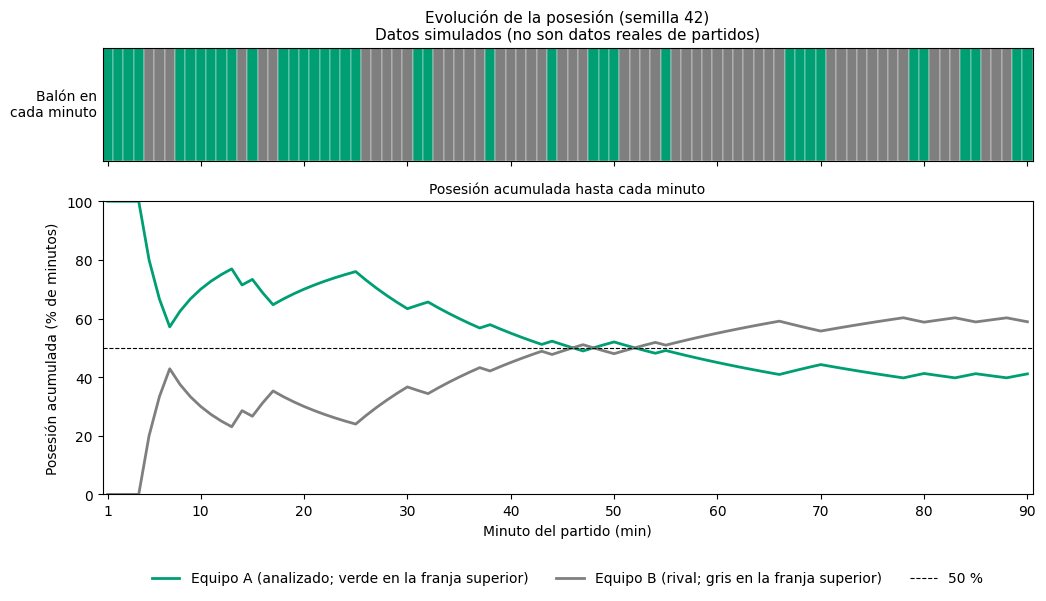

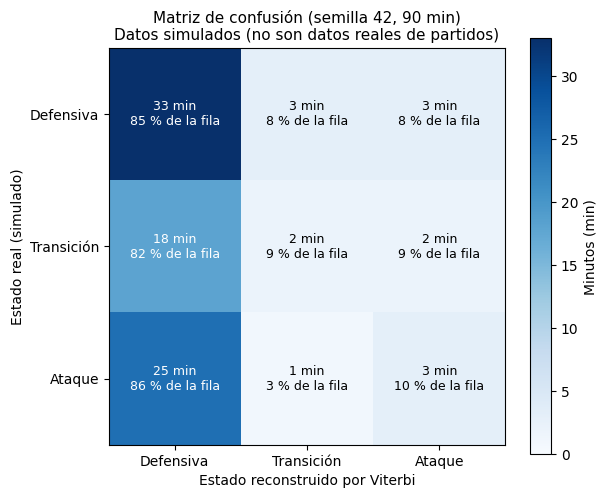

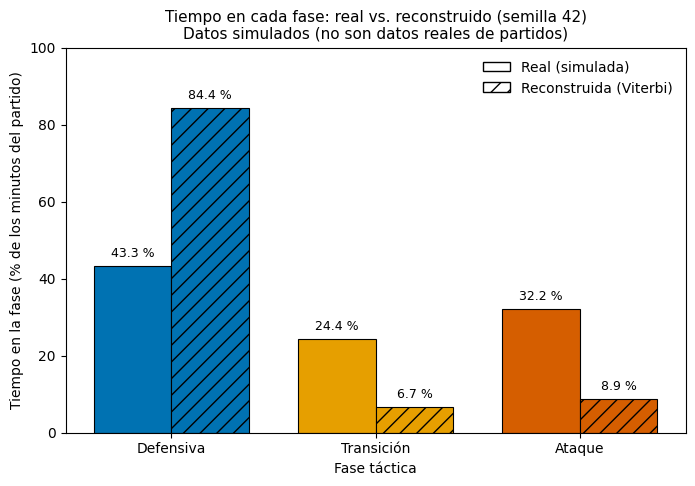

In [3]:
# =============================================================================
# Proyecto: Análisis táctico de fútbol con un Modelo Oculto de Markov (HMM)
# Etapa 5: Métricas y visualizaciones del partido simulado
# Entorno: Google Colab (NumPy, Pandas y Matplotlib)
# =============================================================================

from dataclasses import dataclass
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# -----------------------------------------------------------------------------
# 1. Parámetros del HMM (escenario base, sin modificar)
# -----------------------------------------------------------------------------
ESTADOS = ("Defensiva", "Transición", "Ataque")        # S0, S1, S2
OBSERVACIONES = ("Pase corto", "Pase largo", "Tiro")   # O0, O1, O2

A_BASE = np.array([
    [0.60, 0.30, 0.10],   # desde Defensiva
    [0.30, 0.40, 0.30],   # desde Transición
    [0.20, 0.30, 0.50],   # desde Ataque
])

B_BASE = np.array([
    [0.70, 0.25, 0.05],   # emisiones en Defensiva
    [0.40, 0.50, 0.10],   # emisiones en Transición
    [0.30, 0.30, 0.40],   # emisiones en Ataque
])

PI_BASE = np.array([0.40, 0.40, 0.20])

TOL = 1e-9  # tolerancia absoluta para comprobar sumas iguales a 1


# -----------------------------------------------------------------------------
# 2. Clase HMM con validación matemática (Etapa 2, sin cambios)
# -----------------------------------------------------------------------------
@dataclass(frozen=True)
class HMM:
    """HMM discreto λ = (A, B, π).

    A  : matriz de transición (N x N), A[i, j] = P(S_{t+1}=j | S_t=i)
    B  : matriz de emisión    (N x M), B[i, k] = P(O_t=k | S_t=i)
    pi : distribución inicial (N,),    pi[i]  = P(S_1=i)

    Los arreglos internos son copias de solo lectura: no pueden modificarse
    accidentalmente después de crear el modelo.
    """
    A: np.ndarray
    B: np.ndarray
    pi: np.ndarray
    estados: tuple = ESTADOS
    observaciones: tuple = OBSERVACIONES

    def __post_init__(self):
        # Copias de tipo float, independientes de los arreglos originales.
        object.__setattr__(self, "A", np.array(self.A, dtype=float))
        object.__setattr__(self, "B", np.array(self.B, dtype=float))
        object.__setattr__(self, "pi", np.array(self.pi, dtype=float))
        self.validar()
        # Se bloquea la escritura solo cuando el modelo ya es válido.
        self.A.setflags(write=False)
        self.B.setflags(write=False)
        self.pi.setflags(write=False)

    @property
    def N(self) -> int:
        """Número de estados ocultos."""
        return self.A.shape[0]

    @property
    def M(self) -> int:
        """Número de observaciones distintas."""
        return self.B.shape[1]

    def validar(self) -> None:
        """Lanza ValueError si el modelo no cumple las propiedades requeridas."""
        N = len(self.estados)
        M = len(self.observaciones)

        # 1) Dimensiones
        if self.A.shape != (N, N):
            raise ValueError(f"A debe ser {N}x{N}; se recibió {self.A.shape}.")
        if self.B.shape != (N, M):
            raise ValueError(f"B debe ser {N}x{M}; se recibió {self.B.shape}.")
        if self.pi.shape != (N,):
            raise ValueError(f"pi debe tener longitud {N}; se recibió {self.pi.shape}.")

        # 2) Valores finitos y 3) no negativos
        for nombre, arr in (("A", self.A), ("B", self.B), ("pi", self.pi)):
            if not np.all(np.isfinite(arr)):
                raise ValueError(f"{nombre} contiene valores no finitos (NaN/inf).")
            if np.any(arr < 0):
                raise ValueError(f"{nombre} contiene probabilidades negativas.")

        # 4) Sumas iguales a 1 (rtol=0.0: solo se aplica la tolerancia absoluta)
        for nombre, arr in (("A", self.A), ("B", self.B)):
            sumas = arr.sum(axis=1)
            if not np.allclose(sumas, 1.0, rtol=0.0, atol=TOL):
                raise ValueError(f"Las filas de {nombre} deben sumar 1; suman {sumas}.")
        if not np.isclose(self.pi.sum(), 1.0, rtol=0.0, atol=TOL):
            raise ValueError(f"pi debe sumar 1; suma {self.pi.sum():.12f}.")

    def distribucion_estacionaria(self) -> np.ndarray:
        """Distribución π* que cumple π* A = π* (comportamiento a largo plazo).

        No representa los porcentajes exactos de un partido de 90 minutos.
        """
        valores, vectores = np.linalg.eig(self.A.T)
        k = np.argmin(np.abs(valores - 1.0))
        v = np.real(vectores[:, k])
        return v / v.sum()


def crear_modelo_base() -> HMM:
    """Devuelve el HMM del escenario base (parámetros originales)."""
    return HMM(A=A_BASE, B=B_BASE, pi=PI_BASE)


# -----------------------------------------------------------------------------
# 3. Parámetros de posesión (separados de A, B y π)
#    SUPUESTOS DEL MODELO, no estimados a partir de partidos reales.
# -----------------------------------------------------------------------------
EQUIPOS = ("Equipo A", "Equipo B")   # A = equipo analizado, B = rival
EQUIPO_A, EQUIPO_B = 0, 1
OBS_AUSENTE = -1                     # código de observación ausente
MINUTOS = 90
SEMILLA_BASE = 42


@dataclass(frozen=True)
class ParamsPosesion:
    """Cadena de Markov de dos estados para la posesión (independiente de la fase)."""
    p_inicial_A: float = 0.50    # P(el equipo A tiene el balón en el minuto 1)
    p_mantener_A: float = 0.70   # P(A conserva el balón | A lo tiene)
    p_mantener_B: float = 0.70   # P(B conserva el balón | B lo tiene)

    def __post_init__(self):
        for nombre in ("p_inicial_A", "p_mantener_A", "p_mantener_B"):
            valor = getattr(self, nombre)
            if not np.isfinite(valor) or not (0.0 <= valor <= 1.0):
                raise ValueError(f"{nombre} debe estar en [0, 1]; se recibió {valor}.")

    @property
    def pi_posesion(self) -> np.ndarray:
        """Distribución inicial de la posesión: [P(A), P(B)]."""
        return np.array([self.p_inicial_A, 1.0 - self.p_inicial_A])

    @property
    def matriz(self) -> np.ndarray:
        """Matriz de transición de la posesión (filas: quién tiene el balón ahora)."""
        return np.array([
            [self.p_mantener_A, 1.0 - self.p_mantener_A],   # desde A
            [1.0 - self.p_mantener_B, self.p_mantener_B],   # desde B
        ])


PARAMS_POSESION = ParamsPosesion()


# -----------------------------------------------------------------------------
# 4. Simulación del partido
# -----------------------------------------------------------------------------
@dataclass(frozen=True)
class Partido:
    """Resultado de simular un partido (arreglos de solo lectura)."""
    semilla: int
    estados: np.ndarray        # estado táctico real del equipo A (0, 1, 2)
    posesion: np.ndarray       # 0 = Equipo A, 1 = Equipo B
    observaciones: np.ndarray  # 0, 1, 2 con posesión de A; -1 si A no tiene el balón

    def __post_init__(self):
        # Copias independientes: el partido no comparte memoria con los arreglos
        # recibidos (que quedan intactos y modificables) y sus propios arreglos
        # son de solo lectura.
        for nombre in ("estados", "posesion", "observaciones"):
            copia = np.array(getattr(self, nombre), dtype=int)
            copia.setflags(write=False)
            object.__setattr__(self, nombre, copia)


def _validar_T(T) -> None:
    """T (número de minutos) debe ser un entero positivo."""
    if isinstance(T, bool) or not isinstance(T, (int, np.integer)) or T <= 0:
        raise ValueError(f"T debe ser un entero positivo; se recibió {T!r}.")


def _muestrear(rng: np.random.Generator, probs: np.ndarray) -> int:
    """Sortea un índice según el vector de probabilidades `probs`."""
    return int(rng.choice(len(probs), p=probs))


def simular_estados(modelo: HMM, T: int, rng: np.random.Generator) -> np.ndarray:
    """S_1 ~ π y S_{t+1} ~ A[S_t, :]."""
    _validar_T(T)
    estados = np.empty(T, dtype=int)
    estados[0] = _muestrear(rng, modelo.pi)
    for t in range(1, T):
        estados[t] = _muestrear(rng, modelo.A[estados[t - 1]])
    return estados


def simular_posesion(params: ParamsPosesion, T: int, rng: np.random.Generator) -> np.ndarray:
    """Cadena de Markov de dos estados, independiente de la fase táctica."""
    _validar_T(T)
    posesion = np.empty(T, dtype=int)
    posesion[0] = _muestrear(rng, params.pi_posesion)
    for t in range(1, T):
        posesion[t] = _muestrear(rng, params.matriz[posesion[t - 1]])
    return posesion


def simular_observaciones(modelo: HMM, estados: np.ndarray, posesion: np.ndarray,
                          rng: np.random.Generator) -> np.ndarray:
    """O_t ~ B[S_t, :] solo si el equipo A tiene el balón; si no, observación ausente (-1)."""
    _validar_T(len(estados))
    obs = np.full(len(estados), OBS_AUSENTE, dtype=int)
    for t in range(len(estados)):
        if posesion[t] == EQUIPO_A:
            obs[t] = _muestrear(rng, modelo.B[estados[t]])
    return obs


def validar_partido(modelo: HMM, p: Partido, T: int = MINUTOS) -> None:
    """Comprueba la consistencia de la simulación; lanza ValueError si falla."""
    if not (len(p.estados) == len(p.posesion) == len(p.observaciones) == T):
        raise ValueError(f"Las tres secuencias deben tener longitud {T}.")
    if not np.all(np.isin(p.estados, range(modelo.N))):
        raise ValueError("Hay estados fuera de rango.")
    if not np.all(np.isin(p.posesion, (EQUIPO_A, EQUIPO_B))):
        raise ValueError("Hay valores de posesión inválidos.")
    if not np.all(p.observaciones[p.posesion == EQUIPO_B] == OBS_AUSENTE):
        raise ValueError("Hay observaciones asignadas cuando A no tiene el balón.")
    if not np.all(np.isin(p.observaciones[p.posesion == EQUIPO_A], range(modelo.M))):
        raise ValueError("Hay observaciones ausentes o inválidas cuando A tiene el balón.")


def simular_partido(modelo: HMM, params_posesion: ParamsPosesion = PARAMS_POSESION,
                    semilla: int = SEMILLA_BASE, T: int = MINUTOS) -> Partido:
    """Simula un partido de T minutos (una acción por minuto).

    Una semilla maestra genera dos generadores independientes:
      - rng_hmm: estados ocultos y observaciones
      - rng_pos: posesión
    Orden: estados -> posesión -> observaciones (solo con posesión de A).
    """
    _validar_T(T)
    ss_hmm, ss_pos = np.random.SeedSequence(semilla).spawn(2)
    rng_hmm = np.random.default_rng(ss_hmm)
    rng_pos = np.random.default_rng(ss_pos)

    estados = simular_estados(modelo, T, rng_hmm)
    posesion = simular_posesion(params_posesion, T, rng_pos)
    observaciones = simular_observaciones(modelo, estados, posesion, rng_hmm)

    partido = Partido(semilla=semilla, estados=estados, posesion=posesion,
                      observaciones=observaciones)
    validar_partido(modelo, partido, T)
    return partido


# -----------------------------------------------------------------------------
# 5. Resumen y tabla de los primeros minutos
# -----------------------------------------------------------------------------
def resumen_partido(modelo: HMM, p: Partido) -> None:
    """Imprime un resumen descriptivo de la simulación (no son métricas finales)."""
    T = len(p.estados)
    print(f"Partido simulado: {T} minutos, semilla = {p.semilla}")
    print("(Datos simulados; no son datos reales de partidos.)\n")

    print("Minutos en cada fase táctica real del equipo A:")
    for i, nombre in enumerate(modelo.estados):
        n = int(np.sum(p.estados == i))
        print(f"  {nombre:<11}: {n:>2} min ({100 * n / T:5.1f} %)")

    print("\nPosesión:")
    for i, nombre in enumerate(EQUIPOS):
        n = int(np.sum(p.posesion == i))
        print(f"  {nombre}: {n:>2} min ({100 * n / T:5.1f} %)")

    con_obs = p.observaciones != OBS_AUSENTE
    print(f"\nObservaciones del equipo A: {int(con_obs.sum())} presentes, "
          f"{int((~con_obs).sum())} ausentes (-1)")
    for k, nombre in enumerate(modelo.observaciones):
        print(f"  {nombre:<10}: {int(np.sum(p.observaciones == k))}")


def tabla_primeros_minutos(modelo: HMM, p: Partido, n: int = 15) -> pd.DataFrame:
    """Tabla con los primeros n minutos de la simulación."""
    filas = []
    for t in range(n):
        o = p.observaciones[t]
        filas.append({
            "Minuto": t + 1,
            "Estado táctico real (A)": modelo.estados[p.estados[t]],
            "Posesión": EQUIPOS[p.posesion[t]],
            "Acción observada": "— (sin observación)" if o == OBS_AUSENTE
                                else modelo.observaciones[o],
        })
    return pd.DataFrame(filas).set_index("Minuto")


# -----------------------------------------------------------------------------
# 6. Algoritmo de Viterbi (en logaritmos, con observaciones ausentes)
# -----------------------------------------------------------------------------
def _log_seguro(x: np.ndarray) -> np.ndarray:
    """log(x) que devuelve -inf para x = 0, sin mostrar advertencias."""
    with np.errstate(divide="ignore"):
        return np.log(x)


def _log_emision(log_B: np.ndarray, o: int) -> np.ndarray:
    """Vector log e_j(o) para j = 0..N-1.

    Observación presente: log B[j, o].
    Observación ausente (-1): e_j = 1 para todo j, es decir log e_j = 0.
    """
    if o == OBS_AUSENTE:
        return np.zeros(log_B.shape[0])
    return log_B[:, o]


def _validar_observaciones(modelo: HMM, obs: np.ndarray) -> None:
    if obs.ndim != 1 or len(obs) == 0:
        raise ValueError("Las observaciones deben ser un arreglo 1D no vacío.")
    validas = (obs == OBS_AUSENTE) | ((obs >= 0) & (obs < modelo.M))
    if not np.all(validas):
        raise ValueError(f"Las observaciones deben ser -1 o enteros en 0..{modelo.M - 1}.")


def viterbi(modelo: HMM, observaciones) -> tuple:
    """Secuencia de estados más probable dada la secuencia de observaciones.

    Recursión (en log-probabilidades):
        delta_1(j) = log pi_j + log e_j(o_1)
        delta_t(j) = max_i [ delta_{t-1}(i) + log a_ij ] + log e_j(o_t)
        psi_t(j)   = argmax_i [ delta_{t-1}(i) + log a_ij ]
    con log e_j(o_t) = log B[j, o_t] si hay observación, y 0 si o_t = -1.

    Solo recibe las observaciones: no usa los estados reales ni la posesión.
    En caso de empate gana el estado de menor índice (comportamiento de argmax).

    Devuelve (camino, log_prob): el camino óptimo (array de enteros) y el
    logaritmo de la probabilidad conjunta de ese camino con las observaciones
    presentes.
    """
    obs = np.asarray(observaciones, dtype=int)
    _validar_observaciones(modelo, obs)
    T, N = len(obs), modelo.N

    log_pi = _log_seguro(modelo.pi)
    log_A = _log_seguro(modelo.A)
    log_B = _log_seguro(modelo.B)

    delta = np.empty((T, N))
    psi = np.zeros((T, N), dtype=int)

    delta[0] = log_pi + _log_emision(log_B, obs[0])
    for t in range(1, T):
        candidatos = delta[t - 1][:, None] + log_A      # candidatos[i, j]
        psi[t] = np.argmax(candidatos, axis=0)
        delta[t] = candidatos[psi[t], np.arange(N)] + _log_emision(log_B, obs[t])

    log_prob = float(delta[-1].max())
    if not np.isfinite(log_prob):
        raise ValueError("La secuencia de observaciones tiene probabilidad cero bajo el modelo.")

    # Retroceso (backtracking)
    camino = np.empty(T, dtype=int)
    camino[-1] = np.argmax(delta[-1])
    for t in range(T - 2, -1, -1):
        camino[t] = psi[t + 1, camino[t + 1]]
    return camino, log_prob


def log_prob_trayectoria(modelo: HMM, estados, observaciones) -> float:
    """log P(estados, observaciones presentes) para una trayectoria dada.

    Misma convención que Viterbi (observación ausente: emisión 1). Sirve para
    verificar que el camino de Viterbi no es peor que la trayectoria real.
    """
    est = np.asarray(estados, dtype=int)
    obs = np.asarray(observaciones, dtype=int)
    log_pi, log_A, log_B = (_log_seguro(modelo.pi), _log_seguro(modelo.A),
                            _log_seguro(modelo.B))
    lp = log_pi[est[0]] + _log_emision(log_B, obs[0])[est[0]]
    for t in range(1, len(est)):
        lp += log_A[est[t - 1], est[t]] + _log_emision(log_B, obs[t])[est[t]]
    return float(lp)


def reconstruir_estados(modelo: HMM, p: Partido) -> tuple:
    """Aplica Viterbi a las observaciones del partido (solo lectura en la salida)."""
    camino, log_prob = viterbi(modelo, p.observaciones)
    camino.setflags(write=False)
    return camino, log_prob


# -----------------------------------------------------------------------------
# 7. Comparación entre estados reales y reconstruidos (solo visual)
# -----------------------------------------------------------------------------
def tabla_comparacion(modelo: HMM, p: Partido, reconstruidos: np.ndarray,
                      n: int = 15) -> pd.DataFrame:
    """Tabla minuto a minuto: estado real vs. estado reconstruido por Viterbi."""
    filas = []
    for t in range(n):
        o = p.observaciones[t]
        filas.append({
            "Minuto": t + 1,
            "Posesión": EQUIPOS[p.posesion[t]],
            "Acción observada": "— (sin observación)" if o == OBS_AUSENTE
                                else modelo.observaciones[o],
            "Estado real": modelo.estados[p.estados[t]],
            "Estado reconstruido": modelo.estados[reconstruidos[t]],
            "Coincide": "✓" if p.estados[t] == reconstruidos[t] else "✗",
        })
    return pd.DataFrame(filas).set_index("Minuto")


# -----------------------------------------------------------------------------
# 8. Métricas
#    Se calculan sobre dos secuencias de estados, con propósitos distintos:
#      - REAL (simulada): describe lo que ocurrió de verdad en el partido simulado.
#      - RECONSTRUIDA (Viterbi): lo que un analista inferiría solo con las
#        observaciones. La diferencia entre ambas mide el error de la reconstrucción.
# -----------------------------------------------------------------------------
S_DEF, S_TRA, S_ATA = 0, 1, 2   # índices de las fases
OBS_TIRO = 2                    # índice de la observación "Tiro"


def _dividir(num: float, den: float) -> float:
    """num / den; devuelve NaN si el denominador es 0 (métrica no definida)."""
    return float(num) / float(den) if den > 0 else float("nan")


def contar_intentos_transicion(estados) -> tuple:
    """Intentos de transición: cada tramo continuo en S1 es UN intento.

    - Exitoso   : el tramo termina en S2 (alcanza el ataque antes de volver a S0).
    - Fallido   : el tramo termina en S0.
    - Incompleto: el partido termina mientras sigue en S1.
    - Si el partido empieza en S1, ese tramo inicial no cuenta como intento.
    - S2 -> S1 -> S2 cuenta como intento exitoso (definición aprobada).
    Devuelve (exitosos, fallidos, incompletos).
    """
    est = np.asarray(estados, dtype=int)
    T = len(est)
    exitosos = fallidos = incompletos = 0
    t = 0
    while t < T:
        if est[t] != S_TRA:
            t += 1
            continue
        inicio = t
        while t < T and est[t] == S_TRA:
            t += 1
        fin = t                      # primer minuto posterior al tramo en S1
        if inicio == 0:
            continue                 # el partido empieza en S1: no es un intento
        if fin == T:
            incompletos += 1
        elif est[fin] == S_ATA:
            exitosos += 1
        else:
            fallidos += 1
    return exitosos, fallidos, incompletos


def contar_defensa_ataque(estados) -> tuple:
    """Transiciones defensa -> ataque.

    Se cuenta cada llegada a S2 cuya última fase distinta de S1 fue S0
    (S0 -> S2 directa, o S0 -> S1 ... -> S2). S2 -> S1 -> S2 no cuenta.
    Devuelve (total, directas), donde directas son los saltos S0 -> S2 en un minuto.
    """
    est = np.asarray(estados, dtype=int)
    ultima = None            # última fase distinta de S1 (S0 o S2)
    total = directas = 0
    for t, s in enumerate(est):
        if s == S_ATA and t > 0 and est[t - 1] != S_ATA and ultima == S_DEF:
            total += 1
            if est[t - 1] == S_DEF:
                directas += 1
        if s != S_TRA:
            ultima = s
    return total, directas


def calcular_metricas(estados, p: Partido) -> dict:
    """Métricas del partido para una secuencia de estados (real o reconstruida).

    Porcentajes y eficiencia en escala 0-100. Si un denominador es 0, la
    métrica vale NaN (no definida).
    """
    est = np.asarray(estados, dtype=int)
    T = len(est)
    obs, pos = p.observaciones, p.posesion
    m = {}

    # Distribución temporal de fases
    for i in range(3):
        n = int(np.sum(est == i))
        m[f"min_{i}"] = n
        m[f"pct_{i}"] = 100.0 * _dividir(n, T)

    # Transiciones tácticas
    m["cambios_fase"] = int(np.sum(est[1:] != est[:-1]))
    m["def_ataque_total"], m["def_ataque_directas"] = contar_defensa_ataque(est)
    ex, fa, inc = contar_intentos_transicion(est)
    m["intentos_exitosos"], m["intentos_fallidos"], m["intentos_incompletos"] = ex, fa, inc
    m["intentos_total"] = ex + fa + inc
    m["eficiencia_transicion"] = 100.0 * _dividir(ex, ex + fa)   # incompletos excluidos

    # Tiros (solo los observados, es decir, con posesión del equipo A)
    es_tiro = obs == OBS_TIRO
    en_ataque = est == S_ATA
    m["tiros_total_obs"] = int(es_tiro.sum())
    m["tiros_en_ataque"] = int((es_tiro & en_ataque).sum())
    m["min_ataque_posesion"] = int((en_ataque & (pos == EQUIPO_A)).sum())
    m["tiros_x_min_ataque"] = _dividir(m["tiros_en_ataque"], m["min_2"])
    m["tiros_x_min_ataque_posesion"] = _dividir(m["tiros_en_ataque"], m["min_ataque_posesion"])
    return m


def calcular_exactitud(p: Partido, reconstruidos) -> dict:
    """Exactitud de Viterbi (% de minutos con el estado correcto): global,
    en minutos con observación y en minutos sin observación."""
    rec = np.asarray(reconstruidos, dtype=int)
    ok = p.estados == rec
    observado = p.observaciones != OBS_AUSENTE
    r = {
        "minutos_global": int(len(ok)), "aciertos_global": int(ok.sum()),
        "minutos_observados": int(observado.sum()), "aciertos_observados": int((ok & observado).sum()),
        "minutos_sin_obs": int((~observado).sum()), "aciertos_sin_obs": int((ok & ~observado).sum()),
    }
    r["exactitud_global"] = 100.0 * _dividir(r["aciertos_global"], r["minutos_global"])
    r["exactitud_observados"] = 100.0 * _dividir(r["aciertos_observados"], r["minutos_observados"])
    r["exactitud_sin_obs"] = 100.0 * _dividir(r["aciertos_sin_obs"], r["minutos_sin_obs"])
    return r


def matriz_confusion(reales, reconstruidos, N: int = 3) -> np.ndarray:
    """cm[i, j] = minutos con estado real i y estado reconstruido j."""
    cm = np.zeros((N, N), dtype=int)
    np.add.at(cm, (np.asarray(reales, dtype=int), np.asarray(reconstruidos, dtype=int)), 1)
    return cm


def verificar_coherencia_metricas(p: Partido, reconstruidos, m_real: dict, m_rec: dict,
                                  exact: dict, cm: np.ndarray) -> None:
    """Comprobaciones internas de consistencia; lanza ValueError si algo no cuadra."""
    T = len(p.estados)
    for nombre, m in (("real", m_real), ("reconstruida", m_rec)):
        if sum(m[f"min_{i}"] for i in range(3)) != T:
            raise ValueError(f"Los minutos por fase ({nombre}) no suman {T}.")
        if m["tiros_en_ataque"] > m["tiros_total_obs"]:
            raise ValueError(f"Hay más tiros en ataque que tiros totales ({nombre}).")
    if m_real["tiros_total_obs"] != m_rec["tiros_total_obs"]:
        raise ValueError("El total de tiros observados debe ser igual en ambas secuencias.")
    if cm.sum() != T or int(np.trace(cm)) != exact["aciertos_global"]:
        raise ValueError("La matriz de confusión no es coherente con la exactitud.")
    if exact["minutos_observados"] + exact["minutos_sin_obs"] != T:
        raise ValueError("Minutos observados + sin observación deben sumar el total.")
    if exact["aciertos_observados"] + exact["aciertos_sin_obs"] != exact["aciertos_global"]:
        raise ValueError("Los aciertos parciales deben sumar los aciertos globales.")


# --- Presentación de métricas -------------------------------------------------
def _num(v, decimales: int = 3, sufijo: str = "") -> str:
    """Formatea un número; muestra 'n/d' si la métrica no está definida (NaN)."""
    return "n/d" if np.isnan(v) else f"{v:.{decimales}f}{sufijo}"


def tabla_metricas(modelo: HMM, m_real: dict, m_rec: dict) -> pd.DataFrame:
    """Tabla comparativa: secuencia real vs. reconstruida por Viterbi."""
    filas = []
    for i, nombre in enumerate(modelo.estados):
        filas.append((f"Tiempo en {nombre} (min y %)",
                      lambda m, i=i: f"{m[f'min_{i}']} ({_num(m[f'pct_{i}'], 1)} %)"))
    filas += [
        ("Cambios de fase (n.º)", lambda m: f"{m['cambios_fase']}"),
        ("Transiciones defensa→ataque (n.º; directas S0→S2)",
         lambda m: f"{m['def_ataque_total']} ({m['def_ataque_directas']})"),
        ("Intentos de transición (n.º)", lambda m: f"{m['intentos_total']}"),
        ("   exitosos", lambda m: f"{m['intentos_exitosos']}"),
        ("   fallidos", lambda m: f"{m['intentos_fallidos']}"),
        ("   incompletos (fuera de la eficiencia)", lambda m: f"{m['intentos_incompletos']}"),
        ("Eficiencia de transición (%)", lambda m: _num(m["eficiencia_transicion"], 1)),
        ("Tiros observados en el partido (n.º)", lambda m: f"{m['tiros_total_obs']}"),
        ("Tiros observados durante Ataque (n.º)", lambda m: f"{m['tiros_en_ataque']}"),
        ("Minutos en Ataque / con posesión de A (min)",
         lambda m: f"{m['min_2']} / {m['min_ataque_posesion']}"),
        ("Tiros por minuto en Ataque (tiros/min)", lambda m: _num(m["tiros_x_min_ataque"])),
        ("Tiros por minuto en Ataque con posesión de A (tiros/min)",
         lambda m: _num(m["tiros_x_min_ataque_posesion"])),
    ]
    datos = {etiqueta: [f(m_real), f(m_rec)] for etiqueta, f in filas}
    return pd.DataFrame(datos, index=["Real (simulada)", "Reconstruida (Viterbi)"]).T


def imprimir_exactitud(e: dict) -> None:
    """Imprime la exactitud de la reconstrucción (global, observados y sin observación)."""
    print("Exactitud de la reconstrucción de Viterbi (% de minutos con estado correcto):")
    for etiqueta, a, n, x in (
        ("Global", "aciertos_global", "minutos_global", "exactitud_global"),
        ("Minutos con observación", "aciertos_observados", "minutos_observados", "exactitud_observados"),
        ("Minutos sin observación", "aciertos_sin_obs", "minutos_sin_obs", "exactitud_sin_obs"),
    ):
        print(f"  {etiqueta:<25}: {_num(e[x], 1):>5} %  ({e[a]}/{e[n]} min)")


def tabla_confusion(modelo: HMM, cm: np.ndarray) -> pd.DataFrame:
    """Matriz de confusión como tabla (filas: real; columnas: reconstruido)."""
    return pd.DataFrame(cm,
                        index=[f"Real: {e}" for e in modelo.estados],
                        columns=[f"Reconstruido: {e}" for e in modelo.estados])


# -----------------------------------------------------------------------------
# 9. Visualizaciones (se guardan como PNG en la carpeta CARPETA_SALIDA)
# -----------------------------------------------------------------------------
CARPETA_SALIDA = "resultados_etapa5"
DPI_FIGURAS = 300                                  # resolución de las imágenes guardadas
COLORES_FASE = ("#0072B2", "#E69F00", "#D55E00")   # Defensiva, Transición, Ataque
COLORES_EQUIPO = ("#009E73", "#7F7F7F")            # Equipo A, Equipo B
NOTA_SIMULADO = "Datos simulados (no son datos reales de partidos)"


def _guardar(fig, nombre: str) -> str:
    os.makedirs(CARPETA_SALIDA, exist_ok=True)
    ruta = os.path.join(CARPETA_SALIDA, nombre)
    fig.savefig(ruta, dpi=DPI_FIGURAS, bbox_inches="tight")
    return ruta


def _xticks(T: int) -> list:
    return [1] + list(range(10, T + 1, 10))


def graficar_linea_tiempo(modelo: HMM, p: Partido, reconstruidos) -> plt.Figure:
    """Línea de tiempo: fases reales, fases reconstruidas y minutos con observación."""
    T = len(p.estados)
    fig, ax = plt.subplots(figsize=(12, 3.8))
    for t in range(T):
        ax.barh(2, 1, left=t + 0.5, height=0.8, color=COLORES_FASE[p.estados[t]],
                edgecolor="white", linewidth=0.3)
        ax.barh(1, 1, left=t + 0.5, height=0.8, color=COLORES_FASE[reconstruidos[t]],
                edgecolor="white", linewidth=0.3)
        con_obs = p.observaciones[t] != OBS_AUSENTE
        ax.barh(0, 1, left=t + 0.5, height=0.4,
                color="#333333" if con_obs else "#DDDDDD", edgecolor="white", linewidth=0.3)
    ax.set_yticks([0, 1, 2])
    ax.set_yticklabels(["Observación\n(equipo A)", "Reconstruido\n(Viterbi)", "Real\n(simulado)"])
    ax.set_xlim(0.5, T + 0.5)
    ax.set_xticks(_xticks(T))
    ax.set_xlabel("Minuto del partido (min)")
    ax.set_title(f"Fases tácticas del equipo A: reales vs. reconstruidas (semilla {p.semilla})\n"
                 f"{NOTA_SIMULADO}", fontsize=11)
    handles = [Patch(color=COLORES_FASE[i], label=modelo.estados[i]) for i in range(3)]
    handles += [Patch(color="#333333", label="Con observación"),
                Patch(color="#DDDDDD", label="Sin observación (A sin balón)")]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=5, frameon=False)
    _guardar(fig, "01_linea_tiempo_fases.png")
    return fig


def graficar_acciones(modelo: HMM, p: Partido) -> plt.Figure:
    """Acciones observadas del equipo A minuto a minuto."""
    T = len(p.observaciones)
    minutos = np.arange(1, T + 1)
    fig, ax = plt.subplots(figsize=(12, 3.8))
    for t in np.where(p.observaciones == OBS_AUSENTE)[0]:
        ax.axvspan(t + 0.5, t + 1.5, color="#DDDDDD", zorder=0)
    estilos = (("o", "#56B4E9", 45), ("^", "#CC79A7", 55), ("*", "#000000", 170))
    for k, (marcador, color, tam) in enumerate(estilos):
        idx = p.observaciones == k
        ax.scatter(minutos[idx], np.full(int(idx.sum()), k), marker=marcador, color=color,
                   s=tam, label=f"{modelo.observaciones[k]} ({int(idx.sum())})", zorder=3)
    ax.set_yticks(range(modelo.M))
    ax.set_yticklabels(modelo.observaciones)
    ax.set_ylim(-0.6, modelo.M - 0.4)
    ax.set_xlim(0.5, T + 0.5)
    ax.set_xticks(_xticks(T))
    ax.set_xlabel("Minuto del partido (min)")
    ax.set_ylabel("Acción observada")
    ax.set_title(f"Acciones observadas del equipo A (semilla {p.semilla})\n{NOTA_SIMULADO}", fontsize=11)
    handles, _ = ax.get_legend_handles_labels()
    handles.append(Patch(color="#DDDDDD", label="Sin observación (A sin balón)"))
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=4, frameon=False)
    _guardar(fig, "02_acciones_observadas.png")
    return fig


def graficar_posesion(p: Partido) -> plt.Figure:
    """Posesión por minuto y posesión acumulada de ambos equipos."""
    T = len(p.posesion)
    minutos = np.arange(1, T + 1)
    pos_A = np.cumsum(p.posesion == EQUIPO_A) / minutos * 100.0
    pos_B = 100.0 - pos_A
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5.8), sharex=True,
                                   gridspec_kw={"height_ratios": [1, 2.6]})
    for t in range(T):
        ax1.barh(0, 1, left=t + 0.5, height=1.0, color=COLORES_EQUIPO[p.posesion[t]],
                 edgecolor="white", linewidth=0.3)
    ax1.set_yticks([])
    ax1.set_ylim(-0.5, 0.5)
    ax1.set_ylabel("Balón en\ncada minuto", rotation=0, ha="right", va="center")
    ax1.set_title(f"Evolución de la posesión (semilla {p.semilla})\n{NOTA_SIMULADO}", fontsize=11)
    ax2.set_title("Posesión acumulada hasta cada minuto", fontsize=10)
    ax2.plot(minutos, pos_A, color=COLORES_EQUIPO[0], lw=2, label="Equipo A (analizado; verde en la franja superior)")
    ax2.plot(minutos, pos_B, color=COLORES_EQUIPO[1], lw=2, label="Equipo B (rival; gris en la franja superior)")
    ax2.axhline(50, color="black", ls="--", lw=0.8, label="50 %")
    ax2.set_ylim(0, 100)
    ax2.set_xlim(0.5, T + 0.5)
    ax2.set_xticks(_xticks(T))
    ax2.set_xlabel("Minuto del partido (min)")
    ax2.set_ylabel("Posesión acumulada (% de minutos)")
    ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False)
    _guardar(fig, "03_evolucion_posesion.png")
    return fig


def graficar_matriz_confusion(modelo: HMM, cm: np.ndarray, semilla: int) -> plt.Figure:
    """Matriz de confusión (minutos) entre estados reales y reconstruidos."""
    N = cm.shape[0]
    fig, ax = plt.subplots(figsize=(6.4, 5.4))
    im = ax.imshow(cm, cmap="Blues", vmin=0)
    fig.colorbar(im, ax=ax).set_label("Minutos (min)")
    ax.set_xticks(range(N))
    ax.set_xticklabels(modelo.estados)
    ax.set_yticks(range(N))
    ax.set_yticklabels(modelo.estados)
    ax.set_xlabel("Estado reconstruido por Viterbi")
    ax.set_ylabel("Estado real (simulado)")
    umbral = cm.max() / 2 if cm.max() > 0 else 0
    for i in range(N):
        suma_fila = cm[i].sum()
        for j in range(N):
            pct = f"{100 * cm[i, j] / suma_fila:.0f} % de la fila" if suma_fila > 0 else "fila sin minutos"
            ax.text(j, i, f"{cm[i, j]} min\n{pct}", ha="center", va="center", fontsize=9,
                    color="white" if cm[i, j] > umbral else "black")
    ax.set_title(f"Matriz de confusión (semilla {semilla}, {int(cm.sum())} min)\n{NOTA_SIMULADO}",
                 fontsize=11)
    _guardar(fig, "04_matriz_confusion.png")
    return fig


def graficar_comparacion_fases(modelo: HMM, m_real: dict, m_rec: dict, semilla: int) -> plt.Figure:
    """Barras agrupadas: % de tiempo en cada fase, real vs. reconstruido (Viterbi)."""
    N = modelo.N
    x = np.arange(N)
    ancho = 0.38
    reales = [m_real[f"pct_{i}"] for i in range(N)]
    recons = [m_rec[f"pct_{i}"] for i in range(N)]
    fig, ax = plt.subplots(figsize=(8, 5))
    for i in range(N):
        ax.bar(x[i] - ancho / 2, reales[i], ancho, color=COLORES_FASE[i],
               edgecolor="black", linewidth=0.8)
        ax.bar(x[i] + ancho / 2, recons[i], ancho, color=COLORES_FASE[i],
               edgecolor="black", linewidth=0.8, hatch="//")
        for pos, valor in ((x[i] - ancho / 2, reales[i]), (x[i] + ancho / 2, recons[i])):
            if not np.isnan(valor):
                ax.text(pos, valor + 1.5, f"{valor:.1f} %", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(modelo.estados)
    ax.set_ylim(0, 100)
    ax.set_xlabel("Fase táctica")
    ax.set_ylabel("Tiempo en la fase (% de los minutos del partido)")
    ax.set_title(f"Tiempo en cada fase: real vs. reconstruido (semilla {semilla})\n{NOTA_SIMULADO}",
                 fontsize=11)
    ax.legend(handles=[Patch(facecolor="white", edgecolor="black", label="Real (simulada)"),
                       Patch(facecolor="white", edgecolor="black", hatch="//",
                             label="Reconstruida (Viterbi)")],
              loc="upper right", frameon=False)
    _guardar(fig, "05_comparacion_tiempo_fases.png")
    return fig


# -----------------------------------------------------------------------------
# 10. Ejecución de la etapa
# -----------------------------------------------------------------------------
modelo = crear_modelo_base()
print("Modelo válido (A, B y π originales).\n")

partido = simular_partido(modelo, PARAMS_POSESION, semilla=SEMILLA_BASE)
reconstruidos, lp_viterbi = reconstruir_estados(modelo, partido)

m_real = calcular_metricas(partido.estados, partido)
m_rec = calcular_metricas(reconstruidos, partido)
exact = calcular_exactitud(partido, reconstruidos)
cm = matriz_confusion(partido.estados, reconstruidos, modelo.N)
verificar_coherencia_metricas(partido, reconstruidos, m_real, m_rec, exact, cm)

print(f"Partido simulado (semilla = {partido.semilla}); {NOTA_SIMULADO.lower()}.\n")
print("Métricas del partido: secuencia real vs. reconstruida por Viterbi")
print(tabla_metricas(modelo, m_real, m_rec).to_string())
print()
imprimir_exactitud(exact)
print("\nMatriz de confusión (minutos; filas: real, columnas: reconstruido):")
print(tabla_confusion(modelo, cm).to_string())

graficar_linea_tiempo(modelo, partido, reconstruidos)
graficar_acciones(modelo, partido)
graficar_posesion(partido)
graficar_matriz_confusion(modelo, cm, partido.semilla)
graficar_comparacion_fases(modelo, m_real, m_rec, partido.semilla)
print(f"\nLas cinco gráficas se guardaron en la carpeta '{CARPETA_SALIDA}/' ({DPI_FIGURAS} dpi).")
plt.show()

******************************************************************************************************************************************************

In [ ]:
# =============================================================================
# Proyecto: Análisis táctico de fútbol con un Modelo Oculto de Markov (HMM)
# Etapa 6: Experimentos Monte Carlo (escenarios, comparación pareada,
#          sensibilidad a π y reproducibilidad)
# Entorno: Google Colab (NumPy, Pandas, Matplotlib y SciPy)
# =============================================================================

from dataclasses import dataclass
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats

# -----------------------------------------------------------------------------
# 1. Parámetros del HMM (escenario base, sin modificar)
# -----------------------------------------------------------------------------
ESTADOS = ("Defensiva", "Transición", "Ataque")        # S0, S1, S2
OBSERVACIONES = ("Pase corto", "Pase largo", "Tiro")   # O0, O1, O2

A_BASE = np.array([
    [0.60, 0.30, 0.10],   # desde Defensiva
    [0.30, 0.40, 0.30],   # desde Transición
    [0.20, 0.30, 0.50],   # desde Ataque
])

B_BASE = np.array([
    [0.70, 0.25, 0.05],   # emisiones en Defensiva
    [0.40, 0.50, 0.10],   # emisiones en Transición
    [0.30, 0.30, 0.40],   # emisiones en Ataque
])

PI_BASE = np.array([0.40, 0.40, 0.20])

TOL = 1e-9  # tolerancia absoluta para comprobar sumas iguales a 1


# -----------------------------------------------------------------------------
# 2. Clase HMM con validación matemática (Etapa 2, sin cambios)
# -----------------------------------------------------------------------------
@dataclass(frozen=True)
class HMM:
    """HMM discreto λ = (A, B, π).

    A  : matriz de transición (N x N), A[i, j] = P(S_{t+1}=j | S_t=i)
    B  : matriz de emisión    (N x M), B[i, k] = P(O_t=k | S_t=i)
    pi : distribución inicial (N,),    pi[i]  = P(S_1=i)

    Los arreglos internos son copias de solo lectura: no pueden modificarse
    accidentalmente después de crear el modelo.
    """
    A: np.ndarray
    B: np.ndarray
    pi: np.ndarray
    estados: tuple = ESTADOS
    observaciones: tuple = OBSERVACIONES

    def __post_init__(self):
        # Copias de tipo float, independientes de los arreglos originales.
        object.__setattr__(self, "A", np.array(self.A, dtype=float))
        object.__setattr__(self, "B", np.array(self.B, dtype=float))
        object.__setattr__(self, "pi", np.array(self.pi, dtype=float))
        self.validar()
        # Se bloquea la escritura solo cuando el modelo ya es válido.
        self.A.setflags(write=False)
        self.B.setflags(write=False)
        self.pi.setflags(write=False)

    @property
    def N(self) -> int:
        """Número de estados ocultos."""
        return self.A.shape[0]

    @property
    def M(self) -> int:
        """Número de observaciones distintas."""
        return self.B.shape[1]

    def validar(self) -> None:
        """Lanza ValueError si el modelo no cumple las propiedades requeridas."""
        N = len(self.estados)
        M = len(self.observaciones)

        # 1) Dimensiones
        if self.A.shape != (N, N):
            raise ValueError(f"A debe ser {N}x{N}; se recibió {self.A.shape}.")
        if self.B.shape != (N, M):
            raise ValueError(f"B debe ser {N}x{M}; se recibió {self.B.shape}.")
        if self.pi.shape != (N,):
            raise ValueError(f"pi debe tener longitud {N}; se recibió {self.pi.shape}.")

        # 2) Valores finitos y 3) no negativos
        for nombre, arr in (("A", self.A), ("B", self.B), ("pi", self.pi)):
            if not np.all(np.isfinite(arr)):
                raise ValueError(f"{nombre} contiene valores no finitos (NaN/inf).")
            if np.any(arr < 0):
                raise ValueError(f"{nombre} contiene probabilidades negativas.")

        # 4) Sumas iguales a 1 (rtol=0.0: solo se aplica la tolerancia absoluta)
        for nombre, arr in (("A", self.A), ("B", self.B)):
            sumas = arr.sum(axis=1)
            if not np.allclose(sumas, 1.0, rtol=0.0, atol=TOL):
                raise ValueError(f"Las filas de {nombre} deben sumar 1; suman {sumas}.")
        if not np.isclose(self.pi.sum(), 1.0, rtol=0.0, atol=TOL):
            raise ValueError(f"pi debe sumar 1; suma {self.pi.sum():.12f}.")

    def distribucion_estacionaria(self) -> np.ndarray:
        """Distribución π* que cumple π* A = π* (comportamiento a largo plazo).

        No representa los porcentajes exactos de un partido de 90 minutos.
        """
        valores, vectores = np.linalg.eig(self.A.T)
        k = np.argmin(np.abs(valores - 1.0))
        v = np.real(vectores[:, k])
        return v / v.sum()


def crear_modelo_base() -> HMM:
    """Devuelve el HMM del escenario base (parámetros originales)."""
    return HMM(A=A_BASE, B=B_BASE, pi=PI_BASE)


# -----------------------------------------------------------------------------
# 3. Parámetros de posesión (separados de A, B y π)
#    SUPUESTOS DEL MODELO, no estimados a partir de partidos reales.
# -----------------------------------------------------------------------------
EQUIPOS = ("Equipo A", "Equipo B")   # A = equipo analizado, B = rival
EQUIPO_A, EQUIPO_B = 0, 1
OBS_AUSENTE = -1                     # código de observación ausente
MINUTOS = 90
SEMILLA_BASE = 42


@dataclass(frozen=True)
class ParamsPosesion:
    """Cadena de Markov de dos estados para la posesión (independiente de la fase)."""
    p_inicial_A: float = 0.50    # P(el equipo A tiene el balón en el minuto 1)
    p_mantener_A: float = 0.70   # P(A conserva el balón | A lo tiene)
    p_mantener_B: float = 0.70   # P(B conserva el balón | B lo tiene)

    def __post_init__(self):
        for nombre in ("p_inicial_A", "p_mantener_A", "p_mantener_B"):
            valor = getattr(self, nombre)
            if not np.isfinite(valor) or not (0.0 <= valor <= 1.0):
                raise ValueError(f"{nombre} debe estar en [0, 1]; se recibió {valor}.")

    @property
    def pi_posesion(self) -> np.ndarray:
        """Distribución inicial de la posesión: [P(A), P(B)]."""
        return np.array([self.p_inicial_A, 1.0 - self.p_inicial_A])

    @property
    def matriz(self) -> np.ndarray:
        """Matriz de transición de la posesión (filas: quién tiene el balón ahora)."""
        return np.array([
            [self.p_mantener_A, 1.0 - self.p_mantener_A],   # desde A
            [1.0 - self.p_mantener_B, self.p_mantener_B],   # desde B
        ])


PARAMS_POSESION = ParamsPosesion()


# -----------------------------------------------------------------------------
# 4. Simulación del partido
# -----------------------------------------------------------------------------
@dataclass(frozen=True)
class Partido:
    """Resultado de simular un partido (arreglos de solo lectura)."""
    semilla: int
    estados: np.ndarray        # estado táctico real del equipo A (0, 1, 2)
    posesion: np.ndarray       # 0 = Equipo A, 1 = Equipo B
    observaciones: np.ndarray  # 0, 1, 2 con posesión de A; -1 si A no tiene el balón

    def __post_init__(self):
        # Copias independientes: el partido no comparte memoria con los arreglos
        # recibidos (que quedan intactos y modificables) y sus propios arreglos
        # son de solo lectura.
        for nombre in ("estados", "posesion", "observaciones"):
            copia = np.array(getattr(self, nombre), dtype=int)
            copia.setflags(write=False)
            object.__setattr__(self, nombre, copia)


def _validar_T(T) -> None:
    """T (número de minutos) debe ser un entero positivo."""
    if isinstance(T, bool) or not isinstance(T, (int, np.integer)) or T <= 0:
        raise ValueError(f"T debe ser un entero positivo; se recibió {T!r}.")


def _muestrear(rng: np.random.Generator, probs: np.ndarray) -> int:
    """Sortea un índice según el vector de probabilidades `probs`."""
    return int(rng.choice(len(probs), p=probs))


def simular_estados(modelo: HMM, T: int, rng: np.random.Generator) -> np.ndarray:
    """S_1 ~ π y S_{t+1} ~ A[S_t, :]."""
    _validar_T(T)
    estados = np.empty(T, dtype=int)
    estados[0] = _muestrear(rng, modelo.pi)
    for t in range(1, T):
        estados[t] = _muestrear(rng, modelo.A[estados[t - 1]])
    return estados


def simular_posesion(params: ParamsPosesion, T: int, rng: np.random.Generator) -> np.ndarray:
    """Cadena de Markov de dos estados, independiente de la fase táctica."""
    _validar_T(T)
    posesion = np.empty(T, dtype=int)
    posesion[0] = _muestrear(rng, params.pi_posesion)
    for t in range(1, T):
        posesion[t] = _muestrear(rng, params.matriz[posesion[t - 1]])
    return posesion


def simular_observaciones(modelo: HMM, estados: np.ndarray, posesion: np.ndarray,
                          rng: np.random.Generator) -> np.ndarray:
    """O_t ~ B[S_t, :] solo si el equipo A tiene el balón; si no, observación ausente (-1)."""
    _validar_T(len(estados))
    obs = np.full(len(estados), OBS_AUSENTE, dtype=int)
    for t in range(len(estados)):
        if posesion[t] == EQUIPO_A:
            obs[t] = _muestrear(rng, modelo.B[estados[t]])
    return obs


def validar_partido(modelo: HMM, p: Partido, T: int = MINUTOS) -> None:
    """Comprueba la consistencia de la simulación; lanza ValueError si falla."""
    if not (len(p.estados) == len(p.posesion) == len(p.observaciones) == T):
        raise ValueError(f"Las tres secuencias deben tener longitud {T}.")
    if not np.all(np.isin(p.estados, range(modelo.N))):
        raise ValueError("Hay estados fuera de rango.")
    if not np.all(np.isin(p.posesion, (EQUIPO_A, EQUIPO_B))):
        raise ValueError("Hay valores de posesión inválidos.")
    if not np.all(p.observaciones[p.posesion == EQUIPO_B] == OBS_AUSENTE):
        raise ValueError("Hay observaciones asignadas cuando A no tiene el balón.")
    if not np.all(np.isin(p.observaciones[p.posesion == EQUIPO_A], range(modelo.M))):
        raise ValueError("Hay observaciones ausentes o inválidas cuando A tiene el balón.")


def simular_partido(modelo: HMM, params_posesion: ParamsPosesion = PARAMS_POSESION,
                    semilla: int = SEMILLA_BASE, T: int = MINUTOS) -> Partido:
    """Simula un partido de T minutos (una acción por minuto).

    Una semilla maestra genera dos generadores independientes:
      - rng_hmm: estados ocultos y observaciones
      - rng_pos: posesión
    Orden: estados -> posesión -> observaciones (solo con posesión de A).
    """
    _validar_T(T)
    ss_hmm, ss_pos = np.random.SeedSequence(semilla).spawn(2)
    rng_hmm = np.random.default_rng(ss_hmm)
    rng_pos = np.random.default_rng(ss_pos)

    estados = simular_estados(modelo, T, rng_hmm)
    posesion = simular_posesion(params_posesion, T, rng_pos)
    observaciones = simular_observaciones(modelo, estados, posesion, rng_hmm)

    partido = Partido(semilla=semilla, estados=estados, posesion=posesion,
                      observaciones=observaciones)
    validar_partido(modelo, partido, T)
    return partido


# -----------------------------------------------------------------------------
# 5. Resumen y tabla de los primeros minutos
# -----------------------------------------------------------------------------
def resumen_partido(modelo: HMM, p: Partido) -> None:
    """Imprime un resumen descriptivo de la simulación (no son métricas finales)."""
    T = len(p.estados)
    print(f"Partido simulado: {T} minutos, semilla = {p.semilla}")
    print("(Datos simulados; no son datos reales de partidos.)\n")

    print("Minutos en cada fase táctica real del equipo A:")
    for i, nombre in enumerate(modelo.estados):
        n = int(np.sum(p.estados == i))
        print(f"  {nombre:<11}: {n:>2} min ({100 * n / T:5.1f} %)")

    print("\nPosesión:")
    for i, nombre in enumerate(EQUIPOS):
        n = int(np.sum(p.posesion == i))
        print(f"  {nombre}: {n:>2} min ({100 * n / T:5.1f} %)")

    con_obs = p.observaciones != OBS_AUSENTE
    print(f"\nObservaciones del equipo A: {int(con_obs.sum())} presentes, "
          f"{int((~con_obs).sum())} ausentes (-1)")
    for k, nombre in enumerate(modelo.observaciones):
        print(f"  {nombre:<10}: {int(np.sum(p.observaciones == k))}")


def tabla_primeros_minutos(modelo: HMM, p: Partido, n: int = 15) -> pd.DataFrame:
    """Tabla con los primeros n minutos de la simulación."""
    filas = []
    for t in range(n):
        o = p.observaciones[t]
        filas.append({
            "Minuto": t + 1,
            "Estado táctico real (A)": modelo.estados[p.estados[t]],
            "Posesión": EQUIPOS[p.posesion[t]],
            "Acción observada": "— (sin observación)" if o == OBS_AUSENTE
                                else modelo.observaciones[o],
        })
    return pd.DataFrame(filas).set_index("Minuto")


# -----------------------------------------------------------------------------
# 6. Algoritmo de Viterbi (en logaritmos, con observaciones ausentes)
# -----------------------------------------------------------------------------
def _log_seguro(x: np.ndarray) -> np.ndarray:
    """log(x) que devuelve -inf para x = 0, sin mostrar advertencias."""
    with np.errstate(divide="ignore"):
        return np.log(x)


def _log_emision(log_B: np.ndarray, o: int) -> np.ndarray:
    """Vector log e_j(o) para j = 0..N-1.

    Observación presente: log B[j, o].
    Observación ausente (-1): e_j = 1 para todo j, es decir log e_j = 0.
    """
    if o == OBS_AUSENTE:
        return np.zeros(log_B.shape[0])
    return log_B[:, o]


def _validar_observaciones(modelo: HMM, obs: np.ndarray) -> None:
    if obs.ndim != 1 or len(obs) == 0:
        raise ValueError("Las observaciones deben ser un arreglo 1D no vacío.")
    validas = (obs == OBS_AUSENTE) | ((obs >= 0) & (obs < modelo.M))
    if not np.all(validas):
        raise ValueError(f"Las observaciones deben ser -1 o enteros en 0..{modelo.M - 1}.")


def viterbi(modelo: HMM, observaciones) -> tuple:
    """Secuencia de estados más probable dada la secuencia de observaciones.

    Recursión (en log-probabilidades):
        delta_1(j) = log pi_j + log e_j(o_1)
        delta_t(j) = max_i [ delta_{t-1}(i) + log a_ij ] + log e_j(o_t)
        psi_t(j)   = argmax_i [ delta_{t-1}(i) + log a_ij ]
    con log e_j(o_t) = log B[j, o_t] si hay observación, y 0 si o_t = -1.

    Solo recibe las observaciones: no usa los estados reales ni la posesión.
    En caso de empate gana el estado de menor índice (comportamiento de argmax).

    Devuelve (camino, log_prob): el camino óptimo (array de enteros) y el
    logaritmo de la probabilidad conjunta de ese camino con las observaciones
    presentes.
    """
    obs = np.asarray(observaciones, dtype=int)
    _validar_observaciones(modelo, obs)
    T, N = len(obs), modelo.N

    log_pi = _log_seguro(modelo.pi)
    log_A = _log_seguro(modelo.A)
    log_B = _log_seguro(modelo.B)

    delta = np.empty((T, N))
    psi = np.zeros((T, N), dtype=int)

    delta[0] = log_pi + _log_emision(log_B, obs[0])
    for t in range(1, T):
        candidatos = delta[t - 1][:, None] + log_A      # candidatos[i, j]
        psi[t] = np.argmax(candidatos, axis=0)
        delta[t] = candidatos[psi[t], np.arange(N)] + _log_emision(log_B, obs[t])

    log_prob = float(delta[-1].max())
    if not np.isfinite(log_prob):
        raise ValueError("La secuencia de observaciones tiene probabilidad cero bajo el modelo.")

    # Retroceso (backtracking)
    camino = np.empty(T, dtype=int)
    camino[-1] = np.argmax(delta[-1])
    for t in range(T - 2, -1, -1):
        camino[t] = psi[t + 1, camino[t + 1]]
    return camino, log_prob


def log_prob_trayectoria(modelo: HMM, estados, observaciones) -> float:
    """log P(estados, observaciones presentes) para una trayectoria dada.

    Misma convención que Viterbi (observación ausente: emisión 1). Sirve para
    verificar que el camino de Viterbi no es peor que la trayectoria real.
    """
    est = np.asarray(estados, dtype=int)
    obs = np.asarray(observaciones, dtype=int)
    log_pi, log_A, log_B = (_log_seguro(modelo.pi), _log_seguro(modelo.A),
                            _log_seguro(modelo.B))
    lp = log_pi[est[0]] + _log_emision(log_B, obs[0])[est[0]]
    for t in range(1, len(est)):
        lp += log_A[est[t - 1], est[t]] + _log_emision(log_B, obs[t])[est[t]]
    return float(lp)


def reconstruir_estados(modelo: HMM, p: Partido) -> tuple:
    """Aplica Viterbi a las observaciones del partido (solo lectura en la salida)."""
    camino, log_prob = viterbi(modelo, p.observaciones)
    camino.setflags(write=False)
    return camino, log_prob


# -----------------------------------------------------------------------------
# 7. Comparación entre estados reales y reconstruidos (solo visual)
# -----------------------------------------------------------------------------
def tabla_comparacion(modelo: HMM, p: Partido, reconstruidos: np.ndarray,
                      n: int = 15) -> pd.DataFrame:
    """Tabla minuto a minuto: estado real vs. estado reconstruido por Viterbi."""
    filas = []
    for t in range(n):
        o = p.observaciones[t]
        filas.append({
            "Minuto": t + 1,
            "Posesión": EQUIPOS[p.posesion[t]],
            "Acción observada": "— (sin observación)" if o == OBS_AUSENTE
                                else modelo.observaciones[o],
            "Estado real": modelo.estados[p.estados[t]],
            "Estado reconstruido": modelo.estados[reconstruidos[t]],
            "Coincide": "✓" if p.estados[t] == reconstruidos[t] else "✗",
        })
    return pd.DataFrame(filas).set_index("Minuto")


# -----------------------------------------------------------------------------
# 8. Métricas
#    Se calculan sobre dos secuencias de estados, con propósitos distintos:
#      - REAL (simulada): describe lo que ocurrió de verdad en el partido simulado.
#      - RECONSTRUIDA (Viterbi): lo que un analista inferiría solo con las
#        observaciones. La diferencia entre ambas mide el error de la reconstrucción.
# -----------------------------------------------------------------------------
S_DEF, S_TRA, S_ATA = 0, 1, 2   # índices de las fases
OBS_TIRO = 2                    # índice de la observación "Tiro"


def _dividir(num: float, den: float) -> float:
    """num / den; devuelve NaN si el denominador es 0 (métrica no definida)."""
    return float(num) / float(den) if den > 0 else float("nan")


def contar_intentos_transicion(estados) -> tuple:
    """Intentos de transición: cada tramo continuo en S1 es UN intento.

    - Exitoso   : el tramo termina en S2 (alcanza el ataque antes de volver a S0).
    - Fallido   : el tramo termina en S0.
    - Incompleto: el partido termina mientras sigue en S1.
    - Si el partido empieza en S1, ese tramo inicial no cuenta como intento.
    - S2 -> S1 -> S2 cuenta como intento exitoso (definición aprobada).
    Devuelve (exitosos, fallidos, incompletos).
    """
    est = np.asarray(estados, dtype=int)
    T = len(est)
    exitosos = fallidos = incompletos = 0
    t = 0
    while t < T:
        if est[t] != S_TRA:
            t += 1
            continue
        inicio = t
        while t < T and est[t] == S_TRA:
            t += 1
        fin = t                      # primer minuto posterior al tramo en S1
        if inicio == 0:
            continue                 # el partido empieza en S1: no es un intento
        if fin == T:
            incompletos += 1
        elif est[fin] == S_ATA:
            exitosos += 1
        else:
            fallidos += 1
    return exitosos, fallidos, incompletos


def contar_defensa_ataque(estados) -> tuple:
    """Transiciones defensa -> ataque.

    Se cuenta cada llegada a S2 cuya última fase distinta de S1 fue S0
    (S0 -> S2 directa, o S0 -> S1 ... -> S2). S2 -> S1 -> S2 no cuenta.
    Devuelve (total, directas), donde directas son los saltos S0 -> S2 en un minuto.
    """
    est = np.asarray(estados, dtype=int)
    ultima = None            # última fase distinta de S1 (S0 o S2)
    total = directas = 0
    for t, s in enumerate(est):
        if s == S_ATA and t > 0 and est[t - 1] != S_ATA and ultima == S_DEF:
            total += 1
            if est[t - 1] == S_DEF:
                directas += 1
        if s != S_TRA:
            ultima = s
    return total, directas


def calcular_metricas(estados, p: Partido) -> dict:
    """Métricas del partido para una secuencia de estados (real o reconstruida).

    Porcentajes y eficiencia en escala 0-100. Si un denominador es 0, la
    métrica vale NaN (no definida).
    """
    est = np.asarray(estados, dtype=int)
    T = len(est)
    obs, pos = p.observaciones, p.posesion
    m = {}

    # Distribución temporal de fases
    for i in range(3):
        n = int(np.sum(est == i))
        m[f"min_{i}"] = n
        m[f"pct_{i}"] = 100.0 * _dividir(n, T)

    # Transiciones tácticas
    m["cambios_fase"] = int(np.sum(est[1:] != est[:-1]))
    m["def_ataque_total"], m["def_ataque_directas"] = contar_defensa_ataque(est)
    ex, fa, inc = contar_intentos_transicion(est)
    m["intentos_exitosos"], m["intentos_fallidos"], m["intentos_incompletos"] = ex, fa, inc
    m["intentos_total"] = ex + fa + inc
    m["eficiencia_transicion"] = 100.0 * _dividir(ex, ex + fa)   # incompletos excluidos

    # Tiros (solo los observados, es decir, con posesión del equipo A)
    es_tiro = obs == OBS_TIRO
    en_ataque = est == S_ATA
    m["tiros_total_obs"] = int(es_tiro.sum())
    m["tiros_en_ataque"] = int((es_tiro & en_ataque).sum())
    m["min_ataque_posesion"] = int((en_ataque & (pos == EQUIPO_A)).sum())
    m["tiros_x_min_ataque"] = _dividir(m["tiros_en_ataque"], m["min_2"])
    m["tiros_x_min_ataque_posesion"] = _dividir(m["tiros_en_ataque"], m["min_ataque_posesion"])
    return m


def calcular_exactitud(p: Partido, reconstruidos) -> dict:
    """Exactitud de Viterbi (% de minutos con el estado correcto): global,
    en minutos con observación y en minutos sin observación."""
    rec = np.asarray(reconstruidos, dtype=int)
    ok = p.estados == rec
    observado = p.observaciones != OBS_AUSENTE
    r = {
        "minutos_global": int(len(ok)), "aciertos_global": int(ok.sum()),
        "minutos_observados": int(observado.sum()), "aciertos_observados": int((ok & observado).sum()),
        "minutos_sin_obs": int((~observado).sum()), "aciertos_sin_obs": int((ok & ~observado).sum()),
    }
    r["exactitud_global"] = 100.0 * _dividir(r["aciertos_global"], r["minutos_global"])
    r["exactitud_observados"] = 100.0 * _dividir(r["aciertos_observados"], r["minutos_observados"])
    r["exactitud_sin_obs"] = 100.0 * _dividir(r["aciertos_sin_obs"], r["minutos_sin_obs"])
    return r


def matriz_confusion(reales, reconstruidos, N: int = 3) -> np.ndarray:
    """cm[i, j] = minutos con estado real i y estado reconstruido j."""
    cm = np.zeros((N, N), dtype=int)
    np.add.at(cm, (np.asarray(reales, dtype=int), np.asarray(reconstruidos, dtype=int)), 1)
    return cm


def verificar_coherencia_metricas(p: Partido, reconstruidos, m_real: dict, m_rec: dict,
                                  exact: dict, cm: np.ndarray) -> None:
    """Comprobaciones internas de consistencia; lanza ValueError si algo no cuadra."""
    T = len(p.estados)
    for nombre, m in (("real", m_real), ("reconstruida", m_rec)):
        if sum(m[f"min_{i}"] for i in range(3)) != T:
            raise ValueError(f"Los minutos por fase ({nombre}) no suman {T}.")
        if m["tiros_en_ataque"] > m["tiros_total_obs"]:
            raise ValueError(f"Hay más tiros en ataque que tiros totales ({nombre}).")
    if m_real["tiros_total_obs"] != m_rec["tiros_total_obs"]:
        raise ValueError("El total de tiros observados debe ser igual en ambas secuencias.")
    if cm.sum() != T or int(np.trace(cm)) != exact["aciertos_global"]:
        raise ValueError("La matriz de confusión no es coherente con la exactitud.")
    if exact["minutos_observados"] + exact["minutos_sin_obs"] != T:
        raise ValueError("Minutos observados + sin observación deben sumar el total.")
    if exact["aciertos_observados"] + exact["aciertos_sin_obs"] != exact["aciertos_global"]:
        raise ValueError("Los aciertos parciales deben sumar los aciertos globales.")


# --- Presentación de métricas -------------------------------------------------
def _num(v, decimales: int = 3, sufijo: str = "") -> str:
    """Formatea un número; muestra 'n/d' si la métrica no está definida (NaN)."""
    return "n/d" if np.isnan(v) else f"{v:.{decimales}f}{sufijo}"


def tabla_metricas(modelo: HMM, m_real: dict, m_rec: dict) -> pd.DataFrame:
    """Tabla comparativa: secuencia real vs. reconstruida por Viterbi."""
    filas = []
    for i, nombre in enumerate(modelo.estados):
        filas.append((f"Tiempo en {nombre} (min y %)",
                      lambda m, i=i: f"{m[f'min_{i}']} ({_num(m[f'pct_{i}'], 1)} %)"))
    filas += [
        ("Cambios de fase (n.º)", lambda m: f"{m['cambios_fase']}"),
        ("Transiciones defensa→ataque (n.º; directas S0→S2)",
         lambda m: f"{m['def_ataque_total']} ({m['def_ataque_directas']})"),
        ("Intentos de transición (n.º)", lambda m: f"{m['intentos_total']}"),
        ("   exitosos", lambda m: f"{m['intentos_exitosos']}"),
        ("   fallidos", lambda m: f"{m['intentos_fallidos']}"),
        ("   incompletos (fuera de la eficiencia)", lambda m: f"{m['intentos_incompletos']}"),
        ("Eficiencia de transición (%)", lambda m: _num(m["eficiencia_transicion"], 1)),
        ("Tiros observados en el partido (n.º)", lambda m: f"{m['tiros_total_obs']}"),
        ("Tiros observados durante Ataque (n.º)", lambda m: f"{m['tiros_en_ataque']}"),
        ("Minutos en Ataque / con posesión de A (min)",
         lambda m: f"{m['min_2']} / {m['min_ataque_posesion']}"),
        ("Tiros por minuto en Ataque (tiros/min)", lambda m: _num(m["tiros_x_min_ataque"])),
        ("Tiros por minuto en Ataque con posesión de A (tiros/min)",
         lambda m: _num(m["tiros_x_min_ataque_posesion"])),
    ]
    datos = {etiqueta: [f(m_real), f(m_rec)] for etiqueta, f in filas}
    return pd.DataFrame(datos, index=["Real (simulada)", "Reconstruida (Viterbi)"]).T


def imprimir_exactitud(e: dict) -> None:
    """Imprime la exactitud de la reconstrucción (global, observados y sin observación)."""
    print("Exactitud de la reconstrucción de Viterbi (% de minutos con estado correcto):")
    for etiqueta, a, n, x in (
        ("Global", "aciertos_global", "minutos_global", "exactitud_global"),
        ("Minutos con observación", "aciertos_observados", "minutos_observados", "exactitud_observados"),
        ("Minutos sin observación", "aciertos_sin_obs", "minutos_sin_obs", "exactitud_sin_obs"),
    ):
        print(f"  {etiqueta:<25}: {_num(e[x], 1):>5} %  ({e[a]}/{e[n]} min)")


def tabla_confusion(modelo: HMM, cm: np.ndarray) -> pd.DataFrame:
    """Matriz de confusión como tabla (filas: real; columnas: reconstruido)."""
    return pd.DataFrame(cm,
                        index=[f"Real: {e}" for e in modelo.estados],
                        columns=[f"Reconstruido: {e}" for e in modelo.estados])


# -----------------------------------------------------------------------------
# 9. Visualizaciones (se guardan como PNG en la carpeta CARPETA_SALIDA)
# -----------------------------------------------------------------------------
CARPETA_SALIDA = "resultados_etapa5"
DPI_FIGURAS = 300                                  # resolución de las imágenes guardadas
COLORES_FASE = ("#0072B2", "#E69F00", "#D55E00")   # Defensiva, Transición, Ataque
COLORES_EQUIPO = ("#009E73", "#7F7F7F")            # Equipo A, Equipo B
NOTA_SIMULADO = "Datos simulados (no son datos reales de partidos)"


def _guardar(fig, nombre: str, carpeta: str = CARPETA_SALIDA) -> str:
    os.makedirs(carpeta, exist_ok=True)
    ruta = os.path.join(carpeta, nombre)
    fig.savefig(ruta, dpi=DPI_FIGURAS, bbox_inches="tight")
    return ruta


def _xticks(T: int) -> list:
    return [1] + list(range(10, T + 1, 10))


def graficar_linea_tiempo(modelo: HMM, p: Partido, reconstruidos) -> plt.Figure:
    """Línea de tiempo: fases reales, fases reconstruidas y minutos con observación."""
    T = len(p.estados)
    fig, ax = plt.subplots(figsize=(12, 3.8))
    for t in range(T):
        ax.barh(2, 1, left=t + 0.5, height=0.8, color=COLORES_FASE[p.estados[t]],
                edgecolor="white", linewidth=0.3)
        ax.barh(1, 1, left=t + 0.5, height=0.8, color=COLORES_FASE[reconstruidos[t]],
                edgecolor="white", linewidth=0.3)
        con_obs = p.observaciones[t] != OBS_AUSENTE
        ax.barh(0, 1, left=t + 0.5, height=0.4,
                color="#333333" if con_obs else "#DDDDDD", edgecolor="white", linewidth=0.3)
    ax.set_yticks([0, 1, 2])
    ax.set_yticklabels(["Observación\n(equipo A)", "Reconstruido\n(Viterbi)", "Real\n(simulado)"])
    ax.set_xlim(0.5, T + 0.5)
    ax.set_xticks(_xticks(T))
    ax.set_xlabel("Minuto del partido (min)")
    ax.set_title(f"Fases tácticas del equipo A: reales vs. reconstruidas (semilla {p.semilla})\n"
                 f"{NOTA_SIMULADO}", fontsize=11)
    handles = [Patch(color=COLORES_FASE[i], label=modelo.estados[i]) for i in range(3)]
    handles += [Patch(color="#333333", label="Con observación"),
                Patch(color="#DDDDDD", label="Sin observación (A sin balón)")]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=5, frameon=False)
    _guardar(fig, "01_linea_tiempo_fases.png")
    return fig


def graficar_acciones(modelo: HMM, p: Partido) -> plt.Figure:
    """Acciones observadas del equipo A minuto a minuto."""
    T = len(p.observaciones)
    minutos = np.arange(1, T + 1)
    fig, ax = plt.subplots(figsize=(12, 3.8))
    for t in np.where(p.observaciones == OBS_AUSENTE)[0]:
        ax.axvspan(t + 0.5, t + 1.5, color="#DDDDDD", zorder=0)
    estilos = (("o", "#56B4E9", 45), ("^", "#CC79A7", 55), ("*", "#000000", 170))
    for k, (marcador, color, tam) in enumerate(estilos):
        idx = p.observaciones == k
        ax.scatter(minutos[idx], np.full(int(idx.sum()), k), marker=marcador, color=color,
                   s=tam, label=f"{modelo.observaciones[k]} ({int(idx.sum())})", zorder=3)
    ax.set_yticks(range(modelo.M))
    ax.set_yticklabels(modelo.observaciones)
    ax.set_ylim(-0.6, modelo.M - 0.4)
    ax.set_xlim(0.5, T + 0.5)
    ax.set_xticks(_xticks(T))
    ax.set_xlabel("Minuto del partido (min)")
    ax.set_ylabel("Acción observada")
    ax.set_title(f"Acciones observadas del equipo A (semilla {p.semilla})\n{NOTA_SIMULADO}", fontsize=11)
    handles, _ = ax.get_legend_handles_labels()
    handles.append(Patch(color="#DDDDDD", label="Sin observación (A sin balón)"))
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=4, frameon=False)
    _guardar(fig, "02_acciones_observadas.png")
    return fig


def graficar_posesion(p: Partido) -> plt.Figure:
    """Posesión por minuto y posesión acumulada de ambos equipos."""
    T = len(p.posesion)
    minutos = np.arange(1, T + 1)
    pos_A = np.cumsum(p.posesion == EQUIPO_A) / minutos * 100.0
    pos_B = 100.0 - pos_A
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5.8), sharex=True,
                                   gridspec_kw={"height_ratios": [1, 2.6]})
    for t in range(T):
        ax1.barh(0, 1, left=t + 0.5, height=1.0, color=COLORES_EQUIPO[p.posesion[t]],
                 edgecolor="white", linewidth=0.3)
    ax1.set_yticks([])
    ax1.set_ylim(-0.5, 0.5)
    ax1.set_ylabel("Balón en\ncada minuto", rotation=0, ha="right", va="center")
    ax1.set_title(f"Evolución de la posesión (semilla {p.semilla})\n{NOTA_SIMULADO}", fontsize=11)
    ax2.set_title("Posesión acumulada hasta cada minuto", fontsize=10)
    ax2.plot(minutos, pos_A, color=COLORES_EQUIPO[0], lw=2, label="Equipo A (analizado; verde en la franja superior)")
    ax2.plot(minutos, pos_B, color=COLORES_EQUIPO[1], lw=2, label="Equipo B (rival; gris en la franja superior)")
    ax2.axhline(50, color="black", ls="--", lw=0.8, label="50 %")
    ax2.set_ylim(0, 100)
    ax2.set_xlim(0.5, T + 0.5)
    ax2.set_xticks(_xticks(T))
    ax2.set_xlabel("Minuto del partido (min)")
    ax2.set_ylabel("Posesión acumulada (% de minutos)")
    ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False)
    _guardar(fig, "03_evolucion_posesion.png")
    return fig


def graficar_matriz_confusion(modelo: HMM, cm: np.ndarray, semilla: int) -> plt.Figure:
    """Matriz de confusión (minutos) entre estados reales y reconstruidos."""
    N = cm.shape[0]
    fig, ax = plt.subplots(figsize=(6.4, 5.4))
    im = ax.imshow(cm, cmap="Blues", vmin=0)
    fig.colorbar(im, ax=ax).set_label("Minutos (min)")
    ax.set_xticks(range(N))
    ax.set_xticklabels(modelo.estados)
    ax.set_yticks(range(N))
    ax.set_yticklabels(modelo.estados)
    ax.set_xlabel("Estado reconstruido por Viterbi")
    ax.set_ylabel("Estado real (simulado)")
    umbral = cm.max() / 2 if cm.max() > 0 else 0
    for i in range(N):
        suma_fila = cm[i].sum()
        for j in range(N):
            pct = f"{100 * cm[i, j] / suma_fila:.0f} % de la fila" if suma_fila > 0 else "fila sin minutos"
            ax.text(j, i, f"{cm[i, j]} min\n{pct}", ha="center", va="center", fontsize=9,
                    color="white" if cm[i, j] > umbral else "black")
    ax.set_title(f"Matriz de confusión (semilla {semilla}, {int(cm.sum())} min)\n{NOTA_SIMULADO}",
                 fontsize=11)
    _guardar(fig, "04_matriz_confusion.png")
    return fig


def graficar_comparacion_fases(modelo: HMM, m_real: dict, m_rec: dict, semilla: int) -> plt.Figure:
    """Barras agrupadas: % de tiempo en cada fase, real vs. reconstruido (Viterbi)."""
    N = modelo.N
    x = np.arange(N)
    ancho = 0.38
    reales = [m_real[f"pct_{i}"] for i in range(N)]
    recons = [m_rec[f"pct_{i}"] for i in range(N)]
    fig, ax = plt.subplots(figsize=(8, 5))
    for i in range(N):
        ax.bar(x[i] - ancho / 2, reales[i], ancho, color=COLORES_FASE[i],
               edgecolor="black", linewidth=0.8)
        ax.bar(x[i] + ancho / 2, recons[i], ancho, color=COLORES_FASE[i],
               edgecolor="black", linewidth=0.8, hatch="//")
        for pos, valor in ((x[i] - ancho / 2, reales[i]), (x[i] + ancho / 2, recons[i])):
            if not np.isnan(valor):
                ax.text(pos, valor + 1.5, f"{valor:.1f} %", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(modelo.estados)
    ax.set_ylim(0, 100)
    ax.set_xlabel("Fase táctica")
    ax.set_ylabel("Tiempo en la fase (% de los minutos del partido)")
    ax.set_title(f"Tiempo en cada fase: real vs. reconstruido (semilla {semilla})\n{NOTA_SIMULADO}",
                 fontsize=11)
    ax.legend(handles=[Patch(facecolor="white", edgecolor="black", label="Real (simulada)"),
                       Patch(facecolor="white", edgecolor="black", hatch="//",
                             label="Reconstruida (Viterbi)")],
              loc="upper right", frameon=False)
    _guardar(fig, "05_comparacion_tiempo_fases.png")
    return fig


# -----------------------------------------------------------------------------
# 10. Demostración de un partido (Etapa 5: mismo contenido, ahora dentro de una función)
# -----------------------------------------------------------------------------
DEMO_PARTIDO_UNICO = False   # True: muestra además el partido de la Etapa 5 (tablas y 5 gráficas)


def ejecutar_demo_partido() -> None:
    modelo = crear_modelo_base()
    print("Modelo válido (A, B y π originales).\n")

    partido = simular_partido(modelo, PARAMS_POSESION, semilla=SEMILLA_BASE)
    reconstruidos, lp_viterbi = reconstruir_estados(modelo, partido)

    m_real = calcular_metricas(partido.estados, partido)
    m_rec = calcular_metricas(reconstruidos, partido)
    exact = calcular_exactitud(partido, reconstruidos)
    cm = matriz_confusion(partido.estados, reconstruidos, modelo.N)
    verificar_coherencia_metricas(partido, reconstruidos, m_real, m_rec, exact, cm)

    print(f"Partido simulado (semilla = {partido.semilla}); {NOTA_SIMULADO.lower()}.\n")
    print("Métricas del partido: secuencia real vs. reconstruida por Viterbi")
    print(tabla_metricas(modelo, m_real, m_rec).to_string())
    print()
    imprimir_exactitud(exact)
    print("\nMatriz de confusión (minutos; filas: real, columnas: reconstruido):")
    print(tabla_confusion(modelo, cm).to_string())

    graficar_linea_tiempo(modelo, partido, reconstruidos)
    graficar_acciones(modelo, partido)
    graficar_posesion(partido)
    graficar_matriz_confusion(modelo, cm, partido.semilla)
    graficar_comparacion_fases(modelo, m_real, m_rec, partido.semilla)
    print(f"\nLas cinco gráficas se guardaron en la carpeta '{CARPETA_SALIDA}/' ({DPI_FIGURAS} dpi).")
    plt.show()


# -----------------------------------------------------------------------------
# 11. Escenarios (cada escenario es un HMM nuevo creado a partir de copias;
#     las matrices A, B y π del escenario base no se modifican)
# -----------------------------------------------------------------------------
N_SIMULACIONES = 1000                 # R: simulaciones independientes por escenario
SEMILLA_ALTERNA = SEMILLA_BASE + 10_000
SEMILLAS_PRINCIPALES = [SEMILLA_BASE + i for i in range(N_SIMULACIONES)]      # 42 + i
SEMILLAS_ALTERNAS = [SEMILLA_ALTERNA + i for i in range(N_SIMULACIONES)]      # 10 042 + i
ALFA_PERMANENCIA = 0.50               # escenario 2: A' = (1 - α) A + α I
BETA_AMBIGUEDAD = 0.50                # escenario 3: B' = (1 - β) B + β m,  m = π* B
CARPETA_SALIDA_E6 = "resultados_etapa6"
ESC_BASE, ESC_A, ESC_B = "Base", "Cambio en A", "Cambio en B"
ESC_PI = "π estacionaria"


def mezclar_A(A: np.ndarray, alfa: float) -> np.ndarray:
    """A' = (1 - α) A + α I. Más permanencia; conserva la distribución estacionaria."""
    return (1.0 - alfa) * np.asarray(A, dtype=float) + alfa * np.eye(len(A))


def ambiguar_B(B: np.ndarray, pi_est: np.ndarray, beta: float) -> np.ndarray:
    """B' = (1 - β) B + β m, con m = π* B (emisión marginal estacionaria).

    Acerca todas las filas a m: las diferencias entre filas se reducen por (1 - β)
    y la frecuencia global de cada observación en régimen estacionario no cambia.
    """
    B = np.asarray(B, dtype=float)
    return (1.0 - beta) * B + beta * (pi_est @ B)


def crear_escenarios(base: HMM, alfa: float = ALFA_PERMANENCIA,
                     beta: float = BETA_AMBIGUEDAD) -> dict:
    """Escenarios principales: base, cambio en A y cambio en B (π no cambia)."""
    pi_est = base.distribucion_estacionaria()
    return {
        ESC_BASE: base,
        ESC_A: HMM(A=mezclar_A(base.A, alfa), B=base.B, pi=base.pi),
        ESC_B: HMM(A=base.A, B=ambiguar_B(base.B, pi_est, beta), pi=base.pi),
    }


def crear_configuracion_pi(base: HMM) -> HMM:
    """Bloque de sensibilidad a π: A y B del base, con π = distribución estacionaria de A."""
    return HMM(A=base.A, B=base.B, pi=base.distribucion_estacionaria())


def _tv_filas(B: np.ndarray) -> list:
    """Distancia de variación total entre cada par de filas de B."""
    return [0.5 * np.abs(B[i] - B[j]).sum() for i in range(len(B)) for j in range(i + 1, len(B))]


def verificar_escenarios(base: HMM, escenarios: dict, beta: float = BETA_AMBIGUEDAD) -> None:
    """Comprueba que el base conserva los parámetros originales y que cada escenario
    cambia solo lo previsto y conserva las propiedades de diseño. Lanza ValueError si falla."""
    if not (np.array_equal(base.A, A_BASE) and np.array_equal(base.B, B_BASE)
            and np.array_equal(base.pi, PI_BASE)):
        raise ValueError("El escenario base no coincide con los parámetros originales.")
    esc_a, esc_b = escenarios[ESC_A], escenarios[ESC_B]
    if not (np.array_equal(esc_a.B, base.B) and np.array_equal(esc_a.pi, base.pi)):
        raise ValueError("El escenario 'Cambio en A' solo debe modificar A.")
    if not (np.array_equal(esc_b.A, base.A) and np.array_equal(esc_b.pi, base.pi)):
        raise ValueError("El escenario 'Cambio en B' solo debe modificar B.")
    pi_est = base.distribucion_estacionaria()
    if not np.allclose(esc_a.distribucion_estacionaria(), pi_est, rtol=0.0, atol=TOL):
        raise ValueError("A' debe conservar la distribución estacionaria de A.")
    if not np.allclose(pi_est @ esc_b.B, pi_est @ base.B, rtol=0.0, atol=TOL):
        raise ValueError("B' debe conservar la emisión marginal estacionaria.")
    if not np.allclose(_tv_filas(esc_b.B), (1.0 - beta) * np.array(_tv_filas(base.B)),
                       rtol=0.0, atol=TOL):
        raise ValueError("Las distancias entre filas de B' deben ser (1 - β) veces las de B.")
    if set(SEMILLAS_PRINCIPALES) & set(SEMILLAS_ALTERNAS):
        raise ValueError("Los conjuntos de semillas principal y alterno deben ser disjuntos.")


# -----------------------------------------------------------------------------
# 12. Registro por simulación y ejecución Monte Carlo
#     Viterbi usa el MISMO HMM que generó los datos (modelo bien especificado).
# -----------------------------------------------------------------------------
# (clave de calcular_metricas, etiqueta, unidad) de las 10 métricas por secuencia
METRICAS_SECUENCIA = (
    ("pct_0", "Tiempo en Defensiva", "%"),
    ("pct_1", "Tiempo en Transición", "%"),
    ("pct_2", "Tiempo en Ataque", "%"),
    ("cambios_fase", "Cambios de fase", "n.º"),
    ("def_ataque_total", "Transiciones defensa→ataque", "n.º"),
    ("intentos_total", "Intentos de transición", "n.º"),
    ("eficiencia_transicion", "Eficiencia de transición", "%"),
    ("tiros_total_obs", "Tiros observados", "n.º"),
    ("tiros_x_min_ataque", "Peligro 1 (Ataque)", "tiros/min"),
    ("tiros_x_min_ataque_posesion", "Peligro 2 (Ataque con posesión)", "tiros/min"),
)
CLAVES_EXACTITUD = (
    ("exactitud_global", "Exactitud global"),
    ("exactitud_observados", "Exactitud en minutos observados"),
    ("exactitud_sin_obs", "Exactitud en minutos sin observación"),
)
CLAVES_SESGO = (   # sesgo = reconstruida - real
    ("pct_0", "Sesgo en % de Defensiva", "pp"),
    ("pct_1", "Sesgo en % de Transición", "pp"),
    ("pct_2", "Sesgo en % de Ataque", "pp"),
    ("cambios_fase", "Sesgo en cambios de fase", "n.º"),
)
# Columnas auxiliares por simulación (auditoría; no entran en las 27 métricas)
CLAVES_AUXILIARES = ("def_ataque_directas", "intentos_exitosos", "intentos_fallidos",
                     "intentos_incompletos", "tiros_en_ataque")


def _construir_metricas() -> tuple:
    """Las 27 métricas principales: (n.º, columna, etiqueta, unidad), en el orden aprobado."""
    lista, n = [], 1
    for pref, nombre in (("real", "real"), ("rec", "reconstruida")):
        for clave, etiqueta, unidad in METRICAS_SECUENCIA:
            texto = f"{etiqueta} [{nombre}]"
            if pref == "rec" and clave == "tiros_total_obs":
                texto += " (control: idéntica a #8)"
            lista.append((n, f"{pref}_{clave}", texto, unidad))
            n += 1
    for clave, etiqueta in CLAVES_EXACTITUD:
        lista.append((n, clave, etiqueta, "%"))
        n += 1
    for clave, etiqueta, unidad in CLAVES_SESGO:
        lista.append((n, f"sesgo_{clave}", etiqueta, unidad))
        n += 1
    return tuple(lista)


METRICAS = _construir_metricas()
COLUMNAS_METRICAS = [m[1] for m in METRICAS]
COLUMNAS_AUX = [f"{p}_{k}" for k in CLAVES_AUXILIARES for p in ("real", "rec")]
COLUMNAS_TABLA = ["escenario", "semilla"] + COLUMNAS_METRICAS + COLUMNAS_AUX


def registro_simulacion(modelo: HMM, semilla: int,
                        params_posesion: ParamsPosesion = PARAMS_POSESION) -> dict:
    """Simula un partido, lo reconstruye con Viterbi y devuelve una fila de métricas
    (27 principales + auxiliares), reutilizando las funciones de las etapas 3 a 5."""
    p = simular_partido(modelo, params_posesion, semilla=semilla)
    rec, _ = reconstruir_estados(modelo, p)
    m = {"real": calcular_metricas(p.estados, p), "rec": calcular_metricas(rec, p)}
    ex = calcular_exactitud(p, rec)
    fila = {"semilla": semilla}
    for pref in ("real", "rec"):
        for clave in [c[0] for c in METRICAS_SECUENCIA] + list(CLAVES_AUXILIARES):
            fila[f"{pref}_{clave}"] = m[pref][clave]
    for clave, _ in CLAVES_EXACTITUD:
        fila[clave] = ex[clave]
    for clave, _, _ in CLAVES_SESGO:
        fila[f"sesgo_{clave}"] = m["rec"][clave] - m["real"][clave]
    return fila


def correr_escenario(modelo: HMM, nombre: str, semillas,
                     params_posesion: ParamsPosesion = PARAMS_POSESION) -> pd.DataFrame:
    """Una fila por semilla para el HMM dado."""
    filas = [registro_simulacion(modelo, s, params_posesion) for s in semillas]
    df = pd.DataFrame(filas)
    df.insert(0, "escenario", nombre)
    return df[COLUMNAS_TABLA]


def correr_bloque_principal(escenarios: dict, semillas) -> dict:
    """Ejecuta todos los escenarios con las mismas semillas: {nombre: DataFrame}."""
    return {nombre: correr_escenario(modelo, nombre, semillas)
            for nombre, modelo in escenarios.items()}


def verificar_registro(df: pd.DataFrame) -> None:
    """Coherencia interna de la tabla por simulación y control de las columnas auxiliares."""
    if list(df.columns) != COLUMNAS_TABLA:
        raise ValueError("Las columnas de la tabla no son las esperadas.")
    for pref in ("real", "rec"):
        pct = df[[f"{pref}_pct_0", f"{pref}_pct_1", f"{pref}_pct_2"]].sum(axis=1)
        if not np.allclose(pct, 100.0, rtol=0.0, atol=1e-9):
            raise ValueError(f"Los porcentajes de tiempo ({pref}) no suman 100.")
        suma = (df[f"{pref}_intentos_exitosos"] + df[f"{pref}_intentos_fallidos"]
                + df[f"{pref}_intentos_incompletos"])
        if not (suma == df[f"{pref}_intentos_total"]).all():
            raise ValueError(f"Intentos exitosos + fallidos + incompletos != total ({pref}).")
        if not (df[f"{pref}_def_ataque_directas"] <= df[f"{pref}_def_ataque_total"]).all():
            raise ValueError(f"Hay más saltos directos que transiciones defensa→ataque ({pref}).")
        if not (df[f"{pref}_tiros_en_ataque"] <= df[f"{pref}_tiros_total_obs"]).all():
            raise ValueError(f"Hay más tiros en Ataque que tiros totales ({pref}).")
        # La eficiencia y el peligro 1 se recalculan desde las columnas auxiliares
        den = df[f"{pref}_intentos_exitosos"] + df[f"{pref}_intentos_fallidos"]
        efic = (100.0 * df[f"{pref}_intentos_exitosos"] / den).where(den > 0)
        if not np.allclose(efic, df[f"{pref}_eficiencia_transicion"], rtol=0.0, atol=1e-9,
                           equal_nan=True):
            raise ValueError(f"La eficiencia ({pref}) no coincide con sus intentos.")
        minutos_ataque = df[f"{pref}_pct_2"] * MINUTOS / 100.0
        peligro1 = (df[f"{pref}_tiros_en_ataque"] / minutos_ataque).where(minutos_ataque > 0)
        if not np.allclose(peligro1, df[f"{pref}_tiros_x_min_ataque"], rtol=0.0, atol=1e-9,
                           equal_nan=True):
            raise ValueError(f"El peligro 1 ({pref}) no coincide con sus tiros y minutos.")
    if not (df["real_tiros_total_obs"] == df["rec_tiros_total_obs"]).all():
        raise ValueError("Control #8 = #18: los tiros observados deben coincidir en ambas secuencias.")


# -----------------------------------------------------------------------------
# 13. Estadísticas por escenario (NaN excluidos por métrica; se reporta n válido)
# -----------------------------------------------------------------------------
def estadisticas_vector(valores) -> dict:
    """n válido, media, desviación estándar muestral (n-1), mínimo, máximo e IC 95 %
    de la media con t de Student. Con n < 2 la desviación y el IC quedan en NaN."""
    v = np.asarray(valores, dtype=float)
    v = v[~np.isnan(v)]
    n = len(v)
    r = {"n_valido": n, "media": np.nan, "desv_est": np.nan, "min": np.nan, "max": np.nan,
         "ic95_inf": np.nan, "ic95_sup": np.nan}
    if n >= 1:
        r["media"], r["min"], r["max"] = float(v.mean()), float(v.min()), float(v.max())
    if n >= 2:
        r["desv_est"] = float(v.std(ddof=1))
        mitad = stats.t.ppf(0.975, n - 1) * r["desv_est"] / np.sqrt(n)
        r["ic95_inf"], r["ic95_sup"] = r["media"] - mitad, r["media"] + mitad
    return r


def resumir_estadisticas(df: pd.DataFrame) -> pd.DataFrame:
    """Tabla de estadísticas de las 27 métricas para un escenario."""
    filas = []
    for n, col, etiqueta, unidad in METRICAS:
        e = estadisticas_vector(df[col].to_numpy(dtype=float))
        filas.append({"N.º": n, "Métrica": etiqueta, "Unidad": unidad,
                      "n válido": e["n_valido"], "Media": e["media"],
                      "Desv. est.": e["desv_est"], "Mín.": e["min"], "Máx.": e["max"],
                      "IC95 inf": e["ic95_inf"], "IC95 sup": e["ic95_sup"]})
    return pd.DataFrame(filas).set_index("N.º")


def tabla_comparativa(tablas: dict, total: int) -> pd.DataFrame:
    """Media [IC 95 %] de cada métrica por escenario; añade (n=...) si hubo NaN excluidos."""
    def celda(fila):
        if np.isnan(fila["Media"]):
            return "n/d"
        d = 3 if fila["Unidad"] == "tiros/min" else 2
        txt = f"{fila['Media']:.{d}f}"
        if not np.isnan(fila["IC95 inf"]):
            txt += f" [{fila['IC95 inf']:.{d}f}, {fila['IC95 sup']:.{d}f}]"
        return txt + (f" (n={int(fila['n válido'])})" if fila["n válido"] < total else "")
    primera = next(iter(tablas.values()))
    comp = pd.DataFrame({"Métrica": primera["Métrica"] + " (" + primera["Unidad"] + ")"})
    for nombre, t in tablas.items():
        comp[nombre] = [celda(t.loc[i]) for i in t.index]
    return comp


def _mostrar(df: pd.DataFrame) -> None:
    print(df.to_string(na_rep="n/d", float_format=lambda x: f"{x:.3f}"))


# -----------------------------------------------------------------------------
# 14. Diferencias pareadas respecto al escenario base (semillas comunes)
#     d_i = X_i(escenario) - X_i(base); pares válidos = ambos definidos.
# -----------------------------------------------------------------------------
def diferencias_pareadas(df_ref: pd.DataFrame, df_cmp: pd.DataFrame) -> pd.DataFrame:
    """Media de d_i, desviación estándar e IC 95 % (t de Student) con n_d pares válidos."""
    if not np.array_equal(df_ref["semilla"].to_numpy(), df_cmp["semilla"].to_numpy()):
        raise ValueError("Las simulaciones comparadas deben usar las mismas semillas, en el mismo orden.")
    filas = []
    for n, col, etiqueta, unidad in METRICAS:
        d = (df_cmp[col] - df_ref[col]).to_numpy(dtype=float)   # NaN si falta alguno de los dos
        e = estadisticas_vector(d)
        validos = d[~np.isnan(d)]
        if np.isnan(e["ic95_inf"]):
            excluye = "n/d"
        else:
            excluye = "Sí" if (e["ic95_inf"] > 0 or e["ic95_sup"] < 0) else "No"
        if e["n_valido"] > 0 and np.all(validos == 0):
            nota = "todas las diferencias = 0"
        elif e["n_valido"] >= 2 and e["desv_est"] == 0:
            nota = "diferencia constante (IC degenerado)"
        else:
            nota = ""
        filas.append({"N.º": n, "Métrica": etiqueta, "Unidad": unidad,
                      "Pares válidos": e["n_valido"], "Dif. media": e["media"],
                      "Desv. est. dif.": e["desv_est"], "IC95 inf": e["ic95_inf"],
                      "IC95 sup": e["ic95_sup"], "IC excluye 0": excluye, "Nota": nota})
    return pd.DataFrame(filas).set_index("N.º")


# Métricas que dependen solo de la secuencia de estados reales (no de las observaciones)
COLUMNAS_SOLO_ESTADOS = ["real_pct_0", "real_pct_1", "real_pct_2", "real_cambios_fase",
                         "real_def_ataque_total", "real_intentos_total",
                         "real_eficiencia_transicion", "real_def_ataque_directas",
                         "real_intentos_exitosos", "real_intentos_fallidos",
                         "real_intentos_incompletos"]


def verificar_emparejamiento_B(df_base: pd.DataFrame, df_esc_b: pd.DataFrame) -> None:
    """Con semillas comunes, cambiar solo B no altera los estados reales: las métricas
    que dependen solo de los estados deben ser idénticas al base (validación interna)."""
    if not df_base[COLUMNAS_SOLO_ESTADOS].equals(df_esc_b[COLUMNAS_SOLO_ESTADOS]):
        raise ValueError("Los estados reales del escenario 'Cambio en B' difieren del base.")


# -----------------------------------------------------------------------------
# 15. Sensibilidad a la distribución inicial π (bloque separado de los escenarios)
# -----------------------------------------------------------------------------
def minutos_esperados(modelo: HMM, T: int = MINUTOS) -> np.ndarray:
    """Minutos esperados en cada fase en T minutos: suma de π A^(t-1), t = 1..T."""
    v, acum = modelo.pi.copy(), np.zeros(modelo.N)
    for _ in range(T):
        acum += v
        v = v @ modelo.A
    return acum


def distancia_a_estacionaria(modelo: HMM, T: int = MINUTOS) -> np.ndarray:
    """Distancia de variación total entre π A^(t-1) y π* para t = 1..T."""
    pi_est, v, dist = modelo.distribucion_estacionaria(), modelo.pi.copy(), []
    for _ in range(T):
        dist.append(0.5 * np.abs(v - pi_est).sum())
        v = v @ modelo.A
    return np.array(dist)


def tabla_referencia_tiempo(modelo: HMM, tabla: pd.DataFrame, etiqueta: str) -> pd.DataFrame:
    """Compara el % de tiempo real simulado (media e IC) con su valor esperado analítico."""
    ref = 100.0 * minutos_esperados(modelo) / MINUTOS
    filas = []
    for k in range(modelo.N):
        f = tabla.loc[k + 1]            # métricas n.º 1-3: % real en cada fase
        dentro = "n/d" if np.isnan(f["IC95 inf"]) else ("Sí" if f["IC95 inf"] <= ref[k] <= f["IC95 sup"] else "No")
        filas.append({"Configuración": etiqueta, "Fase": modelo.estados[k],
                      "Esperado analítico (%)": ref[k], "Media simulada (%)": f["Media"],
                      "IC95 inf": f["IC95 inf"], "IC95 sup": f["IC95 sup"],
                      "Esperado dentro del IC": dentro})
    return pd.DataFrame(filas)


# -----------------------------------------------------------------------------
# 16. Reproducibilidad
# -----------------------------------------------------------------------------
def reproducibilidad_exacta(res_a: dict, res_b: dict) -> dict:
    """Igualdad exacta de las tablas por simulación de dos ejecuciones con las mismas semillas."""
    return {nombre: bool(res_a[nombre].equals(res_b[nombre])) for nombre in res_a}


def _welch(a, b) -> tuple:
    """Diferencia de medias, error estándar, gl e IC 95 % de Welch (NaN excluidos)."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    na, nb = len(a), len(b)
    if na < 2 or nb < 2:
        return (np.nan,) * 5
    va, vb = a.var(ddof=1), b.var(ddof=1)
    dif = a.mean() - b.mean()
    var_dif = va / na + vb / nb
    if var_dif == 0:
        return dif, 0.0, np.nan, dif, dif
    ee = np.sqrt(var_dif)
    gl = var_dif ** 2 / ((va / na) ** 2 / (na - 1) + (vb / nb) ** 2 / (nb - 1))
    t = stats.t.ppf(0.975, gl)
    return dif, ee, gl, dif - t * ee, dif + t * ee


def comparacion_welch(df_a: pd.DataFrame, df_b: pd.DataFrame) -> pd.DataFrame:
    """Compara las medias de dos conjuntos de semillas. Un IC que contiene 0 significa que
    NO se detectó diferencia estadística; no es una prueba de equivalencia."""
    filas = []
    for n, col, etiqueta, unidad in METRICAS:
        a, b = df_a[col].to_numpy(dtype=float), df_b[col].to_numpy(dtype=float)
        dif, ee, gl, inf, sup = _welch(a, b)
        contiene = "n/d" if np.isnan(inf) else ("Sí" if inf <= 0 <= sup else "No")
        filas.append({"N.º": n, "Métrica": etiqueta, "n conj. 1": int(np.sum(~np.isnan(a))),
                      "n conj. 2": int(np.sum(~np.isnan(b))), "Media conj. 1": np.nanmean(a),
                      "Media conj. 2": np.nanmean(b), "Dif. medias": dif,
                      "IC95 inf": inf, "IC95 sup": sup, "IC contiene 0": contiene})
    return pd.DataFrame(filas).set_index("N.º")


# -----------------------------------------------------------------------------
# 17. Gráficas de la Etapa 6 (se guardan en CARPETA_SALIDA_E6)
# -----------------------------------------------------------------------------
COLORES_ESCENARIO = {ESC_BASE: "#4D4D4D", ESC_A: "#CC79A7", ESC_B: "#56B4E9"}


def _barra_error(f: pd.Series) -> tuple:
    """Longitudes inferior y superior de la barra de error (0 si el IC no está definido)."""
    if np.isnan(f["IC95 inf"]):
        return 0.0, 0.0
    return f["Media"] - f["IC95 inf"], f["IC95 sup"] - f["Media"]


def graficar_exactitud_escenarios(tablas: dict, R: int) -> plt.Figure:
    """Exactitud de Viterbi (global, observados, sin observación) por escenario, con IC 95 %."""
    etiquetas = ("Global", "Minutos con\nobservación", "Minutos sin\nobservación")
    numeros = (21, 22, 23)
    nombres = list(tablas)
    ancho = 0.26
    x = np.arange(len(numeros))
    fig, ax = plt.subplots(figsize=(9, 5.2))
    for j, nombre in enumerate(nombres):
        pos = x + (j - (len(nombres) - 1) / 2) * ancho
        medias = [tablas[nombre].loc[n, "Media"] for n in numeros]
        err = np.array([_barra_error(tablas[nombre].loc[n]) for n in numeros]).T
        ax.bar(pos, medias, ancho, yerr=err, capsize=4, color=COLORES_ESCENARIO[nombre],
               edgecolor="black", linewidth=0.8, label=nombre)
        for p_, m_ in zip(pos, medias):
            ax.text(p_, m_ + 2.5, f"{m_:.1f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(etiquetas)
    ax.set_ylim(0, 100)
    ax.set_ylabel("Exactitud de la reconstrucción (% de minutos)")
    ax.set_xlabel("Minutos considerados")
    ax.set_title(f"Exactitud de Viterbi por escenario (media e IC 95 %, R = {R} partidos)\n"
                 f"{NOTA_SIMULADO}", fontsize=11)
    ax.legend(title="Escenario", loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
    _guardar(fig, "06_exactitud_por_escenario.png", CARPETA_SALIDA_E6)
    return fig


def graficar_tiempo_fases_escenarios(modelo: HMM, tablas: dict, R: int) -> plt.Figure:
    """% de tiempo por fase, real vs. reconstruido, en cada escenario (media e IC 95 %)."""
    nombres = list(tablas)
    N = modelo.N
    x = np.arange(N)
    ancho = 0.38
    fig, ejes = plt.subplots(1, len(nombres), figsize=(5.2 * len(nombres), 5), sharey=True)
    for ax, nombre in zip(np.atleast_1d(ejes), nombres):
        t = tablas[nombre]
        for k in range(N):
            for desfase, n, hatch in ((-ancho / 2, 1 + k, None), (ancho / 2, 11 + k, "//")):
                f = t.loc[n]
                err = np.array(_barra_error(f)).reshape(2, 1)
                ax.bar(x[k] + desfase, f["Media"], ancho, yerr=err, capsize=3,
                       color=COLORES_FASE[k], edgecolor="black", linewidth=0.8, hatch=hatch)
                ax.text(x[k] + desfase, f["Media"] + 2.5, f"{f['Media']:.1f}", ha="center",
                        va="bottom", fontsize=8)
        ax.set_xticks(x)
        ax.set_xticklabels(modelo.estados)
        ax.set_ylim(0, 100)
        ax.set_xlabel("Fase táctica")
        ax.set_title(nombre, fontsize=11)
    np.atleast_1d(ejes)[0].set_ylabel("Tiempo en la fase (% de los minutos del partido)")
    fig.suptitle(f"Tiempo en cada fase: real vs. reconstruido, por escenario "
                 f"(media e IC 95 %, R = {R} partidos)\n{NOTA_SIMULADO}", fontsize=11, y=1.02)
    handles = [Patch(facecolor="white", edgecolor="black", label="Real (simulada)"),
               Patch(facecolor="white", edgecolor="black", hatch="//", label="Reconstruida (Viterbi)")]
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, -0.06), ncol=2, frameon=False)
    _guardar(fig, "07_tiempo_fases_por_escenario.png", CARPETA_SALIDA_E6)
    return fig


# -----------------------------------------------------------------------------
# 18. Ejecución de la etapa 6
# -----------------------------------------------------------------------------
if DEMO_PARTIDO_UNICO:
    ejecutar_demo_partido()

modelo_base = crear_modelo_base()
escenarios = crear_escenarios(modelo_base)
verificar_escenarios(modelo_base, escenarios)

print("ETAPA 6 - EXPERIMENTOS MONTE CARLO (datos simulados, no reales)")
print(f"R = {N_SIMULACIONES} simulaciones por escenario | semillas principales: "
      f"{SEMILLAS_PRINCIPALES[0]}..{SEMILLAS_PRINCIPALES[-1]} | alternas: "
      f"{SEMILLAS_ALTERNAS[0]}..{SEMILLAS_ALTERNAS[-1]}")
print("Viterbi usa en cada caso el mismo HMM que generó los datos (modelo bien especificado).\n")
print(f"Escenario 2, A' = (1-α)A + αI con α = {ALFA_PERMANENCIA}:")
print(pd.DataFrame(escenarios[ESC_A].A, index=ESTADOS, columns=ESTADOS).round(4).to_string())
print(f"\nEscenario 3, B' = (1-β)B + βm con β = {BETA_AMBIGUEDAD}, m = π*B = "
      f"{np.round(modelo_base.distribucion_estacionaria() @ modelo_base.B, 4)}:")
print(pd.DataFrame(escenarios[ESC_B].B, index=ESTADOS, columns=OBSERVACIONES).round(4).to_string())
print("\nVerificaciones de los escenarios: OK (base intacto, π* conservada por A', "
      "emisión marginal conservada por B', distancias entre filas de B' = (1-β) las de B).")

# --- Bloque principal
resultados = correr_bloque_principal(escenarios, SEMILLAS_PRINCIPALES)
for df_esc in resultados.values():
    verificar_registro(df_esc)
verificar_emparejamiento_B(resultados[ESC_BASE], resultados[ESC_B])
print("Verificación de las tablas por simulación: OK (porcentajes suman 100, intentos, eficiencia y "
      "peligro 1 recalculados desde las columnas auxiliares, control #8 = #18).")
print("Emparejamiento: 'Cambio en B' conserva los estados reales del base (misma semilla): OK.")

estadisticas = {nombre: resumir_estadisticas(df_esc) for nombre, df_esc in resultados.items()}
for nombre, tabla in estadisticas.items():
    print(f"\n=== Estadísticas del escenario: {nombre} (R = {N_SIMULACIONES}) ===")
    _mostrar(tabla)
print("\n=== Comparación entre escenarios: media [IC 95 %] ===")
print("(n=...) indica simulaciones válidas cuando se excluyeron NaN. #18 es idéntica a #8 por construcción.")
print(tabla_comparativa(estadisticas, N_SIMULACIONES).to_string())

# --- Diferencias pareadas respecto al base
pareadas = {}
for nombre in (ESC_A, ESC_B):
    pareadas[nombre] = diferencias_pareadas(resultados[ESC_BASE], resultados[nombre])
    print(f"\n=== Diferencias pareadas: '{nombre}' - 'Base' (semillas comunes) ===")
    _mostrar(pareadas[nombre])
print("\nUn IC que excluye 0 indica una diferencia detectable al 95 %; uno que lo contiene indica que "
      "no se detectó diferencia (no que sean iguales). No hay corrección por comparaciones múltiples: "
      "se interpreta el patrón global.")

# --- Sensibilidad a la distribución inicial π (bloque separado)
modelo_pi = crear_configuracion_pi(modelo_base)
res_pi = correr_escenario(modelo_pi, ESC_PI, SEMILLAS_PRINCIPALES)
verificar_registro(res_pi)
est_pi = resumir_estadisticas(res_pi)
pareadas_pi = diferencias_pareadas(resultados[ESC_BASE], res_pi)
print("\n" + "=" * 78)
print("SENSIBILIDAD A π (bloque separado; A y B del base). π original = escenario base.")
print(f"π original = {np.round(modelo_base.pi, 4)} | π estacionaria de A = {np.round(modelo_pi.pi, 4)}")
print("\nDiferencias pareadas: 'π estacionaria' - 'π original (base)':")
_mostrar(pareadas_pi)
print("\nReferencia analítica: % de tiempo esperado en 90 min (suma de π A^(t-1)) vs. simulación (fase real):")
print(pd.concat([tabla_referencia_tiempo(modelo_base, estadisticas[ESC_BASE], "π original"),
                 tabla_referencia_tiempo(modelo_pi, est_pi, "π estacionaria")]).to_string(
                     index=False, float_format=lambda x: f"{x:.3f}"))
dist = distancia_a_estacionaria(modelo_base)
primer = int(np.argmax(dist < 0.001)) + 1
print("\nDistancia de variación total a π* por minuto (partiendo de la π original): "
      + ", ".join(f"t={t}: {dist[t - 1]:.5f}" for t in range(1, 6)))
print(f"La distancia es menor que 0.001 desde el minuto {primer}; el efecto de π se concentra en los primeros minutos.")

# --- Reproducibilidad
print("\n" + "=" * 78)
print("REPRODUCIBILIDAD")
repeticion = correr_bloque_principal(escenarios, SEMILLAS_PRINCIPALES)
igualdad = reproducibilidad_exacta(resultados, repeticion)
print("(a) Mismas semillas, segunda ejecución: tablas por simulación idénticas ->", igualdad)
alternos = correr_bloque_principal(escenarios, SEMILLAS_ALTERNAS)
for df_esc in alternos.values():
    verificar_registro(df_esc)
total_excluyen, total_intervalos = 0, 0
print("\n(b) Conjunto de semillas 42+i frente a 10 042+i (IC 95 % de Welch de la diferencia de medias):")
for nombre in escenarios:
    tabla_w = comparacion_welch(resultados[nombre], alternos[nombre])
    validos = tabla_w["IC contiene 0"] != "n/d"
    excluyen = int((tabla_w["IC contiene 0"] == "No").sum())
    total_excluyen += excluyen
    total_intervalos += int(validos.sum())
    print(f"\n--- {nombre}: {excluyen} de {int(validos.sum())} intervalos excluyen 0 ---")
    _mostrar(tabla_w)
print(f"\nResumen (b): {total_excluyen} de {total_intervalos} intervalos excluyen 0; por azar se esperan "
      f"unos {0.05 * total_intervalos:.1f} (las métricas están correlacionadas, el valor es aproximado).")
print("Un IC de Welch que contiene 0 significa que no se detectó diferencia estadística entre los "
      "conjuntos de semillas; no es una prueba de equivalencia.")

# --- Gráficas
graficar_exactitud_escenarios(estadisticas, N_SIMULACIONES)
graficar_tiempo_fases_escenarios(modelo_base, estadisticas, N_SIMULACIONES)
print(f"\nGráficas guardadas en '{CARPETA_SALIDA_E6}/' ({DPI_FIGURAS} dpi). "
      "Las tablas por simulación están en el diccionario `resultados` (una por escenario).")
plt.show()

**VERSION 7.0**

ETAPA 6: Monte Carlo (datos simulados; no son datos reales de partidos)
Configuración verificada. Matrices de los escenarios modificados:
A (E2) =
 [[0.8  0.15 0.05]
 [0.15 0.7  0.15]
 [0.1  0.15 0.75]]
m = π* B = [0.48889 0.34722 0.16389]
B (E3) =
 [[0.59444 0.29861 0.10694]
 [0.44444 0.42361 0.13194]
 [0.39444 0.32361 0.28194]]

R = 1000 partidos por escenario; semillas 42 + i.

Bloque principal:
  bloque 'principal': 1000 semillas x 3 modelo(s) en 34.9 s
  Controles de pareamiento superados en las 1000 semillas: posesión idéntica en E1, E2 y E3; estados reales de E3 = estados de E1.

RESULTADOS DESCRIPTIVOS POR ESCENARIO

[E1: escenario base]  (partidos simulados: 1000)
                                                        Métrica    Media      DE      Mín      Máx             IC 95 %  n válido  Excl.
n.º                                                                                                                                    
1                                [Real] Tiempo

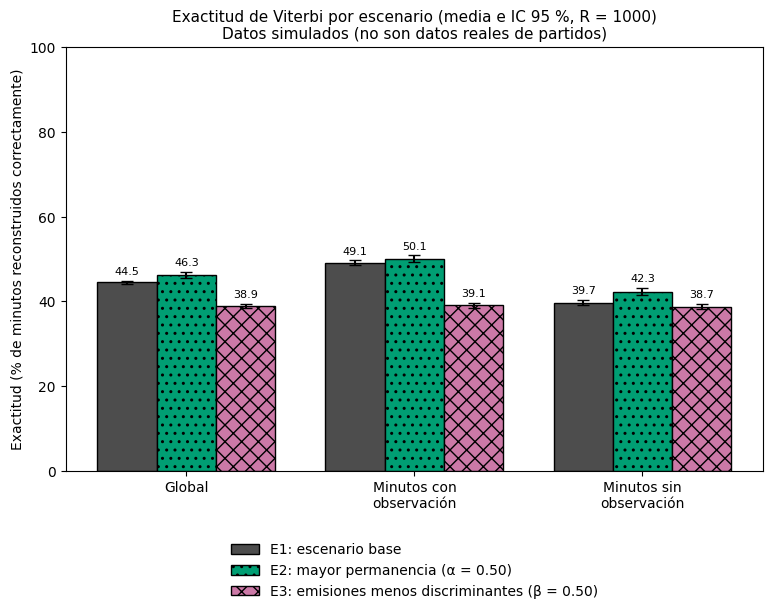

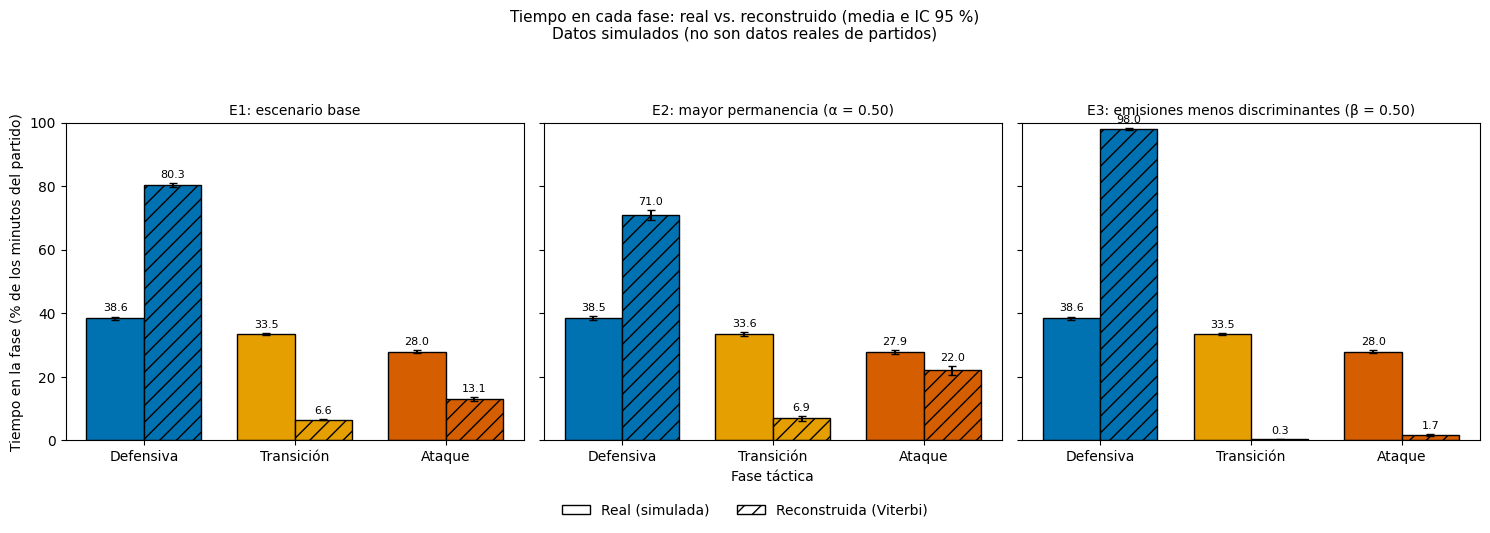

In [ ]:
# =============================================================================
# Proyecto: Análisis táctico de fútbol con un Modelo Oculto de Markov (HMM)
# Etapa 5: Métricas y visualizaciones del partido simulado
# Entorno: Google Colab (NumPy, Pandas y Matplotlib)
# =============================================================================

from dataclasses import dataclass
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# -----------------------------------------------------------------------------
# 1. Parámetros del HMM (escenario base, sin modificar)
# -----------------------------------------------------------------------------
ESTADOS = ("Defensiva", "Transición", "Ataque")        # S0, S1, S2
OBSERVACIONES = ("Pase corto", "Pase largo", "Tiro")   # O0, O1, O2

A_BASE = np.array([
    [0.60, 0.30, 0.10],   # desde Defensiva
    [0.30, 0.40, 0.30],   # desde Transición
    [0.20, 0.30, 0.50],   # desde Ataque
])

B_BASE = np.array([
    [0.70, 0.25, 0.05],   # emisiones en Defensiva
    [0.40, 0.50, 0.10],   # emisiones en Transición
    [0.30, 0.30, 0.40],   # emisiones en Ataque
])

PI_BASE = np.array([0.40, 0.40, 0.20])

TOL = 1e-9  # tolerancia absoluta para comprobar sumas iguales a 1


# -----------------------------------------------------------------------------
# 2. Clase HMM con validación matemática (Etapa 2, sin cambios)
# -----------------------------------------------------------------------------
@dataclass(frozen=True)
class HMM:
    """HMM discreto λ = (A, B, π).

    A  : matriz de transición (N x N), A[i, j] = P(S_{t+1}=j | S_t=i)
    B  : matriz de emisión    (N x M), B[i, k] = P(O_t=k | S_t=i)
    pi : distribución inicial (N,),    pi[i]  = P(S_1=i)

    Los arreglos internos son copias de solo lectura: no pueden modificarse
    accidentalmente después de crear el modelo.
    """
    A: np.ndarray
    B: np.ndarray
    pi: np.ndarray
    estados: tuple = ESTADOS
    observaciones: tuple = OBSERVACIONES

    def __post_init__(self):
        # Copias de tipo float, independientes de los arreglos originales.
        object.__setattr__(self, "A", np.array(self.A, dtype=float))
        object.__setattr__(self, "B", np.array(self.B, dtype=float))
        object.__setattr__(self, "pi", np.array(self.pi, dtype=float))
        self.validar()
        # Se bloquea la escritura solo cuando el modelo ya es válido.
        self.A.setflags(write=False)
        self.B.setflags(write=False)
        self.pi.setflags(write=False)

    @property
    def N(self) -> int:
        """Número de estados ocultos."""
        return self.A.shape[0]

    @property
    def M(self) -> int:
        """Número de observaciones distintas."""
        return self.B.shape[1]

    def validar(self) -> None:
        """Lanza ValueError si el modelo no cumple las propiedades requeridas."""
        N = len(self.estados)
        M = len(self.observaciones)

        # 1) Dimensiones
        if self.A.shape != (N, N):
            raise ValueError(f"A debe ser {N}x{N}; se recibió {self.A.shape}.")
        if self.B.shape != (N, M):
            raise ValueError(f"B debe ser {N}x{M}; se recibió {self.B.shape}.")
        if self.pi.shape != (N,):
            raise ValueError(f"pi debe tener longitud {N}; se recibió {self.pi.shape}.")

        # 2) Valores finitos y 3) no negativos
        for nombre, arr in (("A", self.A), ("B", self.B), ("pi", self.pi)):
            if not np.all(np.isfinite(arr)):
                raise ValueError(f"{nombre} contiene valores no finitos (NaN/inf).")
            if np.any(arr < 0):
                raise ValueError(f"{nombre} contiene probabilidades negativas.")

        # 4) Sumas iguales a 1 (rtol=0.0: solo se aplica la tolerancia absoluta)
        for nombre, arr in (("A", self.A), ("B", self.B)):
            sumas = arr.sum(axis=1)
            if not np.allclose(sumas, 1.0, rtol=0.0, atol=TOL):
                raise ValueError(f"Las filas de {nombre} deben sumar 1; suman {sumas}.")
        if not np.isclose(self.pi.sum(), 1.0, rtol=0.0, atol=TOL):
            raise ValueError(f"pi debe sumar 1; suma {self.pi.sum():.12f}.")

    def distribucion_estacionaria(self) -> np.ndarray:
        """Distribución π* que cumple π* A = π* (comportamiento a largo plazo).

        No representa los porcentajes exactos de un partido de 90 minutos.
        """
        valores, vectores = np.linalg.eig(self.A.T)
        k = np.argmin(np.abs(valores - 1.0))
        v = np.real(vectores[:, k])
        return v / v.sum()


def crear_modelo_base() -> HMM:
    """Devuelve el HMM del escenario base (parámetros originales)."""
    return HMM(A=A_BASE, B=B_BASE, pi=PI_BASE)


# -----------------------------------------------------------------------------
# 3. Parámetros de posesión (separados de A, B y π)
#    SUPUESTOS DEL MODELO, no estimados a partir de partidos reales.
# -----------------------------------------------------------------------------
EQUIPOS = ("Equipo A", "Equipo B")   # A = equipo analizado, B = rival
EQUIPO_A, EQUIPO_B = 0, 1
OBS_AUSENTE = -1                     # código de observación ausente
MINUTOS = 90
SEMILLA_BASE = 42


@dataclass(frozen=True)
class ParamsPosesion:
    """Cadena de Markov de dos estados para la posesión (independiente de la fase)."""
    p_inicial_A: float = 0.50    # P(el equipo A tiene el balón en el minuto 1)
    p_mantener_A: float = 0.70   # P(A conserva el balón | A lo tiene)
    p_mantener_B: float = 0.70   # P(B conserva el balón | B lo tiene)

    def __post_init__(self):
        for nombre in ("p_inicial_A", "p_mantener_A", "p_mantener_B"):
            valor = getattr(self, nombre)
            if not np.isfinite(valor) or not (0.0 <= valor <= 1.0):
                raise ValueError(f"{nombre} debe estar en [0, 1]; se recibió {valor}.")

    @property
    def pi_posesion(self) -> np.ndarray:
        """Distribución inicial de la posesión: [P(A), P(B)]."""
        return np.array([self.p_inicial_A, 1.0 - self.p_inicial_A])

    @property
    def matriz(self) -> np.ndarray:
        """Matriz de transición de la posesión (filas: quién tiene el balón ahora)."""
        return np.array([
            [self.p_mantener_A, 1.0 - self.p_mantener_A],   # desde A
            [1.0 - self.p_mantener_B, self.p_mantener_B],   # desde B
        ])


PARAMS_POSESION = ParamsPosesion()


# -----------------------------------------------------------------------------
# 4. Simulación del partido
# -----------------------------------------------------------------------------
@dataclass(frozen=True)
class Partido:
    """Resultado de simular un partido (arreglos de solo lectura)."""
    semilla: int
    estados: np.ndarray        # estado táctico real del equipo A (0, 1, 2)
    posesion: np.ndarray       # 0 = Equipo A, 1 = Equipo B
    observaciones: np.ndarray  # 0, 1, 2 con posesión de A; -1 si A no tiene el balón

    def __post_init__(self):
        # Copias independientes: el partido no comparte memoria con los arreglos
        # recibidos (que quedan intactos y modificables) y sus propios arreglos
        # son de solo lectura.
        for nombre in ("estados", "posesion", "observaciones"):
            copia = np.array(getattr(self, nombre), dtype=int)
            copia.setflags(write=False)
            object.__setattr__(self, nombre, copia)


def _validar_T(T) -> None:
    """T (número de minutos) debe ser un entero positivo."""
    if isinstance(T, bool) or not isinstance(T, (int, np.integer)) or T <= 0:
        raise ValueError(f"T debe ser un entero positivo; se recibió {T!r}.")


def _muestrear(rng: np.random.Generator, probs: np.ndarray) -> int:
    """Sortea un índice según el vector de probabilidades `probs`."""
    return int(rng.choice(len(probs), p=probs))


def simular_estados(modelo: HMM, T: int, rng: np.random.Generator) -> np.ndarray:
    """S_1 ~ π y S_{t+1} ~ A[S_t, :]."""
    _validar_T(T)
    estados = np.empty(T, dtype=int)
    estados[0] = _muestrear(rng, modelo.pi)
    for t in range(1, T):
        estados[t] = _muestrear(rng, modelo.A[estados[t - 1]])
    return estados


def simular_posesion(params: ParamsPosesion, T: int, rng: np.random.Generator) -> np.ndarray:
    """Cadena de Markov de dos estados, independiente de la fase táctica."""
    _validar_T(T)
    posesion = np.empty(T, dtype=int)
    posesion[0] = _muestrear(rng, params.pi_posesion)
    for t in range(1, T):
        posesion[t] = _muestrear(rng, params.matriz[posesion[t - 1]])
    return posesion


def simular_observaciones(modelo: HMM, estados: np.ndarray, posesion: np.ndarray,
                          rng: np.random.Generator) -> np.ndarray:
    """O_t ~ B[S_t, :] solo si el equipo A tiene el balón; si no, observación ausente (-1)."""
    _validar_T(len(estados))
    obs = np.full(len(estados), OBS_AUSENTE, dtype=int)
    for t in range(len(estados)):
        if posesion[t] == EQUIPO_A:
            obs[t] = _muestrear(rng, modelo.B[estados[t]])
    return obs


def validar_partido(modelo: HMM, p: Partido, T: int = MINUTOS) -> None:
    """Comprueba la consistencia de la simulación; lanza ValueError si falla."""
    if not (len(p.estados) == len(p.posesion) == len(p.observaciones) == T):
        raise ValueError(f"Las tres secuencias deben tener longitud {T}.")
    if not np.all(np.isin(p.estados, range(modelo.N))):
        raise ValueError("Hay estados fuera de rango.")
    if not np.all(np.isin(p.posesion, (EQUIPO_A, EQUIPO_B))):
        raise ValueError("Hay valores de posesión inválidos.")
    if not np.all(p.observaciones[p.posesion == EQUIPO_B] == OBS_AUSENTE):
        raise ValueError("Hay observaciones asignadas cuando A no tiene el balón.")
    if not np.all(np.isin(p.observaciones[p.posesion == EQUIPO_A], range(modelo.M))):
        raise ValueError("Hay observaciones ausentes o inválidas cuando A tiene el balón.")


def simular_partido(modelo: HMM, params_posesion: ParamsPosesion = PARAMS_POSESION,
                    semilla: int = SEMILLA_BASE, T: int = MINUTOS) -> Partido:
    """Simula un partido de T minutos (una acción por minuto).

    Una semilla maestra genera dos generadores independientes:
      - rng_hmm: estados ocultos y observaciones
      - rng_pos: posesión
    Orden: estados -> posesión -> observaciones (solo con posesión de A).
    """
    _validar_T(T)
    ss_hmm, ss_pos = np.random.SeedSequence(semilla).spawn(2)
    rng_hmm = np.random.default_rng(ss_hmm)
    rng_pos = np.random.default_rng(ss_pos)

    estados = simular_estados(modelo, T, rng_hmm)
    posesion = simular_posesion(params_posesion, T, rng_pos)
    observaciones = simular_observaciones(modelo, estados, posesion, rng_hmm)

    partido = Partido(semilla=semilla, estados=estados, posesion=posesion,
                      observaciones=observaciones)
    validar_partido(modelo, partido, T)
    return partido


# -----------------------------------------------------------------------------
# 5. Resumen y tabla de los primeros minutos
# -----------------------------------------------------------------------------
def resumen_partido(modelo: HMM, p: Partido) -> None:
    """Imprime un resumen descriptivo de la simulación (no son métricas finales)."""
    T = len(p.estados)
    print(f"Partido simulado: {T} minutos, semilla = {p.semilla}")
    print("(Datos simulados; no son datos reales de partidos.)\n")

    print("Minutos en cada fase táctica real del equipo A:")
    for i, nombre in enumerate(modelo.estados):
        n = int(np.sum(p.estados == i))
        print(f"  {nombre:<11}: {n:>2} min ({100 * n / T:5.1f} %)")

    print("\nPosesión:")
    for i, nombre in enumerate(EQUIPOS):
        n = int(np.sum(p.posesion == i))
        print(f"  {nombre}: {n:>2} min ({100 * n / T:5.1f} %)")

    con_obs = p.observaciones != OBS_AUSENTE
    print(f"\nObservaciones del equipo A: {int(con_obs.sum())} presentes, "
          f"{int((~con_obs).sum())} ausentes (-1)")
    for k, nombre in enumerate(modelo.observaciones):
        print(f"  {nombre:<10}: {int(np.sum(p.observaciones == k))}")


def tabla_primeros_minutos(modelo: HMM, p: Partido, n: int = 15) -> pd.DataFrame:
    """Tabla con los primeros n minutos de la simulación."""
    filas = []
    for t in range(n):
        o = p.observaciones[t]
        filas.append({
            "Minuto": t + 1,
            "Estado táctico real (A)": modelo.estados[p.estados[t]],
            "Posesión": EQUIPOS[p.posesion[t]],
            "Acción observada": "— (sin observación)" if o == OBS_AUSENTE
                                else modelo.observaciones[o],
        })
    return pd.DataFrame(filas).set_index("Minuto")


# -----------------------------------------------------------------------------
# 6. Algoritmo de Viterbi (en logaritmos, con observaciones ausentes)
# -----------------------------------------------------------------------------
def _log_seguro(x: np.ndarray) -> np.ndarray:
    """log(x) que devuelve -inf para x = 0, sin mostrar advertencias."""
    with np.errstate(divide="ignore"):
        return np.log(x)


def _log_emision(log_B: np.ndarray, o: int) -> np.ndarray:
    """Vector log e_j(o) para j = 0..N-1.

    Observación presente: log B[j, o].
    Observación ausente (-1): e_j = 1 para todo j, es decir log e_j = 0.
    """
    if o == OBS_AUSENTE:
        return np.zeros(log_B.shape[0])
    return log_B[:, o]


def _validar_observaciones(modelo: HMM, obs: np.ndarray) -> None:
    if obs.ndim != 1 or len(obs) == 0:
        raise ValueError("Las observaciones deben ser un arreglo 1D no vacío.")
    validas = (obs == OBS_AUSENTE) | ((obs >= 0) & (obs < modelo.M))
    if not np.all(validas):
        raise ValueError(f"Las observaciones deben ser -1 o enteros en 0..{modelo.M - 1}.")


def viterbi(modelo: HMM, observaciones) -> tuple:
    """Secuencia de estados más probable dada la secuencia de observaciones.

    Recursión (en log-probabilidades):
        delta_1(j) = log pi_j + log e_j(o_1)
        delta_t(j) = max_i [ delta_{t-1}(i) + log a_ij ] + log e_j(o_t)
        psi_t(j)   = argmax_i [ delta_{t-1}(i) + log a_ij ]
    con log e_j(o_t) = log B[j, o_t] si hay observación, y 0 si o_t = -1.

    Solo recibe las observaciones: no usa los estados reales ni la posesión.
    En caso de empate gana el estado de menor índice (comportamiento de argmax).

    Devuelve (camino, log_prob): el camino óptimo (array de enteros) y el
    logaritmo de la probabilidad conjunta de ese camino con las observaciones
    presentes.
    """
    obs = np.asarray(observaciones, dtype=int)
    _validar_observaciones(modelo, obs)
    T, N = len(obs), modelo.N

    log_pi = _log_seguro(modelo.pi)
    log_A = _log_seguro(modelo.A)
    log_B = _log_seguro(modelo.B)

    delta = np.empty((T, N))
    psi = np.zeros((T, N), dtype=int)

    delta[0] = log_pi + _log_emision(log_B, obs[0])
    for t in range(1, T):
        candidatos = delta[t - 1][:, None] + log_A      # candidatos[i, j]
        psi[t] = np.argmax(candidatos, axis=0)
        delta[t] = candidatos[psi[t], np.arange(N)] + _log_emision(log_B, obs[t])

    log_prob = float(delta[-1].max())
    if not np.isfinite(log_prob):
        raise ValueError("La secuencia de observaciones tiene probabilidad cero bajo el modelo.")

    # Retroceso (backtracking)
    camino = np.empty(T, dtype=int)
    camino[-1] = np.argmax(delta[-1])
    for t in range(T - 2, -1, -1):
        camino[t] = psi[t + 1, camino[t + 1]]
    return camino, log_prob


def log_prob_trayectoria(modelo: HMM, estados, observaciones) -> float:
    """log P(estados, observaciones presentes) para una trayectoria dada.

    Misma convención que Viterbi (observación ausente: emisión 1). Sirve para
    verificar que el camino de Viterbi no es peor que la trayectoria real.
    """
    est = np.asarray(estados, dtype=int)
    obs = np.asarray(observaciones, dtype=int)
    log_pi, log_A, log_B = (_log_seguro(modelo.pi), _log_seguro(modelo.A),
                            _log_seguro(modelo.B))
    lp = log_pi[est[0]] + _log_emision(log_B, obs[0])[est[0]]
    for t in range(1, len(est)):
        lp += log_A[est[t - 1], est[t]] + _log_emision(log_B, obs[t])[est[t]]
    return float(lp)


def reconstruir_estados(modelo: HMM, p: Partido) -> tuple:
    """Aplica Viterbi a las observaciones del partido (solo lectura en la salida)."""
    camino, log_prob = viterbi(modelo, p.observaciones)
    camino.setflags(write=False)
    return camino, log_prob


# -----------------------------------------------------------------------------
# 7. Comparación entre estados reales y reconstruidos (solo visual)
# -----------------------------------------------------------------------------
def tabla_comparacion(modelo: HMM, p: Partido, reconstruidos: np.ndarray,
                      n: int = 15) -> pd.DataFrame:
    """Tabla minuto a minuto: estado real vs. estado reconstruido por Viterbi."""
    filas = []
    for t in range(n):
        o = p.observaciones[t]
        filas.append({
            "Minuto": t + 1,
            "Posesión": EQUIPOS[p.posesion[t]],
            "Acción observada": "— (sin observación)" if o == OBS_AUSENTE
                                else modelo.observaciones[o],
            "Estado real": modelo.estados[p.estados[t]],
            "Estado reconstruido": modelo.estados[reconstruidos[t]],
            "Coincide": "✓" if p.estados[t] == reconstruidos[t] else "✗",
        })
    return pd.DataFrame(filas).set_index("Minuto")


# -----------------------------------------------------------------------------
# 8. Métricas
#    Se calculan sobre dos secuencias de estados, con propósitos distintos:
#      - REAL (simulada): describe lo que ocurrió de verdad en el partido simulado.
#      - RECONSTRUIDA (Viterbi): lo que un analista inferiría solo con las
#        observaciones. La diferencia entre ambas mide el error de la reconstrucción.
# -----------------------------------------------------------------------------
S_DEF, S_TRA, S_ATA = 0, 1, 2   # índices de las fases
OBS_TIRO = 2                    # índice de la observación "Tiro"


def _dividir(num: float, den: float) -> float:
    """num / den; devuelve NaN si el denominador es 0 (métrica no definida)."""
    return float(num) / float(den) if den > 0 else float("nan")


def contar_intentos_transicion(estados) -> tuple:
    """Intentos de transición: cada tramo continuo en S1 es UN intento.

    - Exitoso   : el tramo termina en S2 (alcanza el ataque antes de volver a S0).
    - Fallido   : el tramo termina en S0.
    - Incompleto: el partido termina mientras sigue en S1.
    - Si el partido empieza en S1, ese tramo inicial no cuenta como intento.
    - S2 -> S1 -> S2 cuenta como intento exitoso (definición aprobada).
    Devuelve (exitosos, fallidos, incompletos).
    """
    est = np.asarray(estados, dtype=int)
    T = len(est)
    exitosos = fallidos = incompletos = 0
    t = 0
    while t < T:
        if est[t] != S_TRA:
            t += 1
            continue
        inicio = t
        while t < T and est[t] == S_TRA:
            t += 1
        fin = t                      # primer minuto posterior al tramo en S1
        if inicio == 0:
            continue                 # el partido empieza en S1: no es un intento
        if fin == T:
            incompletos += 1
        elif est[fin] == S_ATA:
            exitosos += 1
        else:
            fallidos += 1
    return exitosos, fallidos, incompletos


def contar_defensa_ataque(estados) -> tuple:
    """Transiciones defensa -> ataque.

    Se cuenta cada llegada a S2 cuya última fase distinta de S1 fue S0
    (S0 -> S2 directa, o S0 -> S1 ... -> S2). S2 -> S1 -> S2 no cuenta.
    Devuelve (total, directas), donde directas son los saltos S0 -> S2 en un minuto.
    """
    est = np.asarray(estados, dtype=int)
    ultima = None            # última fase distinta de S1 (S0 o S2)
    total = directas = 0
    for t, s in enumerate(est):
        if s == S_ATA and t > 0 and est[t - 1] != S_ATA and ultima == S_DEF:
            total += 1
            if est[t - 1] == S_DEF:
                directas += 1
        if s != S_TRA:
            ultima = s
    return total, directas


def calcular_metricas(estados, p: Partido) -> dict:
    """Métricas del partido para una secuencia de estados (real o reconstruida).

    Porcentajes y eficiencia en escala 0-100. Si un denominador es 0, la
    métrica vale NaN (no definida).
    """
    est = np.asarray(estados, dtype=int)
    T = len(est)
    obs, pos = p.observaciones, p.posesion
    m = {}

    # Distribución temporal de fases
    for i in range(3):
        n = int(np.sum(est == i))
        m[f"min_{i}"] = n
        m[f"pct_{i}"] = 100.0 * _dividir(n, T)

    # Transiciones tácticas
    m["cambios_fase"] = int(np.sum(est[1:] != est[:-1]))
    m["def_ataque_total"], m["def_ataque_directas"] = contar_defensa_ataque(est)
    ex, fa, inc = contar_intentos_transicion(est)
    m["intentos_exitosos"], m["intentos_fallidos"], m["intentos_incompletos"] = ex, fa, inc
    m["intentos_total"] = ex + fa + inc
    m["eficiencia_transicion"] = 100.0 * _dividir(ex, ex + fa)   # incompletos excluidos

    # Tiros (solo los observados, es decir, con posesión del equipo A)
    es_tiro = obs == OBS_TIRO
    en_ataque = est == S_ATA
    m["tiros_total_obs"] = int(es_tiro.sum())
    m["tiros_en_ataque"] = int((es_tiro & en_ataque).sum())
    m["min_ataque_posesion"] = int((en_ataque & (pos == EQUIPO_A)).sum())
    m["tiros_x_min_ataque"] = _dividir(m["tiros_en_ataque"], m["min_2"])
    m["tiros_x_min_ataque_posesion"] = _dividir(m["tiros_en_ataque"], m["min_ataque_posesion"])
    return m


def calcular_exactitud(p: Partido, reconstruidos) -> dict:
    """Exactitud de Viterbi (% de minutos con el estado correcto): global,
    en minutos con observación y en minutos sin observación."""
    rec = np.asarray(reconstruidos, dtype=int)
    ok = p.estados == rec
    observado = p.observaciones != OBS_AUSENTE
    r = {
        "minutos_global": int(len(ok)), "aciertos_global": int(ok.sum()),
        "minutos_observados": int(observado.sum()), "aciertos_observados": int((ok & observado).sum()),
        "minutos_sin_obs": int((~observado).sum()), "aciertos_sin_obs": int((ok & ~observado).sum()),
    }
    r["exactitud_global"] = 100.0 * _dividir(r["aciertos_global"], r["minutos_global"])
    r["exactitud_observados"] = 100.0 * _dividir(r["aciertos_observados"], r["minutos_observados"])
    r["exactitud_sin_obs"] = 100.0 * _dividir(r["aciertos_sin_obs"], r["minutos_sin_obs"])
    return r


def matriz_confusion(reales, reconstruidos, N: int = 3) -> np.ndarray:
    """cm[i, j] = minutos con estado real i y estado reconstruido j."""
    cm = np.zeros((N, N), dtype=int)
    np.add.at(cm, (np.asarray(reales, dtype=int), np.asarray(reconstruidos, dtype=int)), 1)
    return cm


def verificar_coherencia_metricas(p: Partido, reconstruidos, m_real: dict, m_rec: dict,
                                  exact: dict, cm: np.ndarray) -> None:
    """Comprobaciones internas de consistencia; lanza ValueError si algo no cuadra."""
    T = len(p.estados)
    for nombre, m in (("real", m_real), ("reconstruida", m_rec)):
        if sum(m[f"min_{i}"] for i in range(3)) != T:
            raise ValueError(f"Los minutos por fase ({nombre}) no suman {T}.")
        if m["tiros_en_ataque"] > m["tiros_total_obs"]:
            raise ValueError(f"Hay más tiros en ataque que tiros totales ({nombre}).")
    if m_real["tiros_total_obs"] != m_rec["tiros_total_obs"]:
        raise ValueError("El total de tiros observados debe ser igual en ambas secuencias.")
    if cm.sum() != T or int(np.trace(cm)) != exact["aciertos_global"]:
        raise ValueError("La matriz de confusión no es coherente con la exactitud.")
    if exact["minutos_observados"] + exact["minutos_sin_obs"] != T:
        raise ValueError("Minutos observados + sin observación deben sumar el total.")
    if exact["aciertos_observados"] + exact["aciertos_sin_obs"] != exact["aciertos_global"]:
        raise ValueError("Los aciertos parciales deben sumar los aciertos globales.")


# --- Presentación de métricas -------------------------------------------------
def _num(v, decimales: int = 3, sufijo: str = "") -> str:
    """Formatea un número; muestra 'n/d' si la métrica no está definida (NaN)."""
    return "n/d" if np.isnan(v) else f"{v:.{decimales}f}{sufijo}"


def tabla_metricas(modelo: HMM, m_real: dict, m_rec: dict) -> pd.DataFrame:
    """Tabla comparativa: secuencia real vs. reconstruida por Viterbi."""
    filas = []
    for i, nombre in enumerate(modelo.estados):
        filas.append((f"Tiempo en {nombre} (min y %)",
                      lambda m, i=i: f"{m[f'min_{i}']} ({_num(m[f'pct_{i}'], 1)} %)"))
    filas += [
        ("Cambios de fase (n.º)", lambda m: f"{m['cambios_fase']}"),
        ("Transiciones defensa→ataque (n.º; directas S0→S2)",
         lambda m: f"{m['def_ataque_total']} ({m['def_ataque_directas']})"),
        ("Intentos de transición (n.º)", lambda m: f"{m['intentos_total']}"),
        ("   exitosos", lambda m: f"{m['intentos_exitosos']}"),
        ("   fallidos", lambda m: f"{m['intentos_fallidos']}"),
        ("   incompletos (fuera de la eficiencia)", lambda m: f"{m['intentos_incompletos']}"),
        ("Eficiencia de transición (%)", lambda m: _num(m["eficiencia_transicion"], 1)),
        ("Tiros observados en el partido (n.º)", lambda m: f"{m['tiros_total_obs']}"),
        ("Tiros observados durante Ataque (n.º)", lambda m: f"{m['tiros_en_ataque']}"),
        ("Minutos en Ataque / con posesión de A (min)",
         lambda m: f"{m['min_2']} / {m['min_ataque_posesion']}"),
        ("Tiros por minuto en Ataque (tiros/min)", lambda m: _num(m["tiros_x_min_ataque"])),
        ("Tiros por minuto en Ataque con posesión de A (tiros/min)",
         lambda m: _num(m["tiros_x_min_ataque_posesion"])),
    ]
    datos = {etiqueta: [f(m_real), f(m_rec)] for etiqueta, f in filas}
    return pd.DataFrame(datos, index=["Real (simulada)", "Reconstruida (Viterbi)"]).T


def imprimir_exactitud(e: dict) -> None:
    """Imprime la exactitud de la reconstrucción (global, observados y sin observación)."""
    print("Exactitud de la reconstrucción de Viterbi (% de minutos con estado correcto):")
    for etiqueta, a, n, x in (
        ("Global", "aciertos_global", "minutos_global", "exactitud_global"),
        ("Minutos con observación", "aciertos_observados", "minutos_observados", "exactitud_observados"),
        ("Minutos sin observación", "aciertos_sin_obs", "minutos_sin_obs", "exactitud_sin_obs"),
    ):
        print(f"  {etiqueta:<25}: {_num(e[x], 1):>5} %  ({e[a]}/{e[n]} min)")


def tabla_confusion(modelo: HMM, cm: np.ndarray) -> pd.DataFrame:
    """Matriz de confusión como tabla (filas: real; columnas: reconstruido)."""
    return pd.DataFrame(cm,
                        index=[f"Real: {e}" for e in modelo.estados],
                        columns=[f"Reconstruido: {e}" for e in modelo.estados])


# -----------------------------------------------------------------------------
# 9. Visualizaciones (se guardan como PNG en la carpeta CARPETA_SALIDA)
# -----------------------------------------------------------------------------
CARPETA_SALIDA = "resultados_etapa5"
DPI_FIGURAS = 300                                  # resolución de las imágenes guardadas
COLORES_FASE = ("#0072B2", "#E69F00", "#D55E00")   # Defensiva, Transición, Ataque
COLORES_EQUIPO = ("#009E73", "#7F7F7F")            # Equipo A, Equipo B
NOTA_SIMULADO = "Datos simulados (no son datos reales de partidos)"


def _guardar(fig, nombre: str) -> str:
    os.makedirs(CARPETA_SALIDA, exist_ok=True)
    ruta = os.path.join(CARPETA_SALIDA, nombre)
    fig.savefig(ruta, dpi=DPI_FIGURAS, bbox_inches="tight")
    return ruta


def _xticks(T: int) -> list:
    return [1] + list(range(10, T + 1, 10))


def graficar_linea_tiempo(modelo: HMM, p: Partido, reconstruidos) -> plt.Figure:
    """Línea de tiempo: fases reales, fases reconstruidas y minutos con observación."""
    T = len(p.estados)
    fig, ax = plt.subplots(figsize=(12, 3.8))
    for t in range(T):
        ax.barh(2, 1, left=t + 0.5, height=0.8, color=COLORES_FASE[p.estados[t]],
                edgecolor="white", linewidth=0.3)
        ax.barh(1, 1, left=t + 0.5, height=0.8, color=COLORES_FASE[reconstruidos[t]],
                edgecolor="white", linewidth=0.3)
        con_obs = p.observaciones[t] != OBS_AUSENTE
        ax.barh(0, 1, left=t + 0.5, height=0.4,
                color="#333333" if con_obs else "#DDDDDD", edgecolor="white", linewidth=0.3)
    ax.set_yticks([0, 1, 2])
    ax.set_yticklabels(["Observación\n(equipo A)", "Reconstruido\n(Viterbi)", "Real\n(simulado)"])
    ax.set_xlim(0.5, T + 0.5)
    ax.set_xticks(_xticks(T))
    ax.set_xlabel("Minuto del partido (min)")
    ax.set_title(f"Fases tácticas del equipo A: reales vs. reconstruidas (semilla {p.semilla})\n"
                 f"{NOTA_SIMULADO}", fontsize=11)
    handles = [Patch(color=COLORES_FASE[i], label=modelo.estados[i]) for i in range(3)]
    handles += [Patch(color="#333333", label="Con observación"),
                Patch(color="#DDDDDD", label="Sin observación (A sin balón)")]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=5, frameon=False)
    _guardar(fig, "01_linea_tiempo_fases.png")
    return fig


def graficar_acciones(modelo: HMM, p: Partido) -> plt.Figure:
    """Acciones observadas del equipo A minuto a minuto."""
    T = len(p.observaciones)
    minutos = np.arange(1, T + 1)
    fig, ax = plt.subplots(figsize=(12, 3.8))
    for t in np.where(p.observaciones == OBS_AUSENTE)[0]:
        ax.axvspan(t + 0.5, t + 1.5, color="#DDDDDD", zorder=0)
    estilos = (("o", "#56B4E9", 45), ("^", "#CC79A7", 55), ("*", "#000000", 170))
    for k, (marcador, color, tam) in enumerate(estilos):
        idx = p.observaciones == k
        ax.scatter(minutos[idx], np.full(int(idx.sum()), k), marker=marcador, color=color,
                   s=tam, label=f"{modelo.observaciones[k]} ({int(idx.sum())})", zorder=3)
    ax.set_yticks(range(modelo.M))
    ax.set_yticklabels(modelo.observaciones)
    ax.set_ylim(-0.6, modelo.M - 0.4)
    ax.set_xlim(0.5, T + 0.5)
    ax.set_xticks(_xticks(T))
    ax.set_xlabel("Minuto del partido (min)")
    ax.set_ylabel("Acción observada")
    ax.set_title(f"Acciones observadas del equipo A (semilla {p.semilla})\n{NOTA_SIMULADO}", fontsize=11)
    handles, _ = ax.get_legend_handles_labels()
    handles.append(Patch(color="#DDDDDD", label="Sin observación (A sin balón)"))
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=4, frameon=False)
    _guardar(fig, "02_acciones_observadas.png")
    return fig


def graficar_posesion(p: Partido) -> plt.Figure:
    """Posesión por minuto y posesión acumulada de ambos equipos."""
    T = len(p.posesion)
    minutos = np.arange(1, T + 1)
    pos_A = np.cumsum(p.posesion == EQUIPO_A) / minutos * 100.0
    pos_B = 100.0 - pos_A
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5.8), sharex=True,
                                   gridspec_kw={"height_ratios": [1, 2.6]})
    for t in range(T):
        ax1.barh(0, 1, left=t + 0.5, height=1.0, color=COLORES_EQUIPO[p.posesion[t]],
                 edgecolor="white", linewidth=0.3)
    ax1.set_yticks([])
    ax1.set_ylim(-0.5, 0.5)
    ax1.set_ylabel("Balón en\ncada minuto", rotation=0, ha="right", va="center")
    ax1.set_title(f"Evolución de la posesión (semilla {p.semilla})\n{NOTA_SIMULADO}", fontsize=11)
    ax2.set_title("Posesión acumulada hasta cada minuto", fontsize=10)
    ax2.plot(minutos, pos_A, color=COLORES_EQUIPO[0], lw=2, label="Equipo A (analizado; verde en la franja superior)")
    ax2.plot(minutos, pos_B, color=COLORES_EQUIPO[1], lw=2, label="Equipo B (rival; gris en la franja superior)")
    ax2.axhline(50, color="black", ls="--", lw=0.8, label="50 %")
    ax2.set_ylim(0, 100)
    ax2.set_xlim(0.5, T + 0.5)
    ax2.set_xticks(_xticks(T))
    ax2.set_xlabel("Minuto del partido (min)")
    ax2.set_ylabel("Posesión acumulada (% de minutos)")
    ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False)
    _guardar(fig, "03_evolucion_posesion.png")
    return fig


def graficar_matriz_confusion(modelo: HMM, cm: np.ndarray, semilla: int) -> plt.Figure:
    """Matriz de confusión (minutos) entre estados reales y reconstruidos."""
    N = cm.shape[0]
    fig, ax = plt.subplots(figsize=(6.4, 5.4))
    im = ax.imshow(cm, cmap="Blues", vmin=0)
    fig.colorbar(im, ax=ax).set_label("Minutos (min)")
    ax.set_xticks(range(N))
    ax.set_xticklabels(modelo.estados)
    ax.set_yticks(range(N))
    ax.set_yticklabels(modelo.estados)
    ax.set_xlabel("Estado reconstruido por Viterbi")
    ax.set_ylabel("Estado real (simulado)")
    umbral = cm.max() / 2 if cm.max() > 0 else 0
    for i in range(N):
        suma_fila = cm[i].sum()
        for j in range(N):
            pct = f"{100 * cm[i, j] / suma_fila:.0f} % de la fila" if suma_fila > 0 else "fila sin minutos"
            ax.text(j, i, f"{cm[i, j]} min\n{pct}", ha="center", va="center", fontsize=9,
                    color="white" if cm[i, j] > umbral else "black")
    ax.set_title(f"Matriz de confusión (semilla {semilla}, {int(cm.sum())} min)\n{NOTA_SIMULADO}",
                 fontsize=11)
    _guardar(fig, "04_matriz_confusion.png")
    return fig


def graficar_comparacion_fases(modelo: HMM, m_real: dict, m_rec: dict, semilla: int) -> plt.Figure:
    """Barras agrupadas: % de tiempo en cada fase, real vs. reconstruido (Viterbi)."""
    N = modelo.N
    x = np.arange(N)
    ancho = 0.38
    reales = [m_real[f"pct_{i}"] for i in range(N)]
    recons = [m_rec[f"pct_{i}"] for i in range(N)]
    fig, ax = plt.subplots(figsize=(8, 5))
    for i in range(N):
        ax.bar(x[i] - ancho / 2, reales[i], ancho, color=COLORES_FASE[i],
               edgecolor="black", linewidth=0.8)
        ax.bar(x[i] + ancho / 2, recons[i], ancho, color=COLORES_FASE[i],
               edgecolor="black", linewidth=0.8, hatch="//")
        for pos, valor in ((x[i] - ancho / 2, reales[i]), (x[i] + ancho / 2, recons[i])):
            if not np.isnan(valor):
                ax.text(pos, valor + 1.5, f"{valor:.1f} %", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(modelo.estados)
    ax.set_ylim(0, 100)
    ax.set_xlabel("Fase táctica")
    ax.set_ylabel("Tiempo en la fase (% de los minutos del partido)")
    ax.set_title(f"Tiempo en cada fase: real vs. reconstruido (semilla {semilla})\n{NOTA_SIMULADO}",
                 fontsize=11)
    ax.legend(handles=[Patch(facecolor="white", edgecolor="black", label="Real (simulada)"),
                       Patch(facecolor="white", edgecolor="black", hatch="//",
                             label="Reconstruida (Viterbi)")],
              loc="upper right", frameon=False)
    _guardar(fig, "05_comparacion_tiempo_fases.png")
    return fig

# =============================================================================
# ETAPA 6: Experimentación Monte Carlo
# Pegar DESPUÉS de la sección 9 de la Etapa 5 (la sección 10 se elimina).
# Reutiliza sin cambios HMM, simular_partido, viterbi, calcular_metricas, etc.
# =============================================================================
import time
from scipy import stats

# -----------------------------------------------------------------------------
# 11. Configuración aprobada de la Etapa 6
# -----------------------------------------------------------------------------
R_PARTIDOS = 1000              # partidos por escenario (aprobado: R = 1000)
SEMILLA_PRINCIPAL = 42         # semillas 42 + i, i = 0..R-1
SEMILLA_ALTERNA = 10042        # semillas 10042 + i
N_REPETICIONES = 3             # repeticiones del bloque principal (reproducibilidad)
NIVEL_CONFIANZA = 0.95
CARPETA_E6 = "resultados_etapa6"

ALFA = 0.50    # E2: A2 = (1 - ALFA) * A_BASE + ALFA * I
BETA = 0.50    # E3: B3 = (1 - BETA) * B_BASE + BETA * m,  m = PI_ESTACIONARIA @ B_BASE
PI_ESTACIONARIA = np.array([7/18, 1/3, 5/18])

A_E2 = (1.0 - ALFA) * A_BASE + ALFA * np.eye(3)
M_EMISION = PI_ESTACIONARIA @ B_BASE
B_E3 = (1.0 - BETA) * B_BASE + BETA * M_EMISION    # m se suma a cada fila (broadcasting)

ETIQUETAS_ESC = {
    "E1": "E1: escenario base",
    "E2": f"E2: mayor permanencia (α = {ALFA:.2f})",
    "E3": f"E3: emisiones menos discriminantes (β = {BETA:.2f})",
}
COLORES_ESC = {"E1": "#4D4D4D", "E2": "#009E73", "E3": "#CC79A7"}
HATCH_ESC = {"E1": None, "E2": "..", "E3": "xx"}


def verificar_configuracion_e6() -> None:
    """Comprueba que los parámetros construidos coinciden con los aprobados."""
    A2_aprobada = np.array([[0.80, 0.15, 0.05],
                            [0.15, 0.70, 0.15],
                            [0.10, 0.15, 0.75]])
    if not np.allclose(A_E2, A2_aprobada, rtol=0.0, atol=1e-12):
        raise ValueError("A_E2 no coincide con la matriz aprobada.")
    if not np.allclose(PI_ESTACIONARIA @ A_BASE, PI_ESTACIONARIA, rtol=0.0, atol=1e-12):
        raise ValueError("PI_ESTACIONARIA no cumple π A = π.")
    if not np.allclose(crear_modelo_base().distribucion_estacionaria(),
                       PI_ESTACIONARIA, rtol=0.0, atol=1e-9):
        raise ValueError("PI_ESTACIONARIA no coincide con la calculada numéricamente.")
    if not np.isclose(M_EMISION.sum(), 1.0, rtol=0.0, atol=1e-12):
        raise ValueError("m no es una distribución de probabilidad.")


def modelos_principales() -> dict:
    """E1, E2 y E3 (cada modelo se valida al construirse)."""
    return {
        "E1": crear_modelo_base(),
        "E2": HMM(A=A_E2, B=B_BASE, pi=PI_BASE),
        "E3": HMM(A=A_BASE, B=B_E3, pi=PI_BASE),
    }


# -----------------------------------------------------------------------------
# 12. Definición de las 27 métricas aprobadas y columnas auxiliares
#     1-10 : secuencia real          11-20: secuencia reconstruida (Viterbi)
#     21-23: exactitud (global, con observación, sin observación)
#     24-26: sesgo del % de tiempo por fase (reconstruido - real, en p. p.)
#     27   : sesgo de cambios de fase (reconstruido - real)
# -----------------------------------------------------------------------------
CLAVES_BASE = ("pct_0", "pct_1", "pct_2", "cambios_fase", "def_ataque_total",
               "intentos_total", "eficiencia_transicion", "tiros_total_obs",
               "tiros_x_min_ataque", "tiros_x_min_ataque_posesion")
NOMBRES_BASE = {
    "pct_0": "Tiempo en Defensiva (%)",
    "pct_1": "Tiempo en Transición (%)",
    "pct_2": "Tiempo en Ataque (%)",
    "cambios_fase": "Cambios de fase (n.º)",
    "def_ataque_total": "Transiciones defensa→ataque (n.º)",
    "intentos_total": "Intentos de transición (n.º)",
    "eficiencia_transicion": "Eficiencia de transición (%)",
    "tiros_total_obs": "Tiros observados (n.º)",
    "tiros_x_min_ataque": "Peligro 1: tiros/min en Ataque",
    "tiros_x_min_ataque_posesion": "Peligro 2: tiros/min en Ataque con posesión de A",
}
COLS_REAL = [f"real_{k}" for k in CLAVES_BASE]                       # 1-10
COLS_REC = [f"rec_{k}" for k in CLAVES_BASE]                         # 11-20
COLS_EXACTITUD = ["exactitud_global", "exactitud_observados", "exactitud_sin_obs"]  # 21-23
COLS_SESGO_PCT = ["sesgo_pct_0", "sesgo_pct_1", "sesgo_pct_2"]       # 24-26
COL_SESGO_CAMBIOS = "sesgo_cambios_fase"                             # 27
COLS_METRICAS = (COLS_REAL + COLS_REC + COLS_EXACTITUD + COLS_SESGO_PCT
                 + [COL_SESGO_CAMBIOS])
if len(COLS_METRICAS) != 27:
    raise ValueError("Deben ser 27 métricas.")
NUM_METRICA = {c: n for n, c in enumerate(COLS_METRICAS, start=1)}

# Columnas auxiliares para auditar los cálculos (no son métricas).
CLAVES_AUX = ("def_ataque_directas", "intentos_exitosos", "intentos_fallidos",
              "intentos_incompletos", "tiros_en_ataque", "min_ataque_posesion")
COLS_AUX = [f"{pref}_{k}" for pref in ("real", "rec") for k in CLAVES_AUX]

_NOMBRES_FASE = ("Defensiva", "Transición", "Ataque")
NOMBRES_METRICAS = {}
for _k in CLAVES_BASE:
    NOMBRES_METRICAS[f"real_{_k}"] = f"[Real] {NOMBRES_BASE[_k]}"
    NOMBRES_METRICAS[f"rec_{_k}"] = f"[Viterbi] {NOMBRES_BASE[_k]}"
NOMBRES_METRICAS.update({
    "exactitud_global": "Exactitud global (%)",
    "exactitud_observados": "Exactitud en minutos observados (%)",
    "exactitud_sin_obs": "Exactitud en minutos sin observación (%)",
    COL_SESGO_CAMBIOS: "Sesgo de cambios de fase (reconstruido − real, n.º)",
})
for _i, _f in enumerate(_NOMBRES_FASE):
    NOMBRES_METRICAS[f"sesgo_pct_{_i}"] = f"Sesgo % en {_f} (reconstruido − real, p. p.)"


def fila_partido(modelo: HMM, p: Partido) -> dict:
    """Reconstruye con Viterbi (usando el modelo del escenario) y devuelve las 27 métricas
    más las columnas auxiliares de un partido. Aplica las comprobaciones de coherencia."""
    rec, _ = reconstruir_estados(modelo, p)
    m_real = calcular_metricas(p.estados, p)
    m_rec = calcular_metricas(rec, p)
    ex = calcular_exactitud(p, rec)
    cm = matriz_confusion(p.estados, rec, modelo.N)
    verificar_coherencia_metricas(p, rec, m_real, m_rec, ex, cm)   # incluye tiros reales = reconstruidos

    f = {}
    for k in CLAVES_BASE:
        f[f"real_{k}"] = m_real[k]
    for k in CLAVES_BASE:
        f[f"rec_{k}"] = m_rec[k]
    for c in COLS_EXACTITUD:
        f[c] = ex[c]
    for i in range(3):
        f[f"sesgo_pct_{i}"] = m_rec[f"pct_{i}"] - m_real[f"pct_{i}"]
    f[COL_SESGO_CAMBIOS] = m_rec["cambios_fase"] - m_real["cambios_fase"]
    for pref, m in (("real", m_real), ("rec", m_rec)):
        for k in CLAVES_AUX:
            f[f"{pref}_{k}"] = m[k]
    return f


# -----------------------------------------------------------------------------
# 13. Ejecución de bloques Monte Carlo
# -----------------------------------------------------------------------------
def ejecutar_bloque(modelos: dict, semilla_base: int, etiqueta: str,
                    R: int = R_PARTIDOS, estados_iguales: tuple = None,
                    verbose: bool = True) -> pd.DataFrame:
    """R partidos por modelo con semillas semilla_base + i (las mismas en todos los modelos).

    Controles de pareamiento en cada semilla: la posesión debe ser idéntica entre
    modelos y, si se indica `estados_iguales=(a, b)`, los estados reales de a y b
    también (E1 y E3, porque A no cambia).
    """
    t0 = time.perf_counter()
    nombres = list(modelos)
    filas = []
    for i in range(R):
        semilla = semilla_base + i
        partidos = {n: simular_partido(modelos[n], PARAMS_POSESION, semilla=semilla)
                    for n in nombres}
        for n in nombres[1:]:
            if not np.array_equal(partidos[n].posesion, partidos[nombres[0]].posesion):
                raise ValueError(f"La posesión difiere entre {nombres[0]} y {n} (semilla {semilla}).")
        if estados_iguales is not None:
            a, b = estados_iguales
            if not np.array_equal(partidos[a].estados, partidos[b].estados):
                raise ValueError(f"Los estados de {a} y {b} difieren (semilla {semilla}).")
        for n in nombres:
            fila = {"bloque": etiqueta, "escenario": n, "i": i, "semilla": semilla}
            fila.update(fila_partido(modelos[n], partidos[n]))
            filas.append(fila)
    if verbose:
        print(f"  bloque '{etiqueta}': {R} semillas x {len(nombres)} modelo(s) "
              f"en {time.perf_counter() - t0:.1f} s")
    return pd.DataFrame(filas)


# -----------------------------------------------------------------------------
# 14. Estadística: IC t de Student, diferencias pareadas y Welch-Satterthwaite
#     Los NaN se excluyen y se cuentan; nunca se convierten en cero.
# -----------------------------------------------------------------------------
def _t_critico(gl: float) -> float:
    return float(stats.t.ppf(0.5 + NIVEL_CONFIANZA / 2.0, gl))


def _es_constante(x: np.ndarray) -> bool:
    return len(x) > 0 and bool(np.all(x == x[0]))


def estadisticos_t(valores) -> dict:
    """n válido, media, DE muestral, mín, máx e IC 95 % (t de Student) de la media.

    n < 2: DE e IC no definidos (NaN). DE = 0: IC degenerado en la media.
    """
    x = np.asarray(valores, dtype=float)
    x = x[~np.isnan(x)]
    n = len(x)
    r = {"n_validos": n, "media": np.nan, "sd": np.nan, "min": np.nan,
         "max": np.nan, "ic_inf": np.nan, "ic_sup": np.nan}
    if n == 0:
        return r
    r["min"], r["max"] = float(x.min()), float(x.max())
    if _es_constante(x):
        r["media"] = float(x[0])
        if n >= 2:
            r["sd"] = 0.0
            r["ic_inf"] = r["ic_sup"] = r["media"]
        return r
    r["media"] = float(x.mean())
    if n < 2:
        return r
    r["sd"] = float(x.std(ddof=1))
    h = _t_critico(n - 1) * r["sd"] / np.sqrt(n)
    r["ic_inf"], r["ic_sup"] = r["media"] - h, r["media"] + h
    return r


def _contiene_cero(inf: float, sup: float) -> str:
    if np.isnan(inf) or np.isnan(sup):
        return "n/d"
    return "sí" if inf <= 0.0 <= sup else "no"


def resumen_descriptivo(df: pd.DataFrame, columnas=COLS_METRICAS) -> pd.DataFrame:
    """Tabla por escenario y métrica: media, DE, mín, máx, IC 95 % y n válido."""
    filas = []
    for esc, g in df.groupby("escenario", sort=False):
        for col in columnas:
            e = estadisticos_t(g[col].to_numpy(dtype=float))
            filas.append({"escenario": esc, "n_metrica": NUM_METRICA.get(col, 0),
                          "metrica": col, "etiqueta": NOMBRES_METRICAS.get(col, col),
                          "n_total": len(g), "n_excluidos_nan": len(g) - e["n_validos"], **e})
    return pd.DataFrame(filas)


def comparacion_pareada(df: pd.DataFrame, ref: str, esc: str, columnas=COLS_METRICAS) -> pd.DataFrame:
    """Diferencias pareadas d_i = X_i(esc) - X_i(ref) con IC 95 % t de Student.
    Se excluyen los pares con NaN en cualquiera de los dos valores."""
    a = df[df["escenario"] == ref].set_index("i").sort_index()
    b = df[df["escenario"] == esc].set_index("i").sort_index()
    if not a.index.equals(b.index):
        raise ValueError("Las semillas de los dos escenarios no coinciden.")
    filas = []
    for col in columnas:
        d = b[col].to_numpy(dtype=float) - a[col].to_numpy(dtype=float)   # NaN si alguno es NaN
        e = estadisticos_t(d)
        filas.append({"comparacion": f"{esc} − {ref}", "n_metrica": NUM_METRICA.get(col, 0),
                      "metrica": col, "etiqueta": NOMBRES_METRICAS.get(col, col),
                      "n_pares": len(d), "n_pares_validos": e["n_validos"],
                      "n_excluidos": len(d) - e["n_validos"],
                      "media_dif": e["media"], "sd_dif": e["sd"],
                      "ic_inf": e["ic_inf"], "ic_sup": e["ic_sup"],
                      "ic_contiene_0": _contiene_cero(e["ic_inf"], e["ic_sup"])})
    return pd.DataFrame(filas)


def _welch(x: np.ndarray, y: np.ndarray) -> dict:
    """Diferencia de medias y - x con IC 95 % de Welch-Satterthwaite (x, y sin NaN)."""
    r = {"n_x": len(x), "n_y": len(y), "media_x": np.nan, "media_y": np.nan,
         "dif": np.nan, "ee": np.nan, "gl": np.nan, "ic_inf": np.nan, "ic_sup": np.nan}
    if len(x) > 0:
        r["media_x"] = float(x.mean())
    if len(y) > 0:
        r["media_y"] = float(y.mean())
    if len(x) < 2 or len(y) < 2:
        return r
    r["dif"] = r["media_y"] - r["media_x"]
    vx = 0.0 if _es_constante(x) else float(x.var(ddof=1)) / len(x)
    vy = 0.0 if _es_constante(y) else float(y.var(ddof=1)) / len(y)
    ee2 = vx + vy
    r["ee"] = float(np.sqrt(ee2))
    if ee2 == 0.0:                       # ambas muestras constantes: IC degenerado
        r["ic_inf"] = r["ic_sup"] = r["dif"]
        return r
    gl = ee2 ** 2 / (vx ** 2 / (len(x) - 1) + vy ** 2 / (len(y) - 1))
    r["gl"] = float(gl)
    h = _t_critico(gl) * r["ee"]
    r["ic_inf"], r["ic_sup"] = r["dif"] - h, r["dif"] + h
    return r


def comparacion_welch(df_x: pd.DataFrame, df_y: pd.DataFrame, columnas=COLS_METRICAS) -> pd.DataFrame:
    """Bloque alterno (y) menos bloque principal (x), por escenario y métrica."""
    filas = []
    for esc in df_x["escenario"].unique():
        gx = df_x[df_x["escenario"] == esc]
        gy = df_y[df_y["escenario"] == esc]
        for col in columnas:
            x = gx[col].to_numpy(dtype=float)
            y = gy[col].to_numpy(dtype=float)
            w = _welch(x[~np.isnan(x)], y[~np.isnan(y)])
            filas.append({"escenario": esc, "n_metrica": NUM_METRICA.get(col, 0),
                          "metrica": col, "etiqueta": NOMBRES_METRICAS.get(col, col),
                          "n_principal": w["n_x"], "n_alterno": w["n_y"],
                          "media_principal": w["media_x"], "media_alterno": w["media_y"],
                          "dif_alterno_menos_principal": w["dif"], "error_estandar": w["ee"],
                          "gl_welch": w["gl"], "ic_inf": w["ic_inf"], "ic_sup": w["ic_sup"],
                          "ic_contiene_0": _contiene_cero(w["ic_inf"], w["ic_sup"])})
    return pd.DataFrame(filas)


# -----------------------------------------------------------------------------
# 15. Sensibilidad de π: referencia analítica
#     Distribución esperada en el minuto t: π A^(t-1).
# -----------------------------------------------------------------------------
def referencia_analitica_pi(modelo: HMM, pi0: np.ndarray, T: int = MINUTOS) -> pd.DataFrame:
    """π A^(t-1) para t = 1..T y distancia de variación total a π estacionaria."""
    dist = np.empty((T, modelo.N))
    dist[0] = pi0
    for t in range(1, T):
        dist[t] = dist[t - 1] @ modelo.A
    tv = 0.5 * np.abs(dist - PI_ESTACIONARIA).sum(axis=1)
    return pd.DataFrame({"minuto": np.arange(1, T + 1), "p_defensiva": dist[:, 0],
                         "p_transicion": dist[:, 1], "p_ataque": dist[:, 2],
                         "tv_estacionaria": tv})


def tabla_tiempo_esperado(modelo: HMM, refs: dict, desc_pi: pd.DataFrame) -> pd.DataFrame:
    """Tiempo esperado analítico (suma de π A^(t-1)) frente al promedio simulado (secuencia real)."""
    filas = []
    for nombre, ref in refs.items():
        esperado = ref[["p_defensiva", "p_transicion", "p_ataque"]].sum().to_numpy()
        for i, fase in enumerate(modelo.estados):
            s = desc_pi[(desc_pi["escenario"] == nombre)
                        & (desc_pi["metrica"] == f"real_pct_{i}")].iloc[0]
            pct_esp = 100.0 * esperado[i] / MINUTOS
            dentro = ("n/d" if np.isnan(s["ic_inf"])
                      else ("sí" if s["ic_inf"] <= pct_esp <= s["ic_sup"] else "no"))
            filas.append({"configuracion": nombre, "fase": fase,
                          "esperado_min": esperado[i], "esperado_pct": pct_esp,
                          "simulado_pct_media": s["media"], "simulado_ic_inf": s["ic_inf"],
                          "simulado_ic_sup": s["ic_sup"],
                          "diferencia_pct": s["media"] - pct_esp, "esperado_dentro_ic": dentro})
    return pd.DataFrame(filas)


# -----------------------------------------------------------------------------
# 16. Reproducibilidad con las mismas semillas
# -----------------------------------------------------------------------------
def reproducibilidad_semillas_iguales(modelos: dict, df_ref: pd.DataFrame,
                                      desc_ref: pd.DataFrame) -> pd.DataFrame:
    """Repite el bloque principal N_REPETICIONES veces y compara con el original
    (igualdad exacta de la tabla por partido y de la tabla descriptiva)."""
    filas = []
    for r in range(1, N_REPETICIONES + 1):
        df_r = ejecutar_bloque(modelos, SEMILLA_PRINCIPAL, "principal",
                               estados_iguales=("E1", "E3"), verbose=False)
        filas.append({"repeticion": r,
                      "tabla_por_partido_identica": bool(df_r.equals(df_ref)),
                      "tabla_descriptiva_identica": bool(resumen_descriptivo(df_r).equals(desc_ref))})
    return pd.DataFrame(filas)


# -----------------------------------------------------------------------------
# 17. Gráficas y utilidades de salida
# -----------------------------------------------------------------------------
def _guardar_e6(fig, nombre: str) -> str:
    os.makedirs(CARPETA_E6, exist_ok=True)
    ruta = os.path.join(CARPETA_E6, nombre)
    fig.savefig(ruta, dpi=DPI_FIGURAS, bbox_inches="tight")
    return ruta


def guardar_csv(df: pd.DataFrame, nombre: str) -> None:
    os.makedirs(CARPETA_E6, exist_ok=True)
    df.to_csv(os.path.join(CARPETA_E6, nombre), index=False, na_rep="NaN", encoding="utf-8")


def graficar_exactitud_escenarios(desc: pd.DataFrame) -> plt.Figure:
    """Exactitud de Viterbi por escenario con IC 95 % de la media."""
    idx = desc.set_index(["escenario", "metrica"])
    etiquetas = ("Global", "Minutos con\nobservación", "Minutos sin\nobservación")
    escenarios = list(ETIQUETAS_ESC)
    ancho = 0.26
    x = np.arange(len(COLS_EXACTITUD))
    fig, ax = plt.subplots(figsize=(9, 5.5))
    for j, esc in enumerate(escenarios):
        medias = np.array([idx.loc[(esc, c), "media"] for c in COLS_EXACTITUD], dtype=float)
        err = np.array([(idx.loc[(esc, c), "ic_sup"] - idx.loc[(esc, c), "ic_inf"]) / 2.0
                        for c in COLS_EXACTITUD], dtype=float)
        pos = x + (j - 1) * ancho
        ax.bar(pos, medias, ancho, yerr=err, capsize=4, color=COLORES_ESC[esc],
               edgecolor="black", hatch=HATCH_ESC[esc], label=ETIQUETAS_ESC[esc])
        for xp, m, e in zip(pos, medias, err):
            if not (np.isnan(m) or np.isnan(e)):
                ax.text(xp, m + e + 1.0, f"{m:.1f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(etiquetas)
    ax.set_ylim(0, 100)
    ax.set_ylabel("Exactitud (% de minutos reconstruidos correctamente)")
    n = int(desc["n_total"].iloc[0])
    ax.set_title(f"Exactitud de Viterbi por escenario (media e IC 95 %, R = {n})\n{NOTA_SIMULADO}",
                 fontsize=11)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=1, frameon=False)
    _guardar_e6(fig, "01_exactitud_por_escenario.png")
    return fig


def graficar_tiempo_fases_escenarios(desc: pd.DataFrame) -> plt.Figure:
    """% de tiempo por fase, real frente a reconstruido, con IC 95 % de la media, por escenario."""
    idx = desc.set_index(["escenario", "metrica"])
    ancho = 0.38
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), sharey=True)
    for ax, esc in zip(axes, ETIQUETAS_ESC):
        for i in range(3):
            for pref, hatch, off in (("real", None, -ancho / 2), ("rec", "//", ancho / 2)):
                f = idx.loc[(esc, f"{pref}_pct_{i}")]
                err = (f["ic_sup"] - f["ic_inf"]) / 2.0
                ax.bar(i + off, f["media"], ancho, yerr=err, capsize=3, color=COLORES_FASE[i],
                       edgecolor="black", hatch=hatch)
                if not (np.isnan(f["media"]) or np.isnan(err)):
                    ax.text(i + off, f["media"] + err + 1.0, f"{f['media']:.1f}",
                            ha="center", va="bottom", fontsize=8)
        ax.set_xticks(range(3))
        ax.set_xticklabels(_NOMBRES_FASE)
        ax.set_ylim(0, 100)
        ax.set_title(ETIQUETAS_ESC[esc], fontsize=10)
    axes[0].set_ylabel("Tiempo en la fase (% de los minutos del partido)")
    axes[1].set_xlabel("Fase táctica")
    fig.suptitle(f"Tiempo en cada fase: real vs. reconstruido (media e IC 95 %)\n{NOTA_SIMULADO}",
                 fontsize=11)
    fig.legend(handles=[Patch(facecolor="white", edgecolor="black", label="Real (simulada)"),
                        Patch(facecolor="white", edgecolor="black", hatch="//",
                              label="Reconstruida (Viterbi)")],
               loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.02))
    fig.tight_layout(rect=(0, 0.04, 1, 0.92))
    _guardar_e6(fig, "02_tiempo_fases_por_escenario.png")
    return fig


def _fmt(v, d: int = 3) -> str:
    return "n/d" if pd.isna(v) else f"{v:.{d}f}"


def imprimir_descriptivo(desc: pd.DataFrame, titulo: str) -> None:
    print(f"\n{titulo}")
    for esc, g in desc.groupby("escenario", sort=False):
        print(f"\n[{ETIQUETAS_ESC.get(esc, esc)}]  (partidos simulados: {int(g['n_total'].iloc[0])})")
        t = pd.DataFrame({
            "Métrica": g["etiqueta"].values,
            "Media": [_fmt(v) for v in g["media"]],
            "DE": [_fmt(v) for v in g["sd"]],
            "Mín": [_fmt(v) for v in g["min"]],
            "Máx": [_fmt(v) for v in g["max"]],
            "IC 95 %": [f"[{_fmt(a)}, {_fmt(b)}]" for a, b in zip(g["ic_inf"], g["ic_sup"])],
            "n válido": g["n_validos"].values,
            "Excl.": g["n_excluidos_nan"].values,
        }, index=pd.Index(g["n_metrica"].values, name="n.º"))
        print(t.to_string())


def imprimir_comparaciones(comp: pd.DataFrame, titulo: str) -> None:
    print(f"\n{titulo}")
    for nombre, g in comp.groupby("comparacion", sort=False):
        print(f"\n[{nombre}]  diferencia pareada media, IC 95 % (t de Student)")
        t = pd.DataFrame({
            "Métrica": g["etiqueta"].values,
            "Dif. media": [_fmt(v) for v in g["media_dif"]],
            "DE dif.": [_fmt(v) for v in g["sd_dif"]],
            "IC 95 %": [f"[{_fmt(a)}, {_fmt(b)}]" for a, b in zip(g["ic_inf"], g["ic_sup"])],
            "Pares válidos": g["n_pares_validos"].values,
            "Excl.": g["n_excluidos"].values,
            "¿0 en IC?": g["ic_contiene_0"].values,
        }, index=pd.Index(g["n_metrica"].values, name="n.º"))
        print(t.to_string())


# -----------------------------------------------------------------------------
# 18. Ejecución de la Etapa 6
# -----------------------------------------------------------------------------
print("=" * 78)
print("ETAPA 6: Monte Carlo (datos simulados; no son datos reales de partidos)")
print("=" * 78)
verificar_configuracion_e6()
modelos = modelos_principales()
print("Configuración verificada. Matrices de los escenarios modificados:")
print("A (E2) =\n", np.round(A_E2, 4))
print("m = π* B =", np.round(M_EMISION, 5))
print("B (E3) =\n", np.round(B_E3, 5))
print(f"\nR = {R_PARTIDOS} partidos por escenario; semillas {SEMILLA_PRINCIPAL} + i.\n")

# --- 18.1 Bloque principal: E1, E2, E3 (semillas y posesión comunes) ------------
print("Bloque principal:")
df_principal = ejecutar_bloque(modelos, SEMILLA_PRINCIPAL, "principal",
                               estados_iguales=("E1", "E3"))
print(f"  Controles de pareamiento superados en las {R_PARTIDOS} semillas: "
      f"posesión idéntica en E1, E2 y E3; estados reales de E3 = estados de E1.")
desc_principal = resumen_descriptivo(df_principal)
comparaciones = pd.concat([comparacion_pareada(df_principal, "E1", "E2"),
                           comparacion_pareada(df_principal, "E1", "E3")], ignore_index=True)
imprimir_descriptivo(desc_principal, "RESULTADOS DESCRIPTIVOS POR ESCENARIO")
imprimir_comparaciones(comparaciones, "COMPARACIONES PAREADAS FRENTE A E1 (análisis exploratorio conjunto, "
                       "sin corrección por comparaciones múltiples)")

# --- 18.2 Sensibilidad de π (A y B originales) ---------------------------------
print("\nSensibilidad de la distribución inicial π:")
modelo_pi_est = HMM(A=A_BASE, B=B_BASE, pi=PI_ESTACIONARIA)   # Viterbi usa la misma π que simula
df_pi_est = ejecutar_bloque({"π estacionaria": modelo_pi_est}, SEMILLA_PRINCIPAL, "pi")
# π original = E1 (mismos A, B, π y semillas): se reutilizan sus filas.
df_pi_orig = df_principal[df_principal["escenario"] == "E1"].copy()
df_pi_orig["escenario"] = "π original"
df_pi_orig["bloque"] = "pi"
df_pi = pd.concat([df_pi_orig, df_pi_est], ignore_index=True)
desc_pi = resumen_descriptivo(df_pi)
comp_pi = comparacion_pareada(df_pi, "π original", "π estacionaria")
imprimir_comparaciones(comp_pi, "SENSIBILIDAD DE π: diferencias pareadas (π estacionaria − π original)")

refs_pi = {"π original": referencia_analitica_pi(modelos["E1"], PI_BASE),
           "π estacionaria": referencia_analitica_pi(modelos["E1"], PI_ESTACIONARIA)}
tiempo_esperado = tabla_tiempo_esperado(modelos["E1"], refs_pi, desc_pi)
print("\nReferencia analítica: tiempo esperado por fase (suma de π A^(t-1), 90 min) "
      "frente al promedio simulado de la secuencia real")
print(tiempo_esperado.to_string(index=False, na_rep="n/d",
                                float_format=lambda v: f"{v:.3f}"))
tv = refs_pi["π original"].set_index("minuto")["tv_estacionaria"]
minutos_tv = [1, 2, 3, 5, 10, 20, 30, 45, 90]
print("\nDistancia de variación total entre π A^(t-1) (π original) y π estacionaria:")
print(pd.DataFrame({"Minuto": minutos_tv,
                    "Variación total": [f"{tv[m]:.5f}" for m in minutos_tv]}).to_string(index=False))

# --- 18.3 Reproducibilidad con las mismas semillas -----------------------------
print(f"\nReproducibilidad (mismas semillas): {N_REPETICIONES} repeticiones del bloque principal...")
repro_iguales = reproducibilidad_semillas_iguales(modelos, df_principal, desc_principal)
print(repro_iguales.to_string(index=False))

# --- 18.4 Reproducibilidad con semillas alternativas (10042 + i) ---------------
print("\nBloque con semillas alternativas:")
df_alterno = ejecutar_bloque(modelos, SEMILLA_ALTERNA, "alterno", estados_iguales=("E1", "E3"))
desc_alterno = resumen_descriptivo(df_alterno)
welch = comparacion_welch(df_principal, df_alterno)
print("\nComparación de medias (alterno − principal), IC 95 % de Welch-Satterthwaite.")
print("Si el IC contiene 0 se expresa 'no se detectó diferencia estadística' (no equivalencia).")
resumen_welch = (welch.groupby("escenario", sort=False)["ic_contiene_0"]
                 .value_counts().unstack(fill_value=0))
print(resumen_welch.to_string())
fuera = welch[welch["ic_contiene_0"] == "no"]
if len(fuera):
    print("\nMétricas cuyo IC de Welch NO contiene 0:")
    t = pd.DataFrame({"Esc.": fuera["escenario"].values, "Métrica": fuera["etiqueta"].values,
                      "Dif. (alt − princ.)": [_fmt(v) for v in fuera["dif_alterno_menos_principal"]],
                      "IC 95 %": [f"[{_fmt(a)}, {_fmt(b)}]" for a, b in zip(fuera["ic_inf"], fuera["ic_sup"])]},
                     index=pd.Index(fuera["n_metrica"].values, name="n.º"))
    print(t.to_string())
else:
    print("Ninguna métrica tiene un IC de Welch que excluya 0.")
print("(Tabla completa en e6_reproducibilidad_semillas_alternas_welch.csv)")

# --- 18.5 Gráficas ---------------------------------------------------------------
graficar_exactitud_escenarios(desc_principal)
graficar_tiempo_fases_escenarios(desc_principal)

# --- 18.6 Archivos CSV para la Etapa 7 --------------------------------------------
ref_csv = pd.concat([r.assign(configuracion=n) for n, r in refs_pi.items()], ignore_index=True)
guardar_csv(pd.concat([df_principal, df_alterno, df_pi_est], ignore_index=True),
            "e6_resultados_por_partido.csv")
guardar_csv(desc_principal, "e6_descriptivo_principal.csv")
guardar_csv(desc_alterno, "e6_descriptivo_alterno.csv")
guardar_csv(comparaciones, "e6_comparaciones_pareadas.csv")
guardar_csv(desc_pi, "e6_sensibilidad_pi_descriptivo.csv")
guardar_csv(comp_pi, "e6_sensibilidad_pi_pareada.csv")
guardar_csv(ref_csv, "e6_pi_referencia_analitica_por_minuto.csv")
guardar_csv(tiempo_esperado, "e6_pi_tiempo_esperado.csv")
guardar_csv(repro_iguales, "e6_reproducibilidad_semillas_iguales.csv")
guardar_csv(welch, "e6_reproducibilidad_semillas_alternas_welch.csv")
print(f"\nGráficas ({DPI_FIGURAS} dpi) y 10 archivos CSV guardados en '{CARPETA_E6}/'.")
plt.show()